In [ ]:
import os
import pandas as pd
import polars as pl
import numpy as np
import torch
import torch.nn as nn
import glob
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

# LOCAL VERSION - Remove Kaggle-specific imports
# import kaggle_evaluation.nfl_inference_server

# Constants - Update for local paths
DATA_DIR = "./train"  # Update this to your local data path
FIELD_X, FIELD_Y = 120.0, 53.3
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

# ============================================================================
# MODEL ARCHITECTURE
# ============================================================================

class FrameGraphModule(nn.Module):
    def __init__(self, feat_dim, hidden_dim):
        super().__init__()
        self.intra_team_fc = nn.Linear(feat_dim, hidden_dim)
        self.bipartite_fc = nn.Linear(feat_dim, hidden_dim)
        self.to_landing_fc = nn.Linear(feat_dim, hidden_dim)
        self.out_fc = nn.Linear(hidden_dim * 3, feat_dim)

    def forward(self, x, adj_intra, adj_bipartite, adj_to_landing):
        intra_msg = torch.matmul(adj_intra, self.intra_team_fc(x))
        bip_msg = torch.matmul(adj_bipartite, self.bipartite_fc(x))
        landing_msg = torch.matmul(adj_to_landing, self.to_landing_fc(x))
        combined = torch.cat([intra_msg, bip_msg, landing_msg], dim=-1)
        return self.out_fc(combined) + x

class Seq2SeqGraphTransformer(nn.Module):
    def __init__(self, feat_dim, hidden_dim, n_heads=4, n_layers=2):
        super().__init__()
        self.frame_graph = FrameGraphModule(feat_dim, hidden_dim)
        
        base_d_model = 22 * feat_dim
        self.d_model = (base_d_model // n_heads) * n_heads
        
        self.need_projection = (base_d_model != self.d_model)
        if self.need_projection:
            self.input_proj = nn.Linear(base_d_model, self.d_model)
            self.output_unproj = nn.Linear(self.d_model, base_d_model)
        
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.d_model, 
            nhead=n_heads, 
            dim_feedforward=self.d_model * 4,
            batch_first=True,
            dropout=0.1
        )
        self.temporal_encoder = nn.TransformerEncoder(encoder_layer, num_layers=n_layers)
        self.feat_dim = feat_dim
        
        self.output_proj = nn.Linear(base_d_model, 22*2)
        self.state_update = nn.GRUCell(22*2, base_d_model)
        self.layer_norm = nn.LayerNorm(base_d_model)

    def forward(self, x, adj_intra_seq, adj_bipartite_seq, adj_to_landing_seq, seq_out):
        batch, seq_in, num_players, feat_dim = x.shape
        
        # Ensure adjacency matrices match input sequence length
        if adj_intra_seq.shape[1] != seq_in:
            print(f"WARNING: Adjacency seq_len {adj_intra_seq.shape[1]} != input seq_len {seq_in}")
            # Pad or truncate adjacency matrices to match input length
            if adj_intra_seq.shape[1] < seq_in:
                # Pad with zeros
                pad_size = seq_in - adj_intra_seq.shape[1]
                adj_intra_seq = torch.cat([adj_intra_seq, torch.zeros(batch, pad_size, num_players, num_players, device=adj_intra_seq.device)], dim=1)
                adj_bipartite_seq = torch.cat([adj_bipartite_seq, torch.zeros(batch, pad_size, num_players, num_players, device=adj_bipartite_seq.device)], dim=1)
                adj_to_landing_seq = torch.cat([adj_to_landing_seq, torch.zeros(batch, pad_size, num_players, num_players, device=adj_to_landing_seq.device)], dim=1)
            else:
                # Truncate
                adj_intra_seq = adj_intra_seq[:, :seq_in, :, :]
                adj_bipartite_seq = adj_bipartite_seq[:, :seq_in, :, :]
                adj_to_landing_seq = adj_to_landing_seq[:, :seq_in, :, :]
        
        x_bt = x.view(batch * seq_in, num_players, feat_dim)
        adj_intra_bt = adj_intra_seq.view(batch * seq_in, num_players, num_players)
        adj_bipartite_bt = adj_bipartite_seq.view(batch * seq_in, num_players, num_players)
        adj_to_landing_bt = adj_to_landing_seq.view(batch * seq_in, num_players, num_players)

        intra_msg = torch.matmul(adj_intra_bt, self.frame_graph.intra_team_fc(x_bt))
        bip_msg = torch.matmul(adj_bipartite_bt, self.frame_graph.bipartite_fc(x_bt))
        landing_msg = torch.matmul(adj_to_landing_bt, self.frame_graph.to_landing_fc(x_bt))

        combined = torch.cat([intra_msg, bip_msg, landing_msg], dim=-1)
        x_bt_out = self.frame_graph.out_fc(combined) + x_bt

        x_seq = x_bt_out.view(batch, seq_in, num_players * feat_dim)
        
        if self.need_projection:
            x_seq = self.input_proj(x_seq)
        
        x_seq = self.temporal_encoder(x_seq)
        
        if self.need_projection:
            x_seq = self.output_unproj(x_seq)
            
        x_seq = self.layer_norm(x_seq)

        preds = []
        hidden_state = x_seq[:, -1, :]
        
        for t in range(seq_out):
            out = self.output_proj(hidden_state)
            pred_frame = out.view(batch, num_players, 2)
            preds.append(pred_frame)
            hidden_state = self.state_update(out, hidden_state)
            
        return torch.stack(preds, dim=1)

# ============================================================================
# DATA LOADING AND PREPROCESSING
# ============================================================================

def load_tracking_data(data_dir):
    input_files = sorted(glob.glob(os.path.join(data_dir, "input_2023_w*.csv")))
    output_files = sorted(glob.glob(os.path.join(data_dir, "output_2023_w*.csv")))
    
    if not input_files:
        print(f"No input files found in {data_dir}")
        print("Available files:", os.listdir(data_dir) if os.path.exists(data_dir) else "Directory doesn't exist")
        return None, None
    
    df_input = pd.concat((pd.read_csv(f) for f in input_files), ignore_index=True)
    df_output = pd.concat((pd.read_csv(f) for f in output_files), ignore_index=True)
    return df_input, df_output

# Check if data directory exists
if not os.path.exists(DATA_DIR):
    print(f"Data directory {DATA_DIR} not found!")
    print("Please update DATA_DIR to point to your local data directory")
    print("Example: DATA_DIR = '/path/to/your/nfl-data/train'")
else:
    df_input, df_output = load_tracking_data(DATA_DIR)
    if df_input is not None:
        print(f"Loaded {len(df_input)} input records, {len(df_output)} output records")
        
        drop_cols = ["player_name", "player_height", "player_weight", "player_birth_date"]
        df_input.drop(columns=drop_cols, inplace=True, errors="ignore")

        play_directions = df_input[['game_id', 'play_id', 'play_direction']].drop_duplicates()

        cat_cols = ["player_position", "player_role", "player_side", "play_direction"]
        encoders = {col: LabelEncoder().fit(df_input[col].astype(str)) for col in cat_cols}

        direction_mapping = dict(zip(encoders['play_direction'].classes_, 
                                     encoders['play_direction'].transform(encoders['play_direction'].classes_)))

        for col, le in encoders.items():
            df_input[col] = le.transform(df_input[col].astype(str))

        s_max = df_input["s"].max()
        a_max = df_input["a"].max()

        def flip_coordinates_complete(df, flip_cols=['x', 'ball_land_x'], flip_angles=['dir', 'o']):
            df_flipped = df.copy()
            right_to_left_mask = df['play_direction'] == direction_mapping.get('right', 1)
            
            for col in flip_cols:
                if col in df_flipped.columns:
                    df_flipped.loc[right_to_left_mask, col] = FIELD_X - df_flipped.loc[right_to_left_mask, col]
            
            for col in flip_angles:
                if col in df_flipped.columns:
                    df_flipped.loc[right_to_left_mask, col] = (180 - df_flipped.loc[right_to_left_mask, col]) % 360
            
            return df_flipped

        df_input = flip_coordinates_complete(df_input, ['x', 'ball_land_x'], ['dir', 'o'])

        df_output_merged = df_output.merge(play_directions, on=['game_id', 'play_id'], how='left')
        df_output_merged['play_direction'] = encoders['play_direction'].transform(df_output_merged['play_direction'].astype(str))
        df_output = flip_coordinates_complete(df_output_merged, ['x'], [])

        df_input["x_norm"] = df_input["x"] / FIELD_X
        df_input["y_norm"] = df_input["y"] / FIELD_Y
        df_input["s_norm"] = df_input["s"] / s_max
        df_input["a_norm"] = df_input["a"] / a_max
        df_output["x"] = df_output["x"] / FIELD_X
        df_output["y"] = df_output["y"] / FIELD_Y

        df_input["dir_rad"] = np.deg2rad(df_input["dir"])
        df_input["vx"] = df_input["s_norm"] * np.cos(df_input["dir_rad"])
        df_input["vy"] = df_input["s_norm"] * np.sin(df_input["dir_rad"])

        df_input["ball_land_x_norm"] = df_input["ball_land_x"] / FIELD_X
        df_input["ball_land_y_norm"] = df_input["ball_land_y"] / FIELD_Y
        df_input["x_rel_to_ball"] = (df_input["x"] - df_input["ball_land_x"]) / FIELD_X
        df_input["y_rel_to_ball"] = (df_input["y"] - df_input["ball_land_y"]) / FIELD_Y
        df_input["dist_to_ball"] = np.sqrt(df_input["x_rel_to_ball"]**2 + df_input["y_rel_to_ball"]**2)

        feature_cols = ["x_norm", "y_norm", "vx", "vy", "a_norm", "player_position", 
                        "player_role", "player_side", "play_direction", 
                        "ball_land_x_norm", "ball_land_y_norm",
                        "x_rel_to_ball", "y_rel_to_ball", "dist_to_ball"]

        print("Data preprocessing completed")
    else:
        print("Failed to load data")

# ============================================================================
# PREPARE TRAINING DATA (OPTIMIZED FOR SPEED)
# ============================================================================

def prepare_play_data(play_df, output_df, game_id, play_id, feature_cols):
    frames_in = play_df.sort_values(["frame_id", "nfl_id"])
    unique_nfl_ids = sorted(play_df["nfl_id"].unique())
    
    # Use ALL available input frames (no artificial limit)
    grouped_frames = []
    for frame_id, frame_df in frames_in.groupby("frame_id"):
        frame_df = frame_df.sort_values("nfl_id")
        mat = frame_df[feature_cols].to_numpy()
        if mat.shape[0] < 22:
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        grouped_frames.append(mat)
    
    if not grouped_frames:
        return None, None, None, None
        
    X_seq = np.stack(grouped_frames)  # Use all frames, no padding/truncation

    play_out = output_df[(output_df["game_id"] == game_id) & (output_df["play_id"] == play_id)]
    play_out = play_out.sort_values(["frame_id", "nfl_id"])
    
    # Get the actual number of output frames needed
    num_output_frames = play_df['num_frames_output'].iloc[0]
    
    frames_out = []
    for frame_id, frame_df in play_out.groupby("frame_id"):
        frame_df = frame_df.sort_values("nfl_id")
        mat = frame_df[["x", "y"]].to_numpy()
        if mat.shape[0] < 22:
            mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
        frames_out.append(mat)
    
    if not frames_out:
        return None, None, None, None
        
    Y_seq = np.stack(frames_out)
    # Use actual output frames, no padding/truncation

    mask = np.zeros(22, dtype=bool)
    for idx, nfl_id in enumerate(unique_nfl_ids):
        player_data = play_df[play_df["nfl_id"] == nfl_id]
        if player_data["player_to_predict"].max():
            mask[idx] = True

    return X_seq, Y_seq, mask, num_output_frames

# CRITICAL FIX: Limit data preparation to avoid server timeout
print("="*60)
print("PREPARING TRAINING DATA (OPTIMIZED FOR SPEED)")
print("="*60)

max_prep_plays = 500  # Process only 500 plays for fast preparation
play_count = 0

X_data, Y_data, masks, output_frames = [], [], [], []

print(f"Processing plays for training data preparation (limited to {max_prep_plays} plays)...")

plays = df_input.groupby(["game_id", "play_id"])
for (game_id, play_id), play_df in plays:
    if play_count >= max_prep_plays:
        break
        
    X_seq, Y_seq, mask, num_output_frames = prepare_play_data(play_df, df_output, game_id, play_id, feature_cols)
    if X_seq is not None:
        X_data.append(X_seq)
        Y_data.append(Y_seq)
        masks.append(mask)
        output_frames.append(num_output_frames)
    
    play_count += 1
    if play_count % 100 == 0:
        print(f"  Processed {play_count} plays...")

print(f"Prepared {len(X_data)} plays with variable sequence lengths")
print(f"Input sequence lengths: {[x.shape[0] for x in X_data[:5]]}...")
print(f"Output sequence lengths: {[y.shape[0] for y in Y_data[:5]]}...")
print(f"Required output frames: {output_frames[:5]}...")

# Further reduce for training
max_plays = 200  # Reduced from 1000 to 200 for faster training
if len(X_data) > max_plays:
    subset_idx = np.random.choice(len(X_data), max_plays, replace=False)
    X_data = [X_data[i] for i in subset_idx]
    Y_data = [Y_data[i] for i in subset_idx]
    masks = [masks[i] for i in subset_idx]
    output_frames = [output_frames[i] for i in subset_idx]
    print(f"Using subset of {max_plays} plays for faster training")

print(f"Final training data: {len(X_data)} plays with variable sequence lengths")

# ============================================================================
# COMPUTE ADJACENCY MATRICES
# ============================================================================

def compute_adjacency_for_play(play_df):
    """Compute adjacency matrices for a single play with variable length"""
    frames_in = play_df.sort_values(["frame_id", "nfl_id"])
    frame_groups = list(frames_in.groupby("frame_id"))
    seq_len = len(frame_groups)
    
    adj_intra = np.zeros((seq_len, 22, 22), dtype=np.float32)
    adj_bipartite = np.zeros((seq_len, 22, 22), dtype=np.float32)
    adj_to_landing = np.zeros((seq_len, 22, 22), dtype=np.float32)
    
    for frame_idx, (frame_id, frame_df) in enumerate(frame_groups):
        frame_df = frame_df.sort_values("nfl_id")
        player_sides = frame_df['player_side'].values
        present = min(len(player_sides), 22)
        
        # for i in range(present):
        #     for j in range(present):
        #         if i == j:
        #             continue
        #         if player_sides[i] == player_sides[j]:
        #             adj_intra[frame_idx, i, j] = 1
        #         else:
        #             adj_bipartite[frame_idx, i, j] = 1
        #         adj_to_landing[frame_idx, i, j] = 1

        player_sides_col = player_sides[:present, np.newaxis]
        player_sides_row = player_sides[np.newaxis, :present]

        same_team = (player_sides_col == player_sides_row)
        not_self = ~np.eye(present, dtype=bool)

        adj_intra[frame_idx, :present, :present] = (same_team & not_self).astype(np.float32)
        adj_bipartite[frame_idx, :present, :present] = (~same_team & not_self).astype(np.float32)
        adj_to_landing[frame_idx, :present, :present] = not_self.astype(np.float32)
    
    return (
        torch.tensor(adj_intra, dtype=torch.float32),
        torch.tensor(adj_bipartite, dtype=torch.float32),
        torch.tensor(adj_to_landing, dtype=torch.float32)
    )

# ============================================================================
# TRAIN MODEL (OPTIMIZED FOR SPEED)
# ============================================================================

print("="*60)
print("TRAINING MODEL (OPTIMIZED FOR SPEED)")
print("="*60)

# Pre-compute play data mapping to avoid repeated groupby operations
print("Pre-computing play data mapping...")
play_data_mapping = {}
plays_list = list(df_input.groupby(["game_id", "play_id"]))
for idx, ((game_id, play_id), play_df) in enumerate(plays_list):
    if idx < len(X_data):  # Only map the plays we're actually using
        play_data_mapping[idx] = play_df

print(f"Created mapping for {len(play_data_mapping)} plays")

# For variable-length sequences, we'll train on individual plays rather than batches
n_plays = len(X_data)
train_idx, val_idx = train_test_split(range(n_plays), test_size=0.15, random_state=42)

print(f"Train: {len(train_idx)} plays, Val: {len(val_idx)} plays")

feat_dim = X_data[0].shape[-1]  # Get feature dimension from first play
hidden_dim = 64  # Reduced from 128
n_heads = 4      # Reduced from 8
n_layers = 2     # Reduced from 3

graph_model = Seq2SeqGraphTransformer(
    feat_dim=feat_dim, 
    hidden_dim=hidden_dim, 
    n_heads=n_heads,
    n_layers=n_layers
)
graph_model.to(device)
optimizer = torch.optim.AdamW(graph_model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

print(f"Model created with {sum(p.numel() for p in graph_model.parameters()):,} parameters")

def masked_rmse(pred, target, mask):
    mask = mask.unsqueeze(1).expand(-1, pred.shape[1], -1).unsqueeze(-1)
    diff = (pred - target) ** 2
    masked_diff = diff * mask.float()
    mse = masked_diff.sum() / (mask.sum().float() + 1e-8)
    return torch.sqrt(mse)

print("\nTraining model (fast mode with variable sequences)...")
best_val_loss = float('inf')
patience = 3
patience_counter = 0

for epoch in range(5):  # Reduced from 10 for faster training
    graph_model.train()
    total_train_loss = 0
    n_train_samples = 0
    
    # Train on individual plays
    train_indices = np.random.permutation(train_idx)
    
    for idx in train_indices:
        X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
        Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
        mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
        seq_out = output_frames[idx]
        
        # Use pre-computed play data for adjacency computation
        play_df = play_data_mapping[idx]
        adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
        adj_intra = adj_intra.to(device).unsqueeze(0)
        adj_bipartite = adj_bipartite.to(device).unsqueeze(0)
        adj_to_landing = adj_to_landing.to(device).unsqueeze(0)
        
        pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
        loss = masked_rmse(pred, Y_seq, mask)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(graph_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_train_loss += loss.item()
        n_train_samples += 1
    
    avg_train_loss = total_train_loss / n_train_samples
    
    # Validation
    graph_model.eval()
    total_val_loss = 0
    n_val_samples = 0
    
    with torch.no_grad():
        for idx in val_idx:
            X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
            seq_out = output_frames[idx]
            
            # Use pre-computed play data for adjacency computation
            play_df = play_data_mapping[idx]
            adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
            adj_intra = adj_intra.to(device).unsqueeze(0)
            adj_bipartite = adj_bipartite.to(device).unsqueeze(0)
            adj_to_landing = adj_to_landing.to(device).unsqueeze(0)
            
            pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
            loss = masked_rmse(pred, Y_seq, mask)
            total_val_loss += loss.item()
            n_val_samples += 1
    
    avg_val_loss = total_val_loss / n_val_samples
    
    scheduler.step(avg_val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    
    print(f"Epoch {epoch+1:2d} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f} | LR: {current_lr:.6f}", end="")
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
        best_model_state = graph_model.state_dict().copy()
        print(" ← BEST")
    else:
        patience_counter += 1
        print(f" (patience: {patience_counter}/{patience})")
        if patience_counter >= patience:
            print("Early stopping triggered")
            break

graph_model.load_state_dict(best_model_state)
graph_model.eval()
print(f"\nTraining completed! Best val loss: {best_val_loss:.5f}")

# ============================================================================
# INFERENCE FUNCTIONS
# ============================================================================

def preprocess_play(play_df):
    play_df = play_df.copy()
    
    for col in cat_cols:
        if col in play_df.columns:
            play_df[col] = encoders[col].transform(play_df[col].astype(str))
    
    right_to_left_mask = play_df['play_direction'] == direction_mapping.get('right', 1)
    if right_to_left_mask.any():
        play_df.loc[right_to_left_mask, 'x'] = FIELD_X - play_df.loc[right_to_left_mask, 'x']
        play_df.loc[right_to_left_mask, 'ball_land_x'] = FIELD_X - play_df.loc[right_to_left_mask, 'ball_land_x']
        play_df.loc[right_to_left_mask, 'dir'] = (180 - play_df.loc[right_to_left_mask, 'dir']) % 360
        play_df.loc[right_to_left_mask, 'o'] = (180 - play_df.loc[right_to_left_mask, 'o']) % 360
    
    play_df["x_norm"] = play_df["x"] / FIELD_X
    play_df["y_norm"] = play_df["y"] / FIELD_Y
    play_df["s_norm"] = play_df["s"] / s_max
    play_df["a_norm"] = play_df["a"] / a_max
    play_df["dir_rad"] = np.deg2rad(play_df["dir"])
    play_df["vx"] = play_df["s_norm"] * np.cos(play_df["dir_rad"])
    play_df["vy"] = play_df["s_norm"] * np.sin(play_df["dir_rad"])
    play_df["ball_land_x_norm"] = play_df["ball_land_x"] / FIELD_X
    play_df["ball_land_y_norm"] = play_df["ball_land_y"] / FIELD_Y
    play_df["x_rel_to_ball"] = (play_df["x"] - play_df["ball_land_x"]) / FIELD_X
    play_df["y_rel_to_ball"] = (play_df["y"] - play_df["ball_land_y"]) / FIELD_Y
    play_df["dist_to_ball"] = np.sqrt(play_df["x_rel_to_ball"]**2 + play_df["y_rel_to_ball"]**2)
    
    return play_df

def compute_adjacency_single_play(play_df):
    frames_in = play_df.sort_values(["frame_id", "nfl_id"])
    frame_groups = list(frames_in.groupby("frame_id"))
    seq_len = len(frame_groups)
    
    adj_intra = np.zeros((seq_len, 22, 22), dtype=np.float32)
    adj_bipartite = np.zeros((seq_len, 22, 22), dtype=np.float32)
    adj_to_landing = np.zeros((seq_len, 22, 22), dtype=np.float32)
    
    for frame_idx, (frame_id, frame_df) in enumerate(frame_groups):
        frame_df = frame_df.sort_values("nfl_id")
        player_sides = frame_df['player_side'].values
        present = min(len(player_sides), 22)
        
        # Vectorized adjacency computation
        # for i in range(present):
        #     for j in range(present):
        #         if i == j:
        #             continue
        #         if player_sides[i] == player_sides[j]:
        #             adj_intra[frame_idx, i, j] = 1
        #         else:
        #             adj_bipartite[frame_idx, i, j] = 1
        #         adj_to_landing[frame_idx, i, j] = 1


        player_sides_col = player_sides[:present, np.newaxis]
        player_sides_row = player_sides[np.newaxis, :present]

        same_team = (player_sides_col == player_sides_row)
        not_self = ~np.eye(present, dtype=bool)

        adj_intra[frame_idx, :present, :present] = (same_team & not_self).astype(np.float32)
        adj_bipartite[frame_idx, :present, :present] = (~same_team & not_self).astype(np.float32)
        adj_to_landing[frame_idx, :present, :present] = not_self.astype(np.float32)

    return (
        torch.tensor(adj_intra, dtype=torch.float32, device=device),
        torch.tensor(adj_bipartite, dtype=torch.float32, device=device),
        torch.tensor(adj_to_landing, dtype=torch.float32, device=device)
    )

def predict(test: pl.DataFrame, test_input: pl.DataFrame) -> pl.DataFrame:
    try:
        test_pd = test.to_pandas() if isinstance(test, pl.DataFrame) else test
        test_input_pd = test_input.to_pandas() if isinstance(test_input, pl.DataFrame) else test_input
        
        predictions = []
        
        # Pre-compute play groups to avoid repeated groupby operations
        test_plays = test_pd.groupby(['game_id', 'play_id'])
        input_plays = test_input_pd.groupby(['game_id', 'play_id'])
        
        for (game_id, play_id), test_rows in test_plays:
            try:
                play_df = input_plays.get_group((game_id, play_id)).copy()
            except KeyError:
                # If no input data for this play, add zero predictions
                for _, row in test_rows.iterrows():
                    predictions.append({'x': 0.0, 'y': 0.0})
                continue
            
            if len(play_df) == 0:
                for _, row in test_rows.iterrows():
                    predictions.append({'x': 0.0, 'y': 0.0})
                continue
            
            play_df = preprocess_play(play_df)
            
            play_direction_encoded = play_df['play_direction'].iloc[0]
            is_right_direction = play_direction_encoded == direction_mapping.get('right', 1)
            
            # Get the actual number of output frames needed
            num_output_frames = play_df['num_frames_output'].iloc[0]
            
            frames_in = play_df.sort_values(["frame_id", "nfl_id"])
            unique_nfl_ids = sorted(play_df["nfl_id"].unique())
            nfl_id_to_idx = {nfl_id: idx for idx, nfl_id in enumerate(unique_nfl_ids)}
            
            # Use ALL available input frames (no artificial limit)
            grouped_frames = []
            frame_groups = list(frames_in.groupby("frame_id"))
            
            for frame_idx in range(len(frame_groups)):
                frame_id, frame_df = frame_groups[frame_idx]
                frame_df = frame_df.sort_values("nfl_id")
                mat = frame_df[feature_cols].to_numpy()
                if mat.shape[0] < 22:
                    mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
                grouped_frames.append(mat)
            
            if not grouped_frames:
                for _, row in test_rows.iterrows():
                    predictions.append({'x': 0.0, 'y': 0.0})
                continue
            
            X_seq = np.stack(grouped_frames)  # Use all frames, no padding/truncation
            
            adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_single_play(play_df)
            
            X_tensor = torch.tensor(X_seq, dtype=torch.float32).unsqueeze(0).to(device)
            
            with torch.no_grad():
                pred = graph_model(X_tensor, adj_intra, adj_bipartite, adj_to_landing, num_output_frames).cpu().numpy()[0]
            
            for _, row in test_rows.iterrows():
                nfl_id = row['nfl_id']
                frame_id = row['frame_id']
                
                if nfl_id in nfl_id_to_idx and frame_id <= num_output_frames:
                    player_idx = nfl_id_to_idx[nfl_id]
                    pred_x = pred[frame_id - 1, player_idx, 0] * FIELD_X
                    pred_y = pred[frame_id - 1, player_idx, 1] * FIELD_Y
                    
                    if is_right_direction:
                        pred_x = FIELD_X - pred_x
                    
                    predictions.append({'x': pred_x, 'y': pred_y})
                else:
                    predictions.append({'x': 0.0, 'y': 0.0})
        
        result_df = pl.DataFrame(predictions)
        
        assert isinstance(result_df, (pd.DataFrame, pl.DataFrame))
        assert len(result_df) == len(test)
        return result_df
        
    except Exception as e:
        print(f"Error in predict function: {e}")
        # Return zero predictions as fallback
        fallback_predictions = [{'x': 0.0, 'y': 0.0} for _ in range(len(test))]
        return pl.DataFrame(fallback_predictions)

# ============================================================================
# START INFERENCE SERVER
# ============================================================================

print("\n" + "="*60)
print("STARTING INFERENCE SERVER")
print("="*60)

inference_server = kaggle_evaluation.nfl_inference_server.NFLInferenceServer(predict)

if os.getenv('KAGGLE_IS_COMPETITION_RERUN'):
    inference_server.serve()
else:
    # Local testing
    result = inference_server.run_local_gateway(('/kaggle/input/nfl-big-data-bowl-2026-prediction/',))
    
    # Save submission file
    if result is not None:
        result.write_parquet('submission.parquet')
        print("\nSubmission saved to: submission.parquet")


Using device: mps
Loaded 4880579 input records, 562936 output records
Data preprocessing completed
PREPARING TRAINING DATA (OPTIMIZED FOR SPEED)
Processing plays for training data preparation (limited to 500 plays)...
  Processed 100 plays...
  Processed 200 plays...
  Processed 300 plays...
  Processed 400 plays...
  Processed 500 plays...
Prepared 500 plays with variable sequence lengths
Input sequence lengths: [26, 32, 17, 51, 20]...
Output sequence lengths: [21, 9, 8, 16, 7]...
Required output frames: [np.int64(21), np.int64(9), np.int64(8), np.int64(16), np.int64(7)]...
Using subset of 200 plays for faster training
Final training data: 200 plays with variable sequence lengths
TRAINING MODEL (OPTIMIZED FOR SPEED)
Pre-computing play data mapping...
Created mapping for 200 plays
Train: 170 plays, Val: 30 plays
Model created with 2,631,634 parameters

Training model (fast mode with variable sequences)...
Epoch  1 | Train: 0.33399 | Val: 0.24584 | LR: 0.001000 ← BEST
Epoch  2 | Train: 

NameError: name 'kaggle_evaluation' is not defined

In [12]:


# Only run if data was loaded successfully
if 'df_input' in locals() and df_input is not None:
    
    # ============================================================================
    # PREPARE TRAINING DATA (OPTIMIZED FOR SPEED)
    # ============================================================================

    def prepare_play_data(play_df, output_df, game_id, play_id, feature_cols):
        frames_in = play_df.sort_values(["frame_id", "nfl_id"])
        unique_nfl_ids = sorted(play_df["nfl_id"].unique())
        
        # Use ALL available input frames (no artificial limit)
        grouped_frames = []
        for frame_id, frame_df in frames_in.groupby("frame_id"):
            frame_df = frame_df.sort_values("nfl_id")
            mat = frame_df[feature_cols].to_numpy()
            if mat.shape[0] < 22:
                mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
            grouped_frames.append(mat)
        
        if not grouped_frames:
            return None, None, None, None
            
        X_seq = np.stack(grouped_frames)  # Use all frames, no padding/truncation

        play_out = output_df[(output_df["game_id"] == game_id) & (output_df["play_id"] == play_id)]
        play_out = play_out.sort_values(["frame_id", "nfl_id"])
        
        # Get the actual number of output frames needed
        num_output_frames = play_df['num_frames_output'].iloc[0]
        
        frames_out = []
        for frame_id, frame_df in play_out.groupby("frame_id"):
            frame_df = frame_df.sort_values("nfl_id")
            mat = frame_df[["x", "y"]].to_numpy()
            if mat.shape[0] < 22:
                mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
            frames_out.append(mat)
        
        if not frames_out:
            return None, None, None, None
            
        Y_seq = np.stack(frames_out)
        # Use actual output frames, no padding/truncation

        mask = np.zeros(22, dtype=bool)
        for idx, nfl_id in enumerate(unique_nfl_ids):
            player_data = play_df[play_df["nfl_id"] == nfl_id]
            if player_data["player_to_predict"].max():
                mask[idx] = True

        return X_seq, Y_seq, mask, num_output_frames

    # CRITICAL FIX: Limit data preparation to avoid server timeout
    print("="*60)
    print("PREPARING TRAINING DATA (OPTIMIZED FOR SPEED)")
    print("="*60)

    max_prep_plays = 500  # Process only 500 plays for fast preparation
    play_count = 0

    X_data, Y_data, masks, output_frames = [], [], [], []

    print(f"Processing plays for training data preparation (limited to {max_prep_plays} plays)...")

    plays = df_input.groupby(["game_id", "play_id"])
    for (game_id, play_id), play_df in plays:
        if play_count >= max_prep_plays:
            break
            
        X_seq, Y_seq, mask, num_output_frames = prepare_play_data(play_df, df_output, game_id, play_id, feature_cols)
        if X_seq is not None:
            X_data.append(X_seq)
            Y_data.append(Y_seq)
            masks.append(mask)
            output_frames.append(num_output_frames)
        
        play_count += 1
        if play_count % 100 == 0:
            print(f"  Processed {play_count} plays...")

    print(f"Prepared {len(X_data)} plays with variable sequence lengths")
    print(f"Input sequence lengths: {[x.shape[0] for x in X_data[:5]]}...")
    print(f"Output sequence lengths: {[y.shape[0] for y in Y_data[:5]]}...")
    print(f"Required output frames: {output_frames[:5]}...")

    # Further reduce for training
    max_plays = 200  # Reduced from 1000 to 200 for faster training
    if len(X_data) > max_plays:
        subset_idx = np.random.choice(len(X_data), max_plays, replace=False)
        X_data = [X_data[i] for i in subset_idx]
        Y_data = [Y_data[i] for i in subset_idx]
        masks = [masks[i] for i in subset_idx]
        output_frames = [output_frames[i] for i in subset_idx]
        print(f"Using subset of {max_plays} plays for faster training")

    print(f"Final training data: {len(X_data)} plays with variable sequence lengths")

    # ============================================================================
    # COMPUTE ADJACENCY MATRICES
    # ============================================================================

    def compute_adjacency_for_play(play_df):
        """Compute adjacency matrices for a single play with variable length"""
        frames_in = play_df.sort_values(["frame_id", "nfl_id"])
        frame_groups = list(frames_in.groupby("frame_id"))
        seq_len = len(frame_groups)
        
        adj_intra = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_bipartite = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_to_landing = np.zeros((seq_len, 22, 22), dtype=np.float32)
        
        for frame_idx, (frame_id, frame_df) in enumerate(frame_groups):
            frame_df = frame_df.sort_values("nfl_id")
            player_sides = frame_df['player_side'].values
            present = min(len(player_sides), 22)
            
            for i in range(present):
                for j in range(present):
                    if i == j:
                        continue
                    if player_sides[i] == player_sides[j]:
                        adj_intra[frame_idx, i, j] = 1
                    else:
                        adj_bipartite[frame_idx, i, j] = 1
                    adj_to_landing[frame_idx, i, j] = 1
        
        # Convert to tensors and add batch dimension
        adj_intra_tensor = torch.tensor(adj_intra, dtype=torch.float32).unsqueeze(0)  # Add batch dim
        adj_bipartite_tensor = torch.tensor(adj_bipartite, dtype=torch.float32).unsqueeze(0)
        adj_to_landing_tensor = torch.tensor(adj_to_landing, dtype=torch.float32).unsqueeze(0)
        
        return adj_intra_tensor, adj_bipartite_tensor, adj_to_landing_tensor

    # ============================================================================
    # TRAIN MODEL (OPTIMIZED FOR SPEED)
    # ============================================================================

    print("="*60)
    print("TRAINING MODEL (OPTIMIZED FOR SPEED)")
    print("="*60)

    # Pre-compute play data mapping to avoid repeated groupby operations
    print("Pre-computing play data mapping...")
    play_data_mapping = {}
    plays_list = list(df_input.groupby(["game_id", "play_id"]))
    for idx, ((game_id, play_id), play_df) in enumerate(plays_list):
        if idx < len(X_data):  # Only map the plays we're actually using
            play_data_mapping[idx] = play_df

    print(f"Created mapping for {len(play_data_mapping)} plays")

    # For variable-length sequences, we'll train on individual plays rather than batches
    n_plays = len(X_data)
    train_idx, val_idx = train_test_split(range(n_plays), test_size=0.15, random_state=42)

    print(f"Train: {len(train_idx)} plays, Val: {len(val_idx)} plays")

    feat_dim = X_data[0].shape[-1]  # Get feature dimension from first play
    hidden_dim = 64  # Reduced from 128
    n_heads = 4      # Reduced from 8
    n_layers = 2     # Reduced from 3

    graph_model = Seq2SeqGraphTransformer(
        feat_dim=feat_dim, 
        hidden_dim=hidden_dim, 
        n_heads=n_heads,
        n_layers=n_layers
    )
    graph_model.to(device)
    optimizer = torch.optim.AdamW(graph_model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

    print(f"Model created with {sum(p.numel() for p in graph_model.parameters()):,} parameters")

    def masked_rmse(pred, target, mask):
        mask = mask.unsqueeze(1).expand(-1, pred.shape[1], -1).unsqueeze(-1)
        diff = (pred - target) ** 2
        masked_diff = diff * mask.float()
        mse = masked_diff.sum() / (mask.sum().float() + 1e-8)
        return torch.sqrt(mse)

    print("\nTraining model (fast mode with variable sequences)...")
    best_val_loss = float('inf')
    patience = 3
    patience_counter = 0

    for epoch in range(5):  # Reduced from 10 for faster training
        graph_model.train()
        total_train_loss = 0
        n_train_samples = 0
        
        # Train on individual plays
        train_indices = np.random.permutation(train_idx)
        
        for idx in train_indices:
            X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
            seq_out = output_frames[idx]
            
            # Use pre-computed play data for adjacency computation
            play_df = play_data_mapping[idx]
            adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
            adj_intra = adj_intra.to(device)
            adj_bipartite = adj_bipartite.to(device)
            adj_to_landing = adj_to_landing.to(device)
            
            pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
            loss = masked_rmse(pred, Y_seq, mask)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(graph_model.parameters(), max_norm=1.0)
            optimizer.step()
            
            total_train_loss += loss.item()
            n_train_samples += 1
        
        avg_train_loss = total_train_loss / n_train_samples
        
        # Validation
        graph_model.eval()
        total_val_loss = 0
        n_val_samples = 0
        
        with torch.no_grad():
            for idx in val_idx:
                X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
                Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
                mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
                seq_out = output_frames[idx]
                
                # Use pre-computed play data for adjacency computation
                play_df = play_data_mapping[idx]
                adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
                adj_intra = adj_intra.to(device)
                adj_bipartite = adj_bipartite.to(device)
                adj_to_landing = adj_to_landing.to(device)
                
                pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
                loss = masked_rmse(pred, Y_seq, mask)
                total_val_loss += loss.item()
                n_val_samples += 1
        
        avg_val_loss = total_val_loss / n_val_samples
        
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoch {epoch+1:2d} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f} | LR: {current_lr:.6f}", end="")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            best_model_state = graph_model.state_dict().copy()
            print(" ← BEST")
        else:
            patience_counter += 1
            print(f" (patience: {patience_counter}/{patience})")
            if patience_counter >= patience:
                print("Early stopping triggered")
                break

    graph_model.load_state_dict(best_model_state)
    graph_model.eval()
    print(f"\nTraining completed! Best val loss: {best_val_loss:.5f}")
    
    # Save the trained model
    torch.save(graph_model.state_dict(), 'best_model_local.pth')
    print("Model saved as 'best_model_local.pth'")
    
else:
    print("Skipping training - no data loaded")
    
    # ============================================================================
    # PREPARE TRAINING DATA (OPTIMIZED FOR SPEED)
    # ============================================================================

    def prepare_play_data(play_df, output_df, game_id, play_id, feature_cols):
        frames_in = play_df.sort_values(["frame_id", "nfl_id"])
        unique_nfl_ids = sorted(play_df["nfl_id"].unique())
        
        # Use ALL available input frames (no artificial limit)
        grouped_frames = []
        for frame_id, frame_df in frames_in.groupby("frame_id"):
            frame_df = frame_df.sort_values("nfl_id")
            mat = frame_df[feature_cols].to_numpy()
            if mat.shape[0] < 22:
                mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
            grouped_frames.append(mat)
        
        if not grouped_frames:
            return None, None, None, None
            
        X_seq = np.stack(grouped_frames)  # Use all frames, no padding/truncation

        play_out = output_df[(output_df["game_id"] == game_id) & (output_df["play_id"] == play_id)]
        play_out = play_out.sort_values(["frame_id", "nfl_id"])
        
        # Get the actual number of output frames needed
        num_output_frames = play_df['num_frames_output'].iloc[0]
        
        frames_out = []
        for frame_id, frame_df in play_out.groupby("frame_id"):
            frame_df = frame_df.sort_values("nfl_id")
            mat = frame_df[["x", "y"]].to_numpy()
            if mat.shape[0] < 22:
                mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
            frames_out.append(mat)
        
        if not frames_out:
            return None, None, None, None
            
        Y_seq = np.stack(frames_out)
        # Use actual output frames, no padding/truncation

        mask = np.zeros(22, dtype=bool)
        for idx, nfl_id in enumerate(unique_nfl_ids):
            player_data = play_df[play_df["nfl_id"] == nfl_id]
            if player_data["player_to_predict"].max():
                mask[idx] = True

        return X_seq, Y_seq, mask, num_output_frames

    # CRITICAL FIX: Limit data preparation to avoid server timeout
    print("="*60)
    print("PREPARING TRAINING DATA (OPTIMIZED FOR SPEED)")
    print("="*60)

    max_prep_plays = 500  # Process only 500 plays for fast preparation
    play_count = 0

    X_data, Y_data, masks, output_frames = [], [], [], []

    print(f"Processing plays for training data preparation (limited to {max_prep_plays} plays)...")

    plays = df_input.groupby(["game_id", "play_id"])
    for (game_id, play_id), play_df in plays:
        if play_count >= max_prep_plays:
            break
            
        X_seq, Y_seq, mask, num_output_frames = prepare_play_data(play_df, df_output, game_id, play_id, feature_cols)
        if X_seq is not None:
            X_data.append(X_seq)
            Y_data.append(Y_seq)
            masks.append(mask)
            output_frames.append(num_output_frames)
        
        play_count += 1
        if play_count % 100 == 0:
            print(f"  Processed {play_count} plays...")

    print(f"Prepared {len(X_data)} plays with variable sequence lengths")
    print(f"Input sequence lengths: {[x.shape[0] for x in X_data[:5]]}...")
    print(f"Output sequence lengths: {[y.shape[0] for y in Y_data[:5]]}...")
    print(f"Required output frames: {output_frames[:5]}...")

    # Further reduce for training
    max_plays = 200  # Reduced from 1000 to 200 for faster training
    if len(X_data) > max_plays:
        subset_idx = np.random.choice(len(X_data), max_plays, replace=False)
        X_data = [X_data[i] for i in subset_idx]
        Y_data = [Y_data[i] for i in subset_idx]
        masks = [masks[i] for i in subset_idx]
        output_frames = [output_frames[i] for i in subset_idx]
        print(f"Using subset of {max_plays} plays for faster training")

    print(f"Final training data: {len(X_data)} plays with variable sequence lengths")

    # ============================================================================
    # COMPUTE ADJACENCY MATRICES
    # ============================================================================

    def compute_adjacency_for_play(play_df):
        """Compute adjacency matrices for a single play with variable length"""
        frames_in = play_df.sort_values(["frame_id", "nfl_id"])
        frame_groups = list(frames_in.groupby("frame_id"))
        seq_len = len(frame_groups)
        
        adj_intra = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_bipartite = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_to_landing = np.zeros((seq_len, 22, 22), dtype=np.float32)
        
        for frame_idx, (frame_id, frame_df) in enumerate(frame_groups):
            frame_df = frame_df.sort_values("nfl_id")
            player_sides = frame_df['player_side'].values
            present = min(len(player_sides), 22)
            
            for i in range(present):
                for j in range(present):
                    if i == j:
                        continue
                    if player_sides[i] == player_sides[j]:
                        adj_intra[frame_idx, i, j] = 1
                    else:
                        adj_bipartite[frame_idx, i, j] = 1
                    adj_to_landing[frame_idx, i, j] = 1
        
        # Convert to tensors and add batch dimension
        adj_intra_tensor = torch.tensor(adj_intra, dtype=torch.float32).unsqueeze(0)  # Add batch dim
        adj_bipartite_tensor = torch.tensor(adj_bipartite, dtype=torch.float32).unsqueeze(0)
        adj_to_landing_tensor = torch.tensor(adj_to_landing, dtype=torch.float32).unsqueeze(0)
        
        return adj_intra_tensor, adj_bipartite_tensor, adj_to_landing_tensor

    # ============================================================================
    # TRAIN MODEL (OPTIMIZED FOR SPEED)
    # ============================================================================

    print("="*60)
    print("TRAINING MODEL (OPTIMIZED FOR SPEED)")
    print("="*60)

    # Pre-compute play data mapping to avoid repeated groupby operations
    print("Pre-computing play data mapping...")
    play_data_mapping = {}
    plays_list = list(df_input.groupby(["game_id", "play_id"]))
    for idx, ((game_id, play_id), play_df) in enumerate(plays_list):
        if idx < len(X_data):  # Only map the plays we're actually using
            play_data_mapping[idx] = play_df

    print(f"Created mapping for {len(play_data_mapping)} plays")

    # For variable-length sequences, we'll train on individual plays rather than batches
    n_plays = len(X_data)
    train_idx, val_idx = train_test_split(range(n_plays), test_size=0.15, random_state=42)

    print(f"Train: {len(train_idx)} plays, Val: {len(val_idx)} plays")

    feat_dim = X_data[0].shape[-1]  # Get feature dimension from first play
    hidden_dim = 64  # Reduced from 128
    n_heads = 4      # Reduced from 8
    n_layers = 2     # Reduced from 3

    graph_model = Seq2SeqGraphTransformer(
        feat_dim=feat_dim, 
        hidden_dim=hidden_dim, 
        n_heads=n_heads,
        n_layers=n_layers
    )
    graph_model.to(device)
    optimizer = torch.optim.AdamW(graph_model.parameters(), lr=1e-3, weight_decay=1e-5)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=1)

    print(f"Model created with {sum(p.numel() for p in graph_model.parameters()):,} parameters")

    def masked_rmse(pred, target, mask):
        mask = mask.unsqueeze(1).expand(-1, pred.shape[1], -1).unsqueeze(-1)
        diff = (pred - target) ** 2
        masked_diff = diff * mask.float()
        mse = masked_diff.sum() / (mask.sum().float() + 1e-8)
        return torch.sqrt(mse)

    print("\nTraining model (fast mode with variable sequences)...")
    best_val_loss = float('inf')
    patience = 3
    patience_counter = 0

    for epoch in range(5):  # Reduced from 10 for faster training
        graph_model.train()
        total_train_loss = 0
        n_train_samples = 0
        
        # Train on individual plays
        train_indices = np.random.permutation(train_idx)
        
        for idx in train_indices:
            X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
            seq_out = output_frames[idx]
            
            # Use pre-computed play data for adjacency computation
            play_df = play_data_mapping[idx]
            adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
                    adj_intra = adj_intra.to(device)  # Remove .unsqueeze(0) since batch dim already added
        adj_bipartite = adj_bipartite.to(device)
        adj_to_landing = adj_to_landing.to(device)
        
        pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
        loss = masked_rmse(pred, Y_seq, mask)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(graph_model.parameters(), max_norm=1.0)
        optimizer.step()
        
        total_train_loss += loss.item()
        n_train_samples += 1
    
    avg_train_loss = total_train_loss / n_train_samples
    
    # Validation
    graph_model.eval()
    total_val_loss = 0
    n_val_samples = 0
    
    with torch.no_grad():
        for idx in val_idx:
            X_seq = torch.tensor(X_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            Y_seq = torch.tensor(Y_data[idx], dtype=torch.float32, device=device).unsqueeze(0)
            mask = torch.tensor(masks[idx], dtype=torch.bool, device=device).unsqueeze(0)
            seq_out = output_frames[idx]
            
            # Use pre-computed play data for adjacency computation
            play_df = play_data_mapping[idx]
            adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_for_play(play_df)
            adj_intra = adj_intra.to(device)  # Remove .unsqueeze(0) since batch dim already added
            adj_bipartite = adj_bipartite.to(device)
            adj_to_landing = adj_to_landing.to(device)
            
            pred = graph_model(X_seq, adj_intra, adj_bipartite, adj_to_landing, seq_out)
            loss = masked_rmse(pred, Y_seq, mask)
            total_val_loss += loss.item()
            n_val_samples += 1
        
        avg_val_loss = total_val_loss / n_val_samples
        
        scheduler.step(avg_val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoch {epoch+1:2d} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f} | LR: {current_lr:.6f}", end="")
        
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            patience_counter = 0
            best_model_state = graph_model.state_dict().copy()
            print(" ← BEST")
        else:
            patience_counter += 1
            print(f" (patience: {patience_counter}/{patience})")
            if patience_counter >= patience:
                print("Early stopping triggered")
                break

    graph_model.load_state_dict(best_model_state)
    graph_model.eval()
    print(f"\nTraining completed! Best val loss: {best_val_loss:.5f}")
    
    # Save the trained model
    torch.save(graph_model.state_dict(), 'best_model_local.pth')
    print("Model saved as 'best_model_local.pth'")
    
else:
    print("Skipping training - no data loaded")


IndentationError: unexpected indent (4253135749.py, line 477)

In [ ]:
# ============================================================================
# LOCAL INFERENCE AND TESTING
# ============================================================================

# Only run if model was trained successfully
if 'graph_model' in locals() and graph_model is not None:
    
    def preprocess_play(play_df):
        play_df = play_df.copy()
        
        for col in cat_cols:
            if col in play_df.columns:
                play_df[col] = encoders[col].transform(play_df[col].astype(str))
        
        right_to_left_mask = play_df['play_direction'] == direction_mapping.get('right', 1)
        if right_to_left_mask.any():
            play_df.loc[right_to_left_mask, 'x'] = FIELD_X - play_df.loc[right_to_left_mask, 'x']
            play_df.loc[right_to_left_mask, 'ball_land_x'] = FIELD_X - play_df.loc[right_to_left_mask, 'ball_land_x']
            play_df.loc[right_to_left_mask, 'dir'] = (180 - play_df.loc[right_to_left_mask, 'dir']) % 360
            play_df.loc[right_to_left_mask, 'o'] = (180 - play_df.loc[right_to_left_mask, 'o']) % 360
        
        play_df["x_norm"] = play_df["x"] / FIELD_X
        play_df["y_norm"] = play_df["y"] / FIELD_Y
        play_df["s_norm"] = play_df["s"] / s_max
        play_df["a_norm"] = play_df["a"] / a_max
        play_df["dir_rad"] = np.deg2rad(play_df["dir"])
        play_df["vx"] = play_df["s_norm"] * np.cos(play_df["dir_rad"])
        play_df["vy"] = play_df["s_norm"] * np.sin(play_df["dir_rad"])
        play_df["ball_land_x_norm"] = play_df["ball_land_x"] / FIELD_X
        play_df["ball_land_y_norm"] = play_df["ball_land_y"] / FIELD_Y
        play_df["x_rel_to_ball"] = (play_df["x"] - play_df["ball_land_x"]) / FIELD_X
        play_df["y_rel_to_ball"] = (play_df["y"] - play_df["ball_land_y"]) / FIELD_Y
        play_df["dist_to_ball"] = np.sqrt(play_df["x_rel_to_ball"]**2 + play_df["y_rel_to_ball"]**2)
        
        return play_df

    def compute_adjacency_single_play(play_df):
        frames_in = play_df.sort_values(["frame_id", "nfl_id"])
        frame_groups = list(frames_in.groupby("frame_id"))
        seq_len = len(frame_groups)
        
        adj_intra = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_bipartite = np.zeros((seq_len, 22, 22), dtype=np.float32)
        adj_to_landing = np.zeros((seq_len, 22, 22), dtype=np.float32)
        
        for frame_idx, (frame_id, frame_df) in enumerate(frame_groups):
            frame_df = frame_df.sort_values("nfl_id")
            player_sides = frame_df['player_side'].values
            present = min(len(player_sides), 22)
            
            # Vectorized adjacency computation
            for i in range(present):
                for j in range(present):
                    if i == j:
                        continue
                    if player_sides[i] == player_sides[j]:
                        adj_intra[frame_idx, i, j] = 1
                    else:
                        adj_bipartite[frame_idx, i, j] = 1
                    adj_to_landing[frame_idx, i, j] = 1
        
        return (
            torch.tensor(adj_intra, dtype=torch.float32, device=device).unsqueeze(0),  # Add batch dim
            torch.tensor(adj_bipartite, dtype=torch.float32, device=device).unsqueeze(0),
            torch.tensor(adj_to_landing, dtype=torch.float32, device=device).unsqueeze(0)
        )

    def predict_local(test_df, test_input_df):
        """Local version of predict function for testing"""
        try:
            predictions = []
            
            # Pre-compute play groups to avoid repeated groupby operations
            test_plays = test_df.groupby(['game_id', 'play_id'])
            input_plays = test_input_df.groupby(['game_id', 'play_id'])
            
            for (game_id, play_id), test_rows in test_plays:
                try:
                    play_df = input_plays.get_group((game_id, play_id)).copy()
                except KeyError:
                    # If no input data for this play, add zero predictions
                    for _, row in test_rows.iterrows():
                        predictions.append({'x': 0.0, 'y': 0.0})
                    continue
                
                if len(play_df) == 0:
                    for _, row in test_rows.iterrows():
                        predictions.append({'x': 0.0, 'y': 0.0})
                    continue
                
                play_df = preprocess_play(play_df)
                
                play_direction_encoded = play_df['play_direction'].iloc[0]
                is_right_direction = play_direction_encoded == direction_mapping.get('right', 1)
                
                # Get the actual number of output frames needed
                num_output_frames = play_df['num_frames_output'].iloc[0]
                
                frames_in = play_df.sort_values(["frame_id", "nfl_id"])
                unique_nfl_ids = sorted(play_df["nfl_id"].unique())
                nfl_id_to_idx = {nfl_id: idx for idx, nfl_id in enumerate(unique_nfl_ids)}
                
                # Use ALL available input frames (no artificial limit)
                grouped_frames = []
                frame_groups = list(frames_in.groupby("frame_id"))
                
                for frame_idx in range(len(frame_groups)):
                    frame_id, frame_df = frame_groups[frame_idx]
                    frame_df = frame_df.sort_values("nfl_id")
                    mat = frame_df[feature_cols].to_numpy()
                    if mat.shape[0] < 22:
                        mat = np.pad(mat, ((0, 22 - mat.shape[0]), (0, 0)), mode="constant")
                    grouped_frames.append(mat)
                
                if not grouped_frames:
                    for _, row in test_rows.iterrows():
                        predictions.append({'x': 0.0, 'y': 0.0})
                    continue
                
                X_seq = np.stack(grouped_frames)  # Use all frames, no padding/truncation
                
                adj_intra, adj_bipartite, adj_to_landing = compute_adjacency_single_play(play_df)
                
                X_tensor = torch.tensor(X_seq, dtype=torch.float32).unsqueeze(0).to(device)
                
                with torch.no_grad():
                    pred = graph_model(X_tensor, adj_intra, adj_bipartite, adj_to_landing, num_output_frames).cpu().numpy()[0]
                
                for _, row in test_rows.iterrows():
                    nfl_id = row['nfl_id']
                    frame_id = row['frame_id']
                    
                    if nfl_id in nfl_id_to_idx and frame_id <= num_output_frames:
                        player_idx = nfl_id_to_idx[nfl_id]
                        pred_x = pred[frame_id - 1, player_idx, 0] * FIELD_X
                        pred_y = pred[frame_id - 1, player_idx, 1] * FIELD_Y
                        
                        if is_right_direction:
                            pred_x = FIELD_X - pred_x
                        
                        predictions.append({'x': pred_x, 'y': pred_y})
                    else:
                        predictions.append({'x': 0.0, 'y': 0.0})
            
            result_df = pd.DataFrame(predictions)
            return result_df
            
        except Exception as e:
            print(f"Error in predict function: {e}")
            # Return zero predictions as fallback
            fallback_predictions = [{'x': 0.0, 'y': 0.0} for _ in range(len(test_df))]
            return pd.DataFrame(fallback_predictions)

    # ============================================================================
    # LOCAL TESTING
    # ============================================================================
    
    print("\n" + "="*60)
    print("LOCAL TESTING")
    print("="*60)
    
    # Test on a small subset of validation data
    if len(val_idx) > 0:
        print("Testing on validation data...")
        
        # Take first validation play for testing
        test_idx = val_idx[0]
        play_df = play_data_mapping[test_idx]
        
        # Create a simple test case
        test_rows = []
        for frame_id in range(1, min(6, output_frames[test_idx] + 1)):  # Test first 5 frames
            for nfl_id in play_df['nfl_id'].unique()[:3]:  # Test first 3 players
                test_rows.append({
                    'game_id': play_df['game_id'].iloc[0],
                    'play_id': play_df['play_id'].iloc[0],
                    'nfl_id': nfl_id,
                    'frame_id': frame_id
                })
        
        test_df = pd.DataFrame(test_rows)
        
        # Get corresponding input data
        game_id = play_df['game_id'].iloc[0]
        play_id = play_df['play_id'].iloc[0]
        test_input_df = df_input[(df_input['game_id'] == game_id) & (df_input['play_id'] == play_id)]
        
        # Make predictions
        predictions = predict_local(test_df, test_input_df)
        
        print(f"Test predictions shape: {predictions.shape}")
        print("Sample predictions:")
        print(predictions.head(10))
        
        # Calculate some basic statistics
        non_zero_preds = predictions[(predictions['x'] != 0) | (predictions['y'] != 0)]
        print(f"\nNon-zero predictions: {len(non_zero_preds)}/{len(predictions)}")
        if len(non_zero_preds) > 0:
            print(f"X range: {non_zero_preds['x'].min():.2f} to {non_zero_preds['x'].max():.2f}")
            print(f"Y range: {non_zero_preds['y'].min():.2f} to {non_zero_preds['y'].max():.2f}")
        
        print("\nLocal testing completed successfully!")
        
    else:
        print("No validation data available for testing")
    
    print("\n" + "="*60)
    print("LOCAL VERSION READY")
    print("="*60)
    print("✅ Model trained and saved as 'best_model_local.pth'")
    print("✅ Local inference function ready")
    print("✅ Test predictions completed")
    print("\nTo use this model:")
    print("1. Update DATA_DIR to point to your local data")
    print("2. Run the cells to train the model")
    print("3. Use predict_local() function for inference")
    
else:
    print("No trained model available for testing")


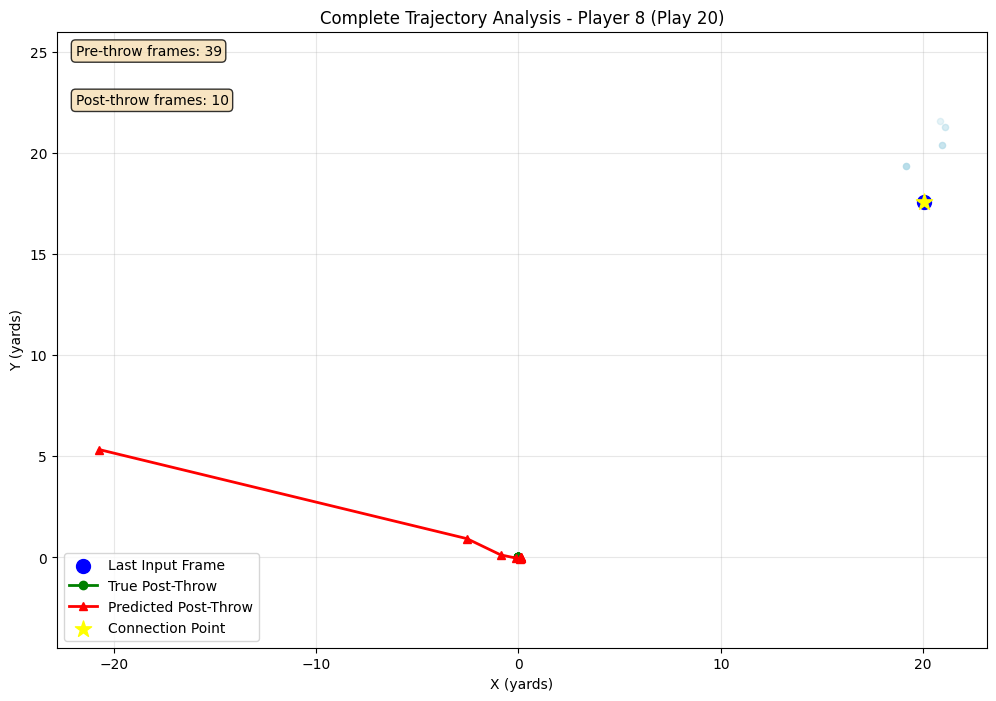


Connection Analysis for Player 8:
Last input position: (20.04, 17.54)
First predicted position: (-20.72, 5.33)
First true position: (0.00, 0.00)
Prediction gap: 42.55 yards
True gap: 26.63 yards


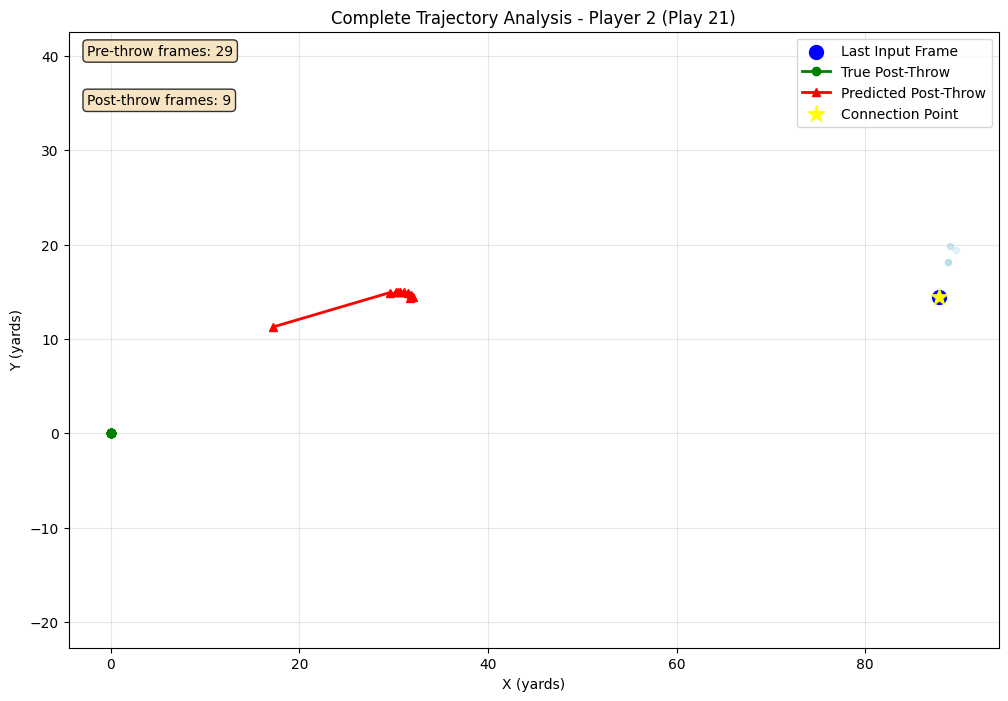


Connection Analysis for Player 2:
Last input position: (87.78, 14.46)
First predicted position: (17.23, 11.27)
First true position: (0.00, 0.00)
Prediction gap: 70.62 yards
True gap: 88.96 yards


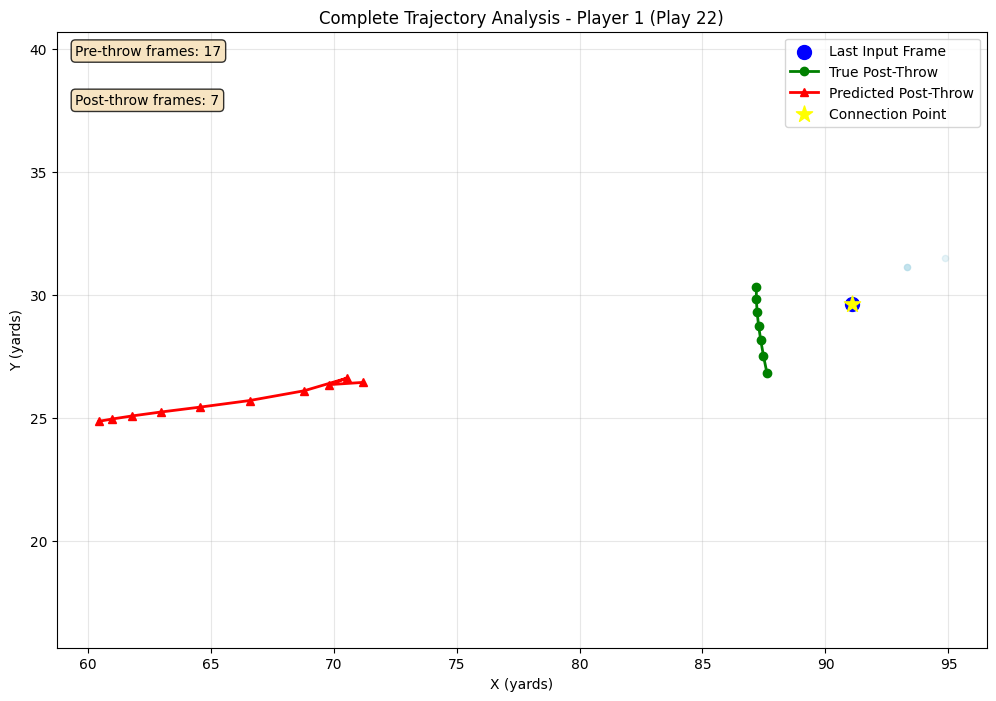


Connection Analysis for Player 1:
Last input position: (91.09, 29.65)
First predicted position: (71.19, 26.45)
First true position: (87.19, 30.34)
Prediction gap: 20.16 yards
True gap: 3.96 yards


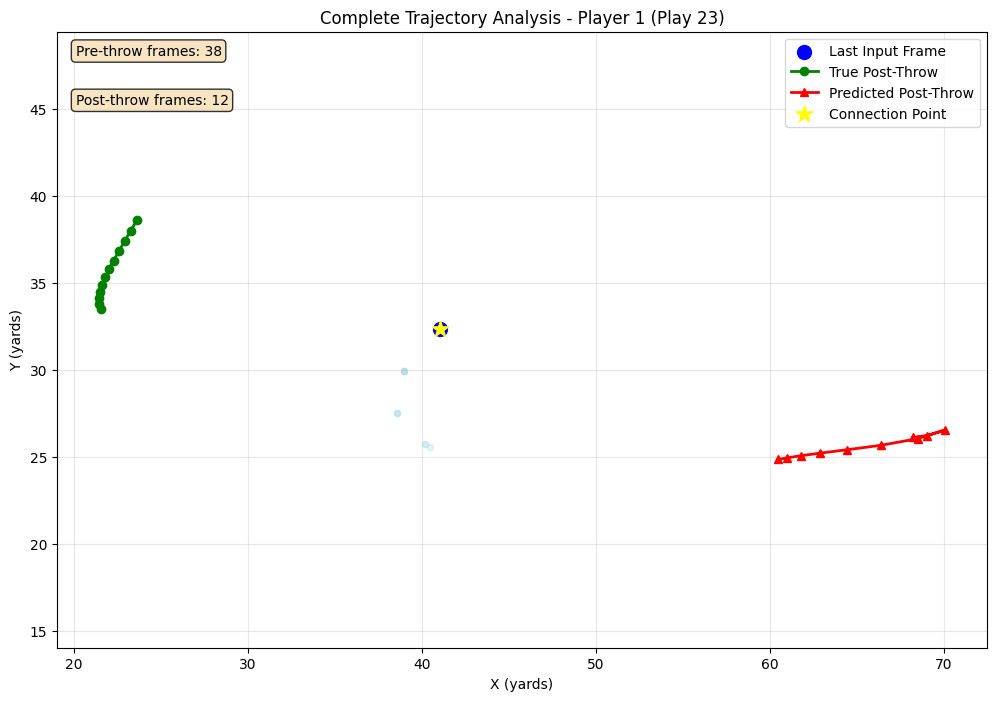


Connection Analysis for Player 1:
Last input position: (41.02, 32.35)
First predicted position: (68.23, 26.13)
First true position: (21.54, 33.52)
Prediction gap: 27.91 yards
True gap: 19.52 yards


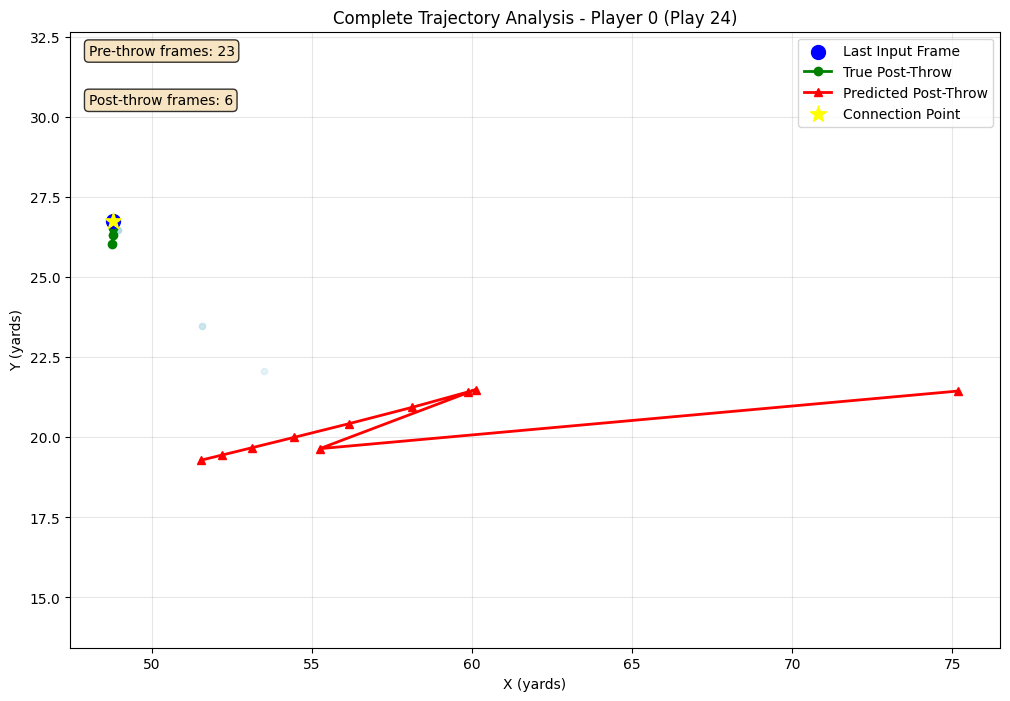


Connection Analysis for Player 0:
Last input position: (48.79, 26.76)
First predicted position: (75.17, 21.45)
First true position: (48.77, 26.81)
Prediction gap: 26.91 yards
True gap: 0.05 yards


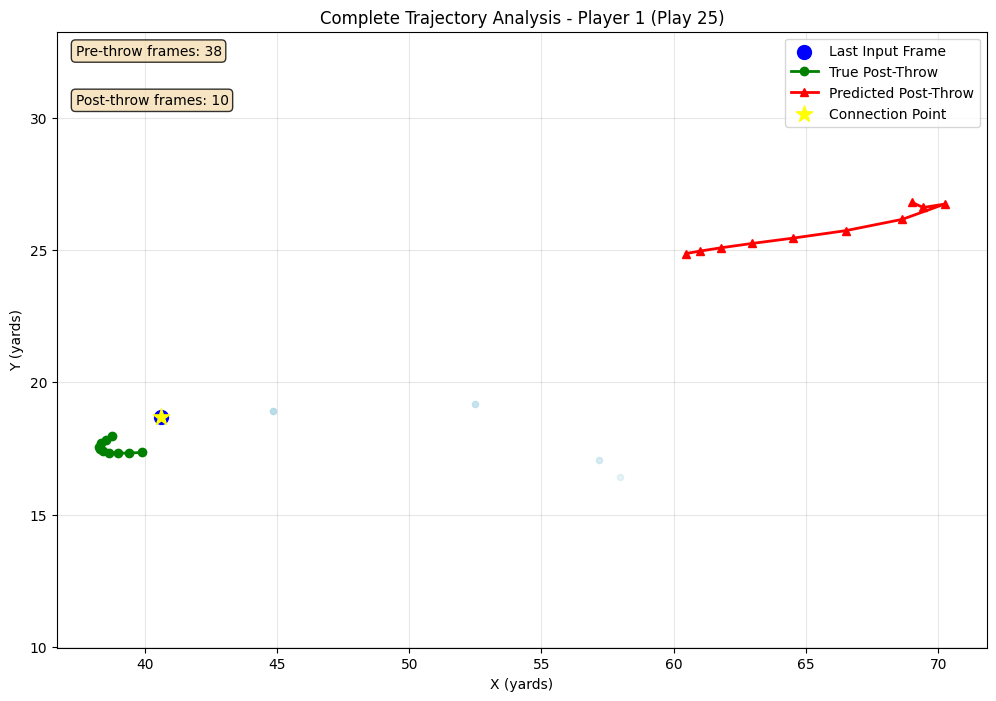


Connection Analysis for Player 1:
Last input position: (40.62, 18.69)
First predicted position: (69.01, 26.81)
First true position: (39.89, 17.35)
Prediction gap: 29.52 yards
True gap: 1.53 yards


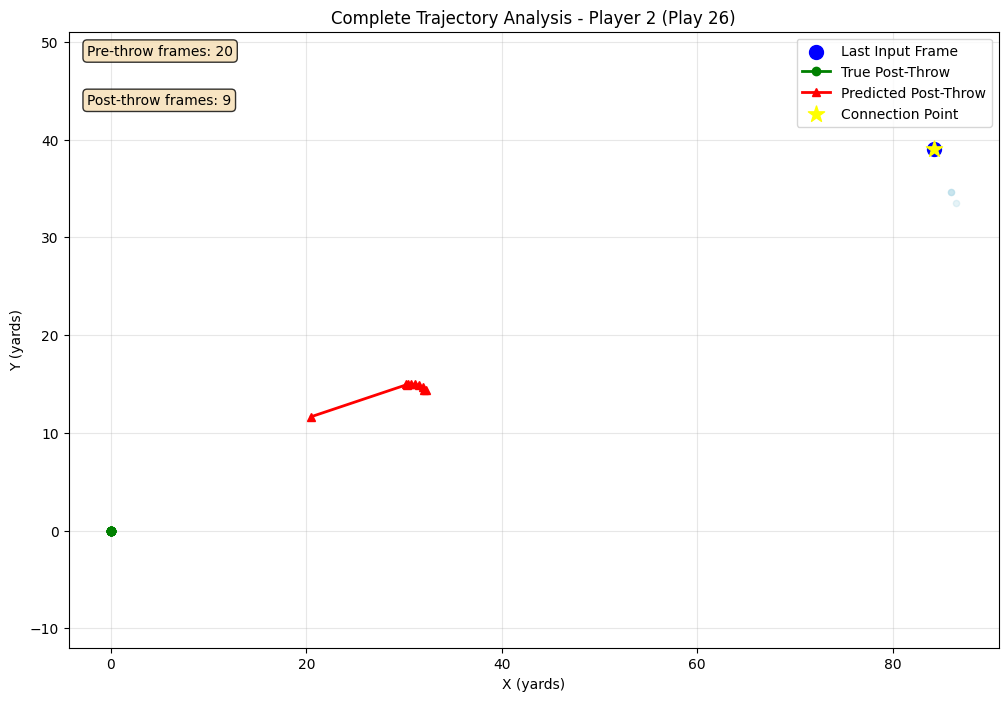


Connection Analysis for Player 2:
Last input position: (84.17, 39.04)
First predicted position: (20.51, 11.65)
First true position: (0.00, 0.00)
Prediction gap: 69.30 yards
True gap: 92.78 yards


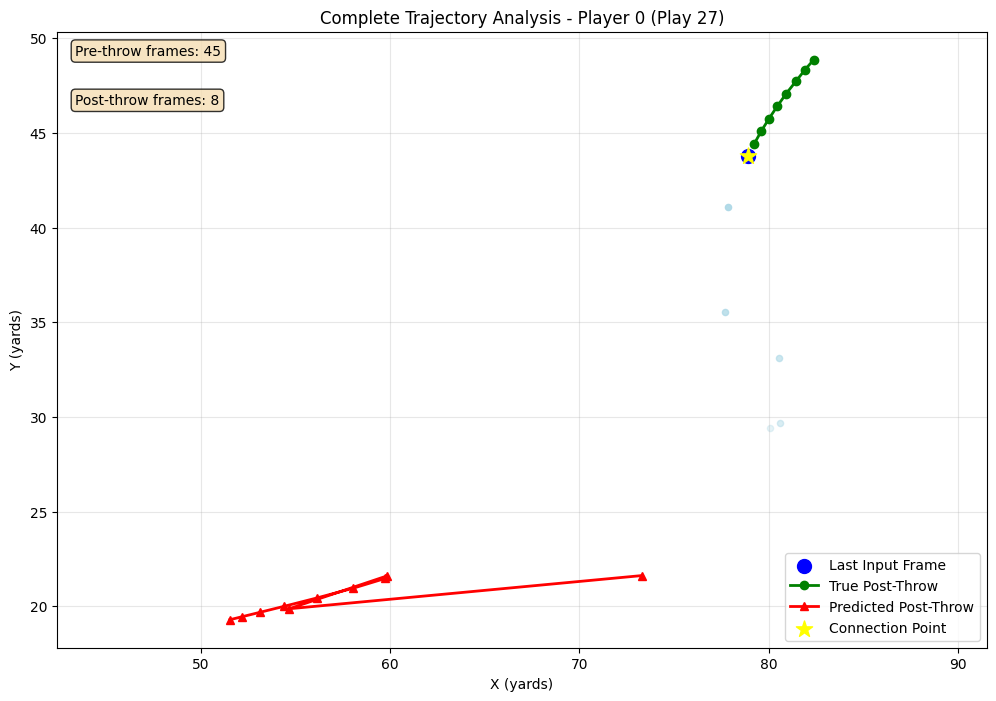


Connection Analysis for Player 0:
Last input position: (78.89, 43.77)
First predicted position: (73.29, 21.62)
First true position: (79.24, 44.43)
Prediction gap: 22.85 yards
True gap: 0.75 yards


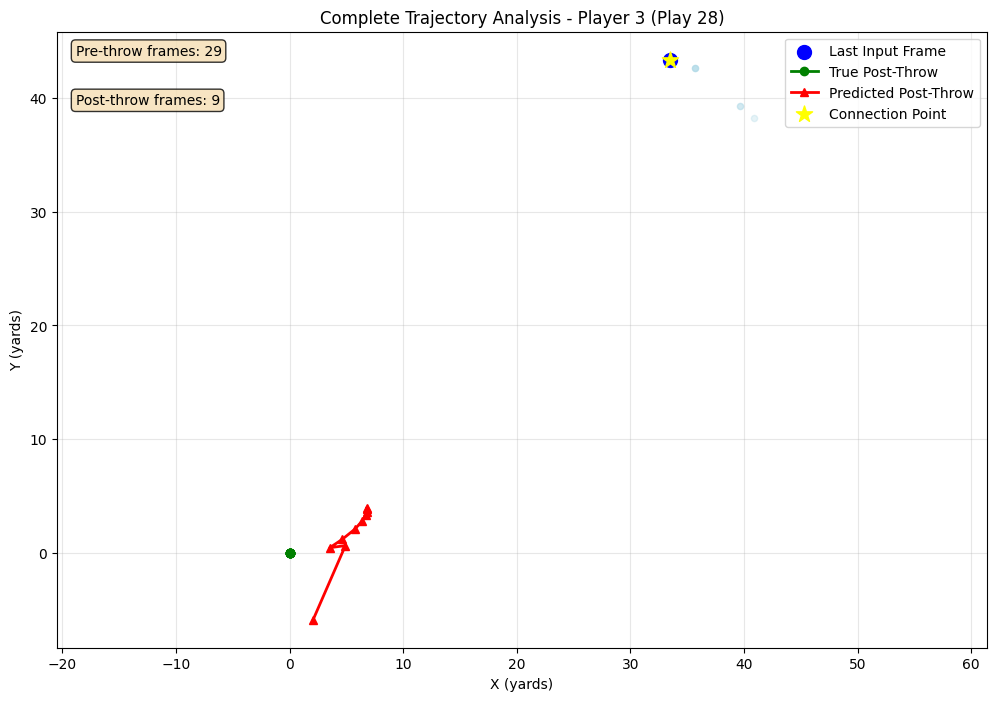


Connection Analysis for Player 3:
Last input position: (33.45, 43.39)
First predicted position: (2.08, -5.91)
First true position: (0.00, 0.00)
Prediction gap: 58.44 yards
True gap: 54.79 yards


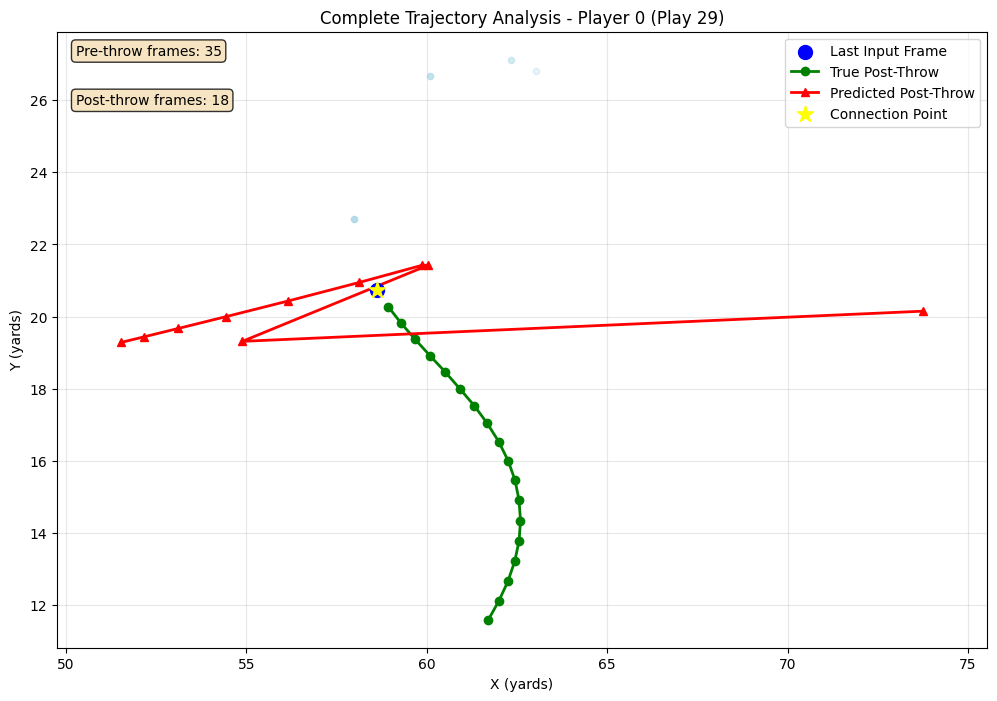


Connection Analysis for Player 0:
Last input position: (58.62, 20.74)
First predicted position: (73.75, 20.15)
First true position: (58.93, 20.28)
Prediction gap: 15.14 yards
True gap: 0.55 yards


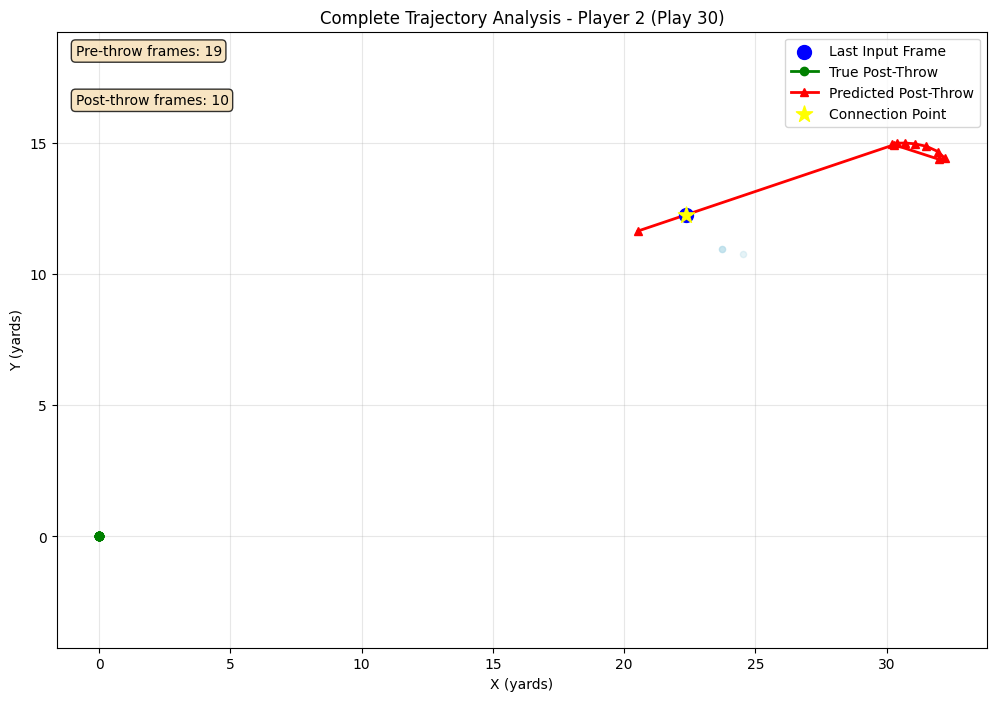


Connection Analysis for Player 2:
Last input position: (22.35, 12.23)
First predicted position: (20.53, 11.64)
First true position: (0.00, 0.00)
Prediction gap: 1.91 yards
True gap: 25.48 yards


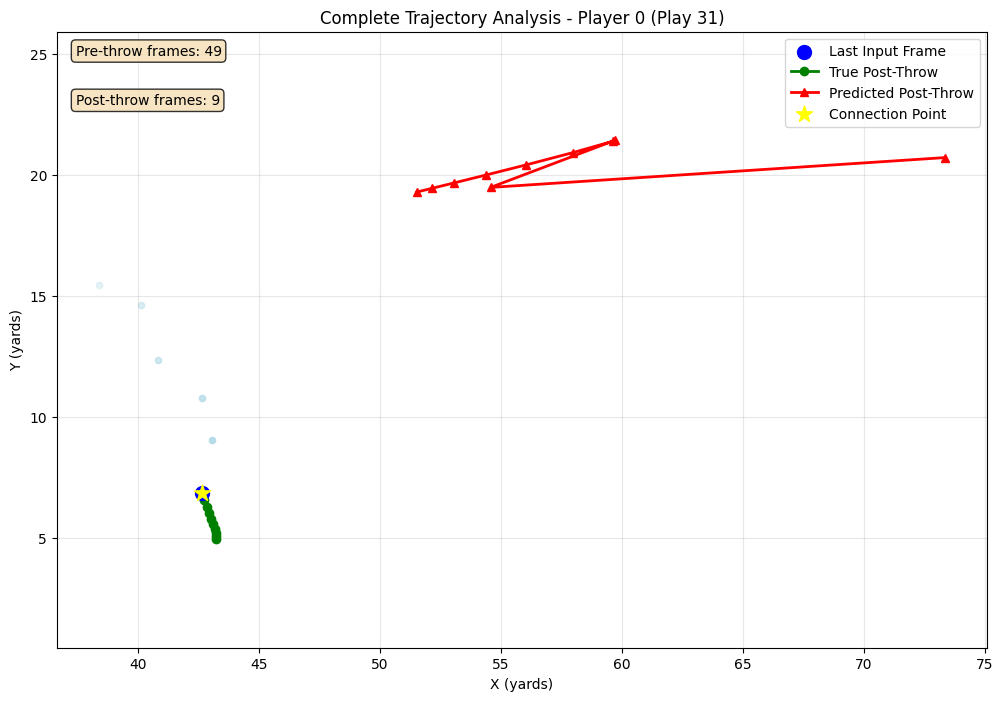


Connection Analysis for Player 0:
Last input position: (42.67, 6.84)
First predicted position: (73.34, 20.71)
First true position: (42.76, 6.55)
Prediction gap: 33.66 yards
True gap: 0.30 yards


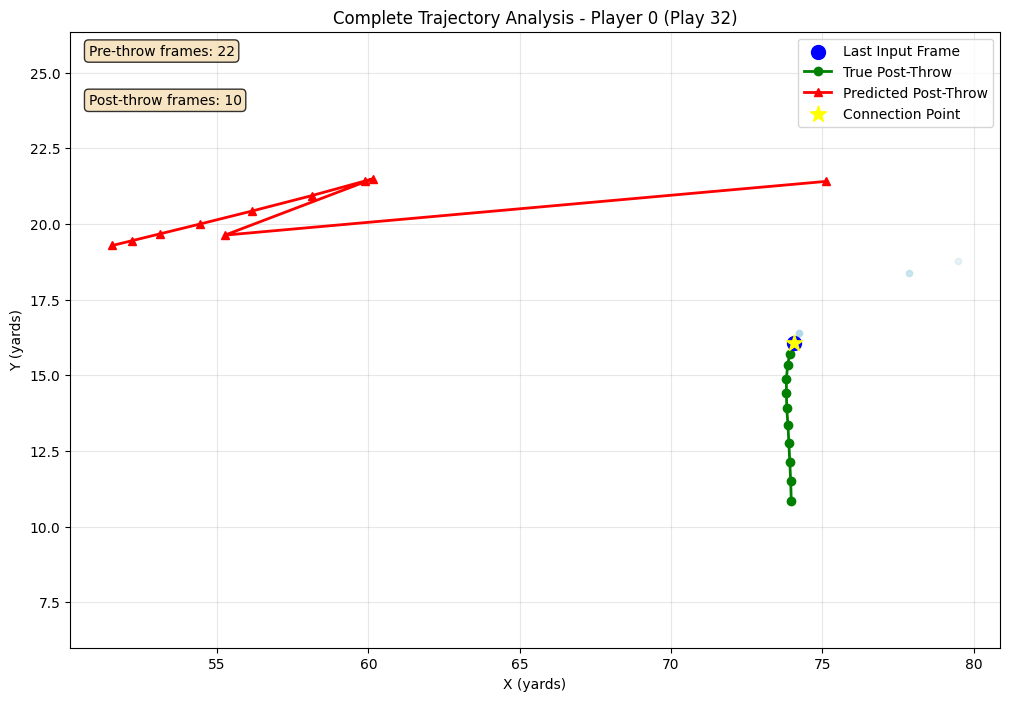


Connection Analysis for Player 0:
Last input position: (74.05, 16.07)
First predicted position: (75.13, 21.41)
First true position: (73.92, 15.71)
Prediction gap: 5.44 yards
True gap: 0.38 yards


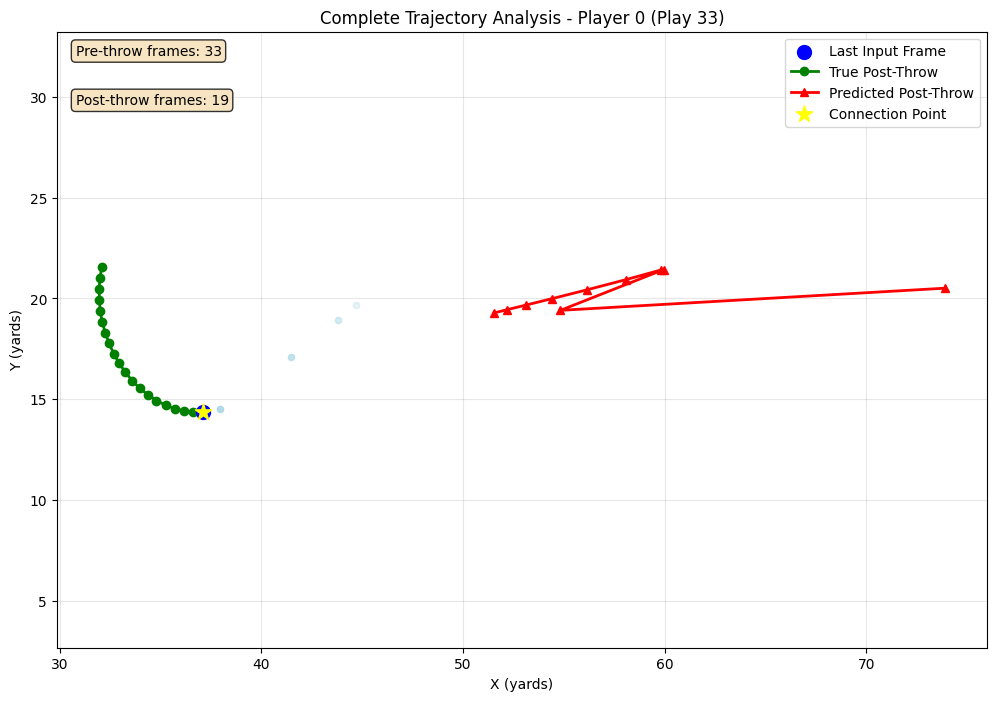


Connection Analysis for Player 0:
Last input position: (37.08, 14.36)
First predicted position: (73.88, 20.51)
First true position: (36.62, 14.37)
Prediction gap: 37.31 yards
True gap: 0.46 yards


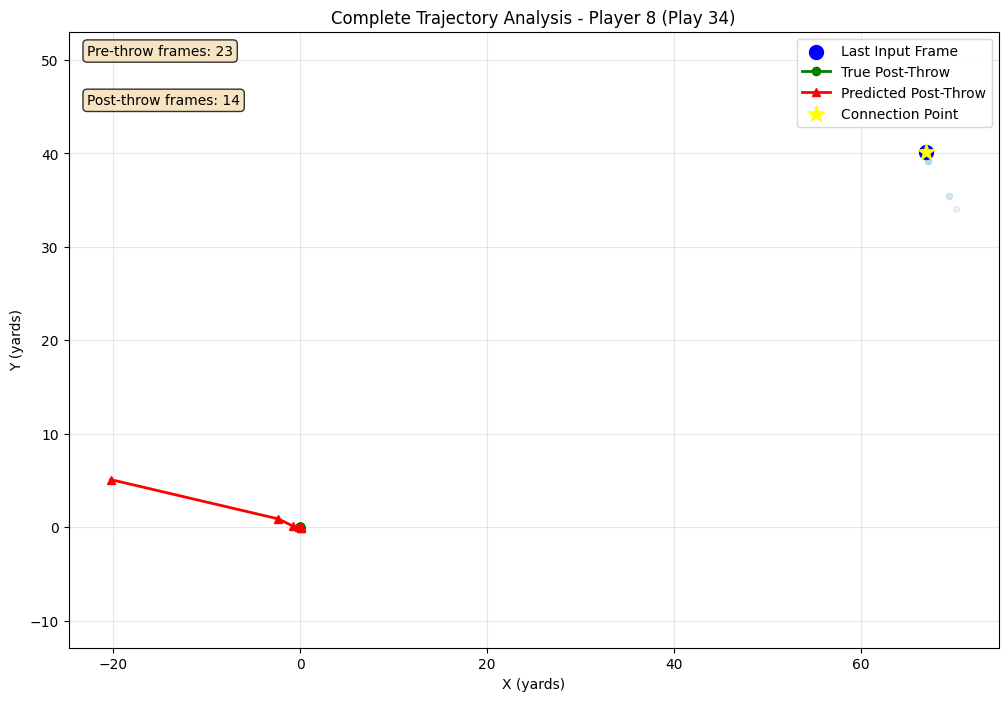


Connection Analysis for Player 8:
Last input position: (67.04, 40.18)
First predicted position: (-20.27, 5.09)
First true position: (0.00, 0.00)
Prediction gap: 94.10 yards
True gap: 78.16 yards


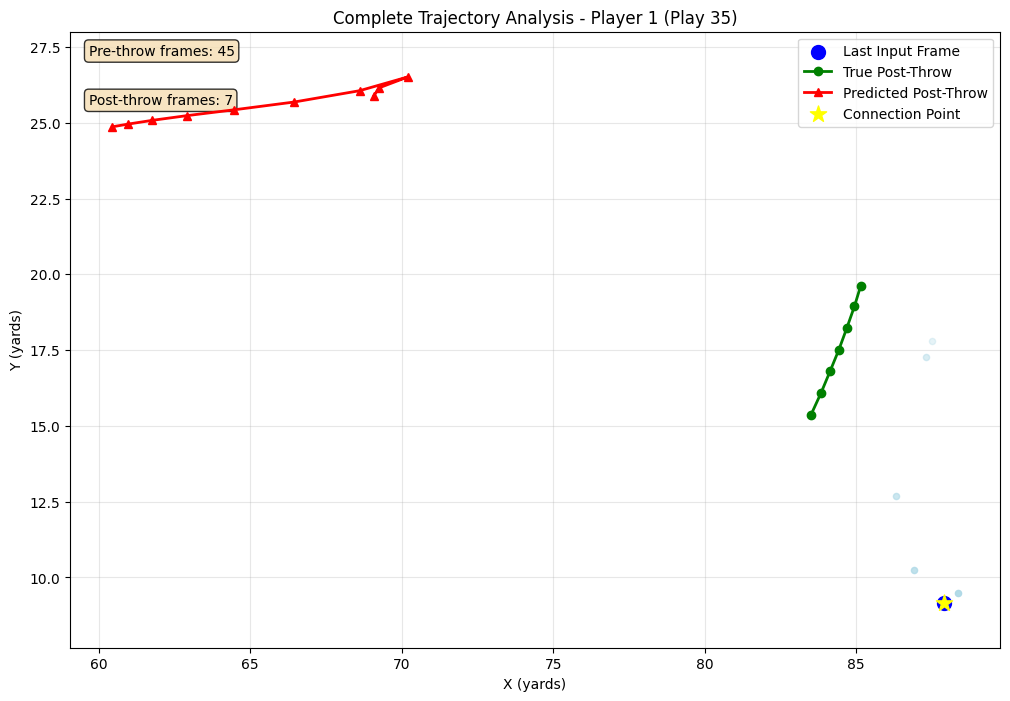


Connection Analysis for Player 1:
Last input position: (87.89, 9.17)
First predicted position: (69.08, 25.89)
First true position: (85.15, 19.63)
Prediction gap: 25.16 yards
True gap: 10.81 yards


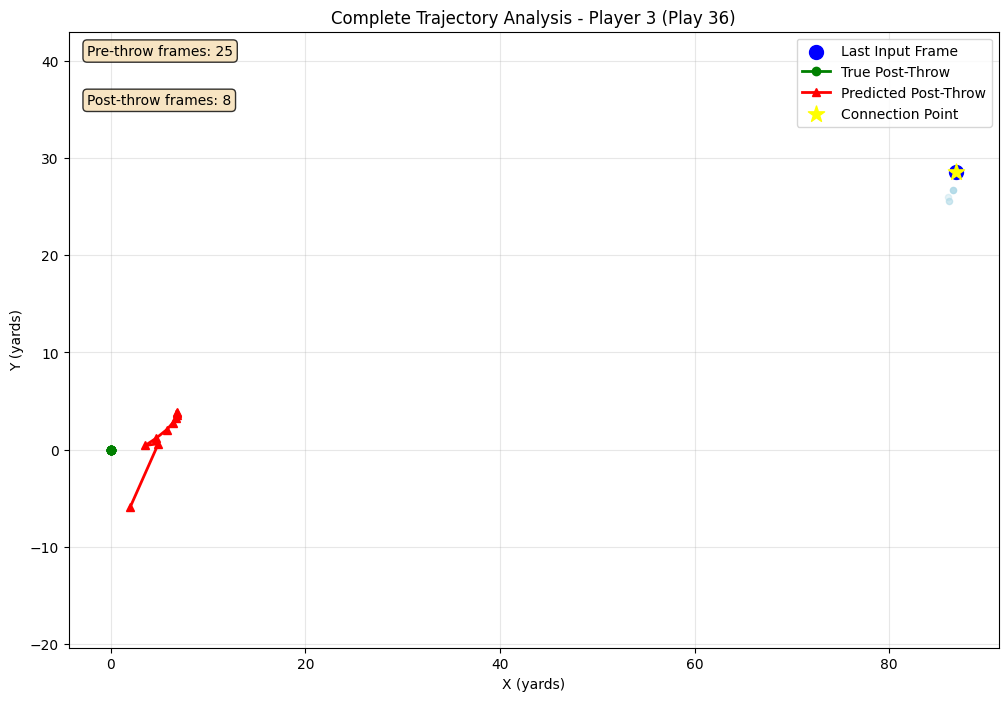


Connection Analysis for Player 3:
Last input position: (86.90, 28.50)
First predicted position: (2.00, -5.88)
First true position: (0.00, 0.00)
Prediction gap: 91.60 yards
True gap: 91.45 yards


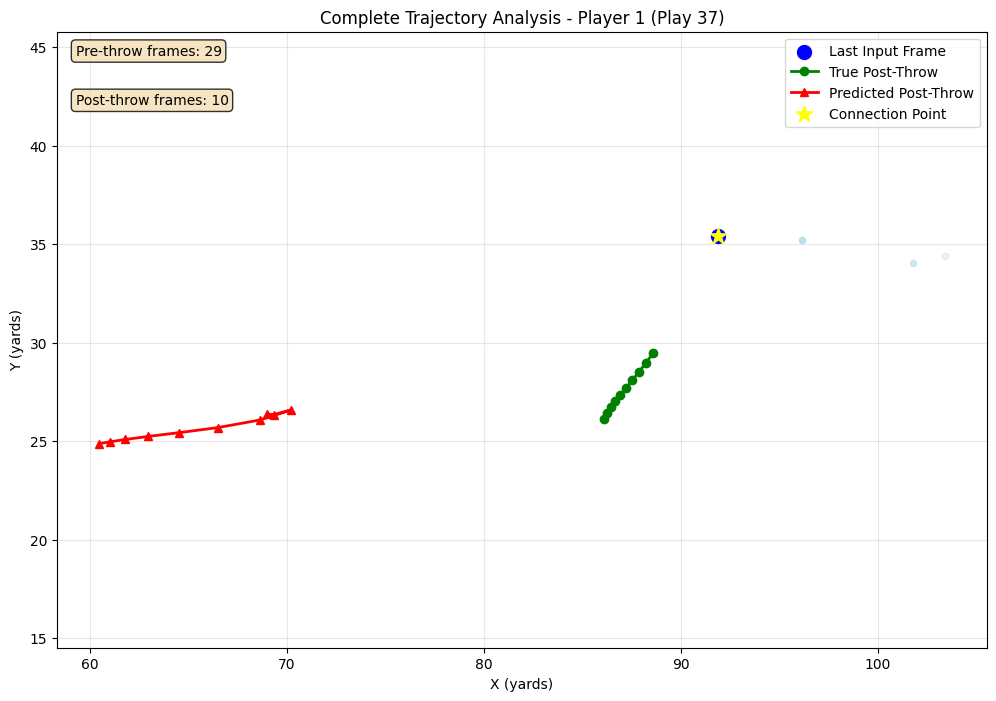


Connection Analysis for Player 1:
Last input position: (91.89, 35.42)
First predicted position: (68.99, 26.37)
First true position: (86.10, 26.14)
Prediction gap: 24.62 yards
True gap: 10.94 yards


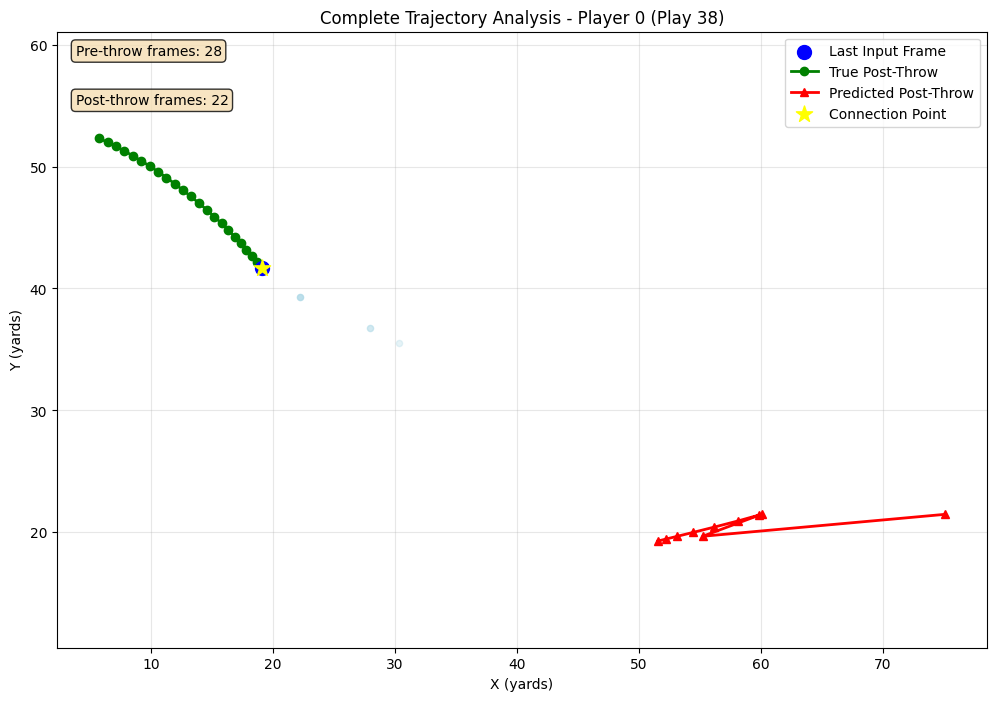


Connection Analysis for Player 0:
Last input position: (19.12, 41.69)
First predicted position: (75.07, 21.48)
First true position: (18.71, 42.16)
Prediction gap: 59.49 yards
True gap: 0.62 yards


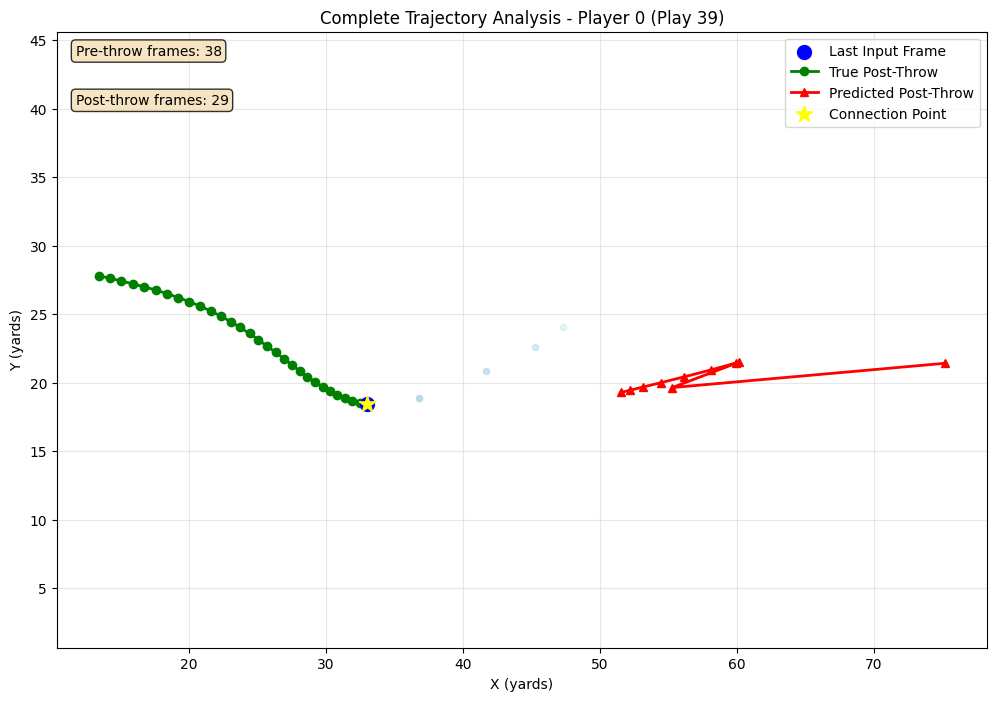


Connection Analysis for Player 0:
Last input position: (32.98, 18.47)
First predicted position: (75.17, 21.41)
First true position: (32.44, 18.54)
Prediction gap: 42.29 yards
True gap: 0.54 yards


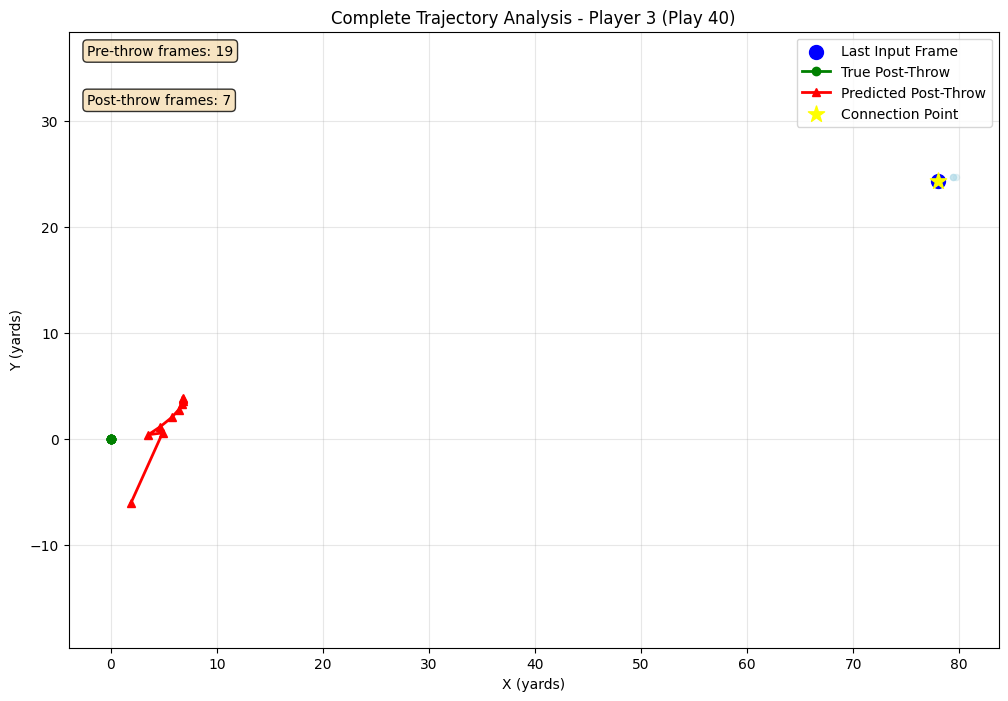


Connection Analysis for Player 3:
Last input position: (77.98, 24.38)
First predicted position: (1.91, -5.98)
First true position: (0.00, 0.00)
Prediction gap: 81.91 yards
True gap: 81.70 yards


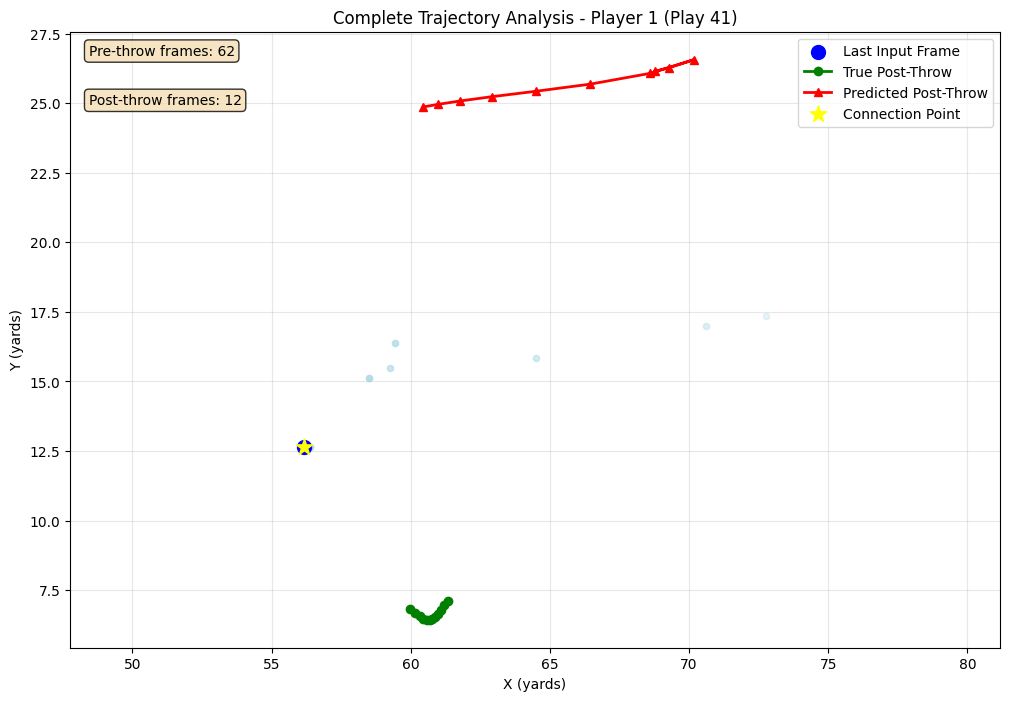


Connection Analysis for Player 1:
Last input position: (56.16, 12.63)
First predicted position: (68.76, 26.14)
First true position: (61.34, 7.13)
Prediction gap: 18.48 yards
True gap: 7.56 yards


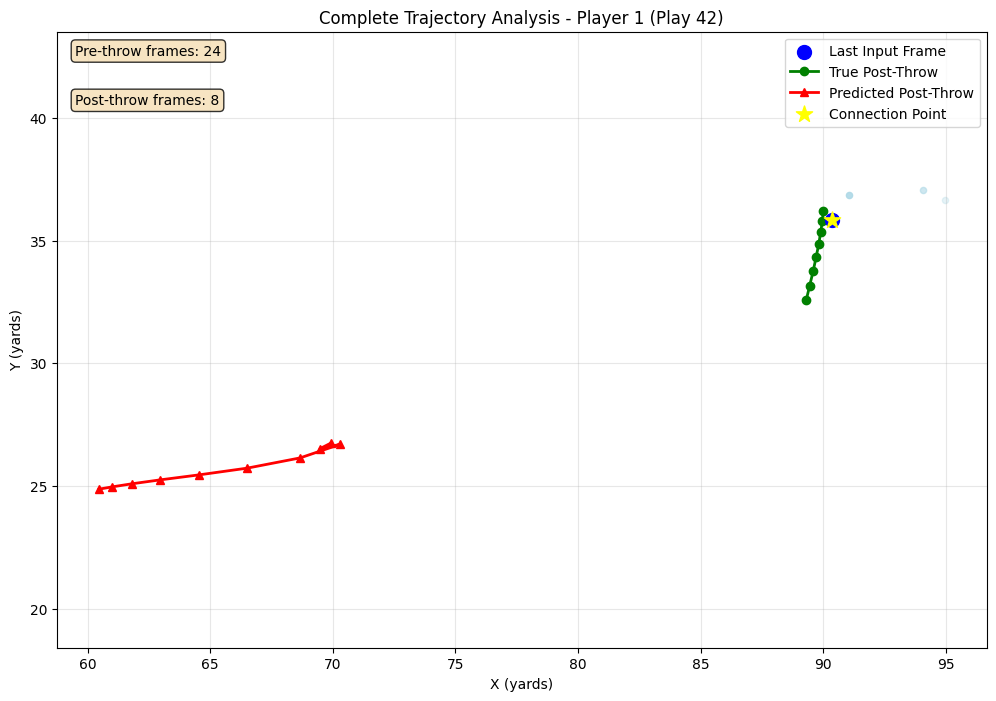


Connection Analysis for Player 1:
Last input position: (90.38, 35.86)
First predicted position: (69.92, 26.75)
First true position: (90.01, 36.22)
Prediction gap: 22.40 yards
True gap: 0.52 yards


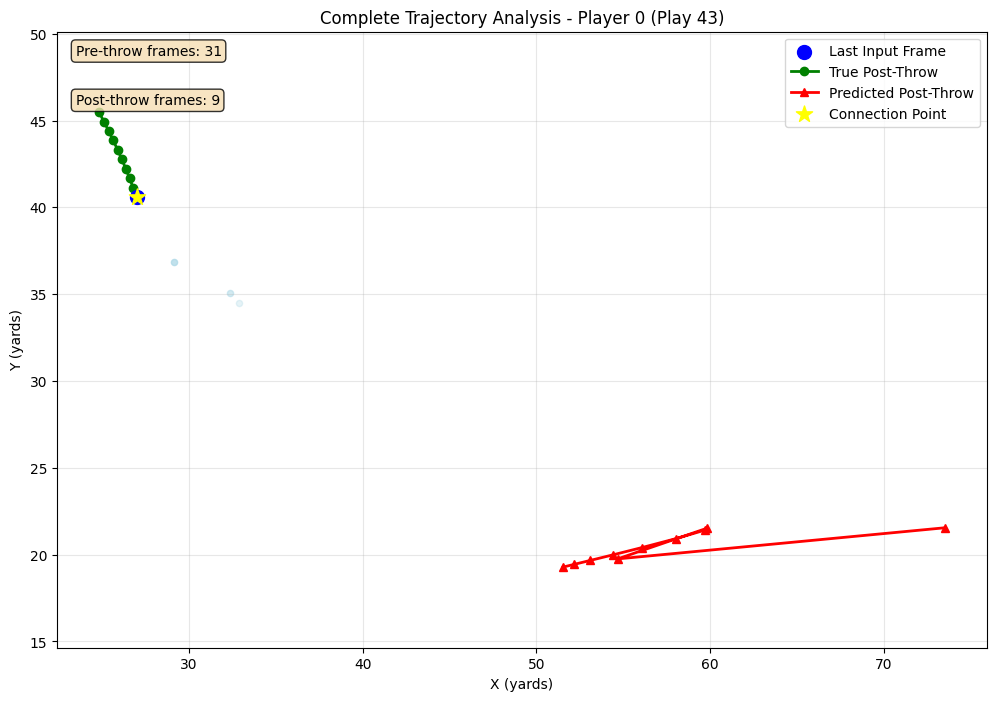


Connection Analysis for Player 0:
Last input position: (26.97, 40.59)
First predicted position: (73.51, 21.55)
First true position: (26.78, 41.12)
Prediction gap: 50.28 yards
True gap: 0.56 yards


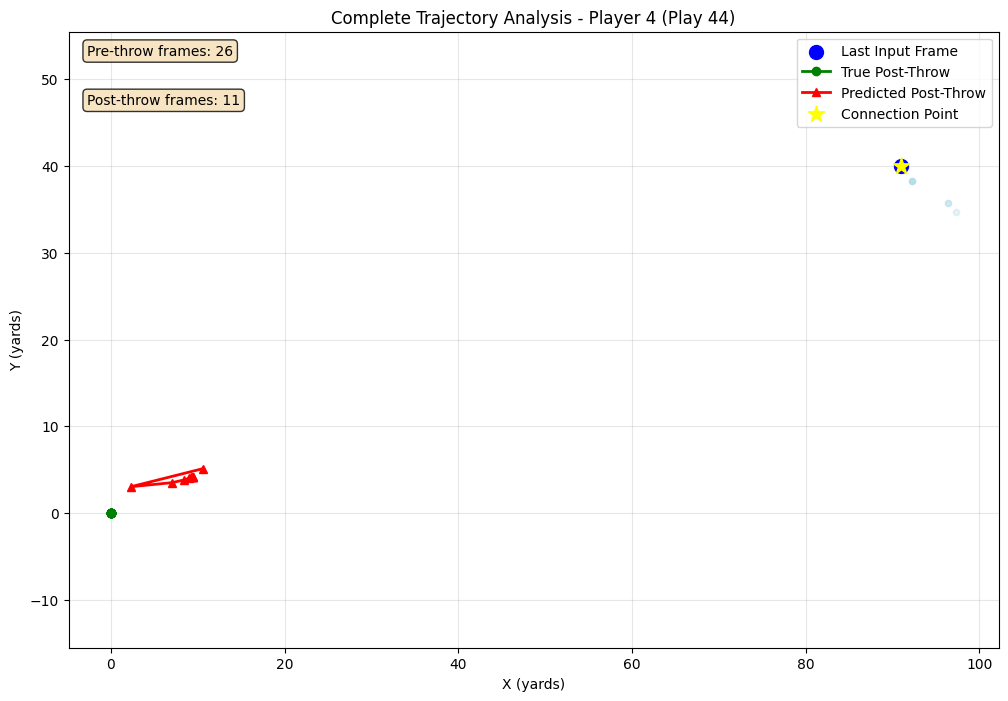


Connection Analysis for Player 4:
Last input position: (90.96, 39.95)
First predicted position: (10.62, 5.14)
First true position: (0.00, 0.00)
Prediction gap: 87.56 yards
True gap: 99.35 yards


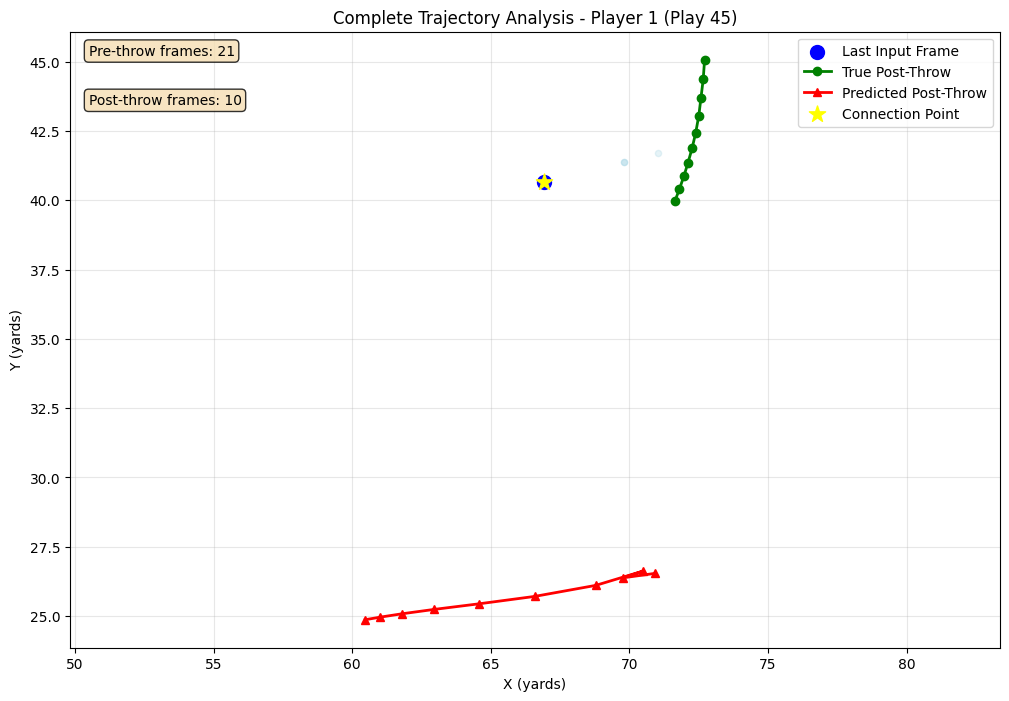


Connection Analysis for Player 1:
Last input position: (66.90, 40.67)
First predicted position: (70.94, 26.54)
First true position: (71.64, 39.97)
Prediction gap: 14.69 yards
True gap: 4.79 yards


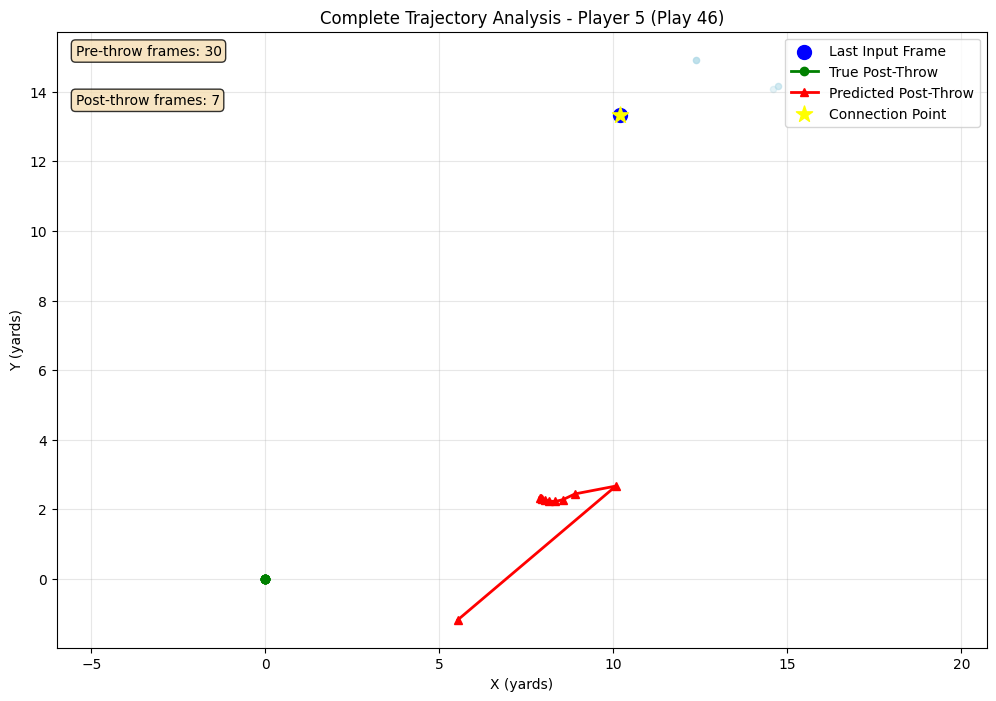


Connection Analysis for Player 5:
Last input position: (10.18, 13.34)
First predicted position: (5.53, -1.17)
First true position: (0.00, 0.00)
Prediction gap: 15.24 yards
True gap: 16.78 yards


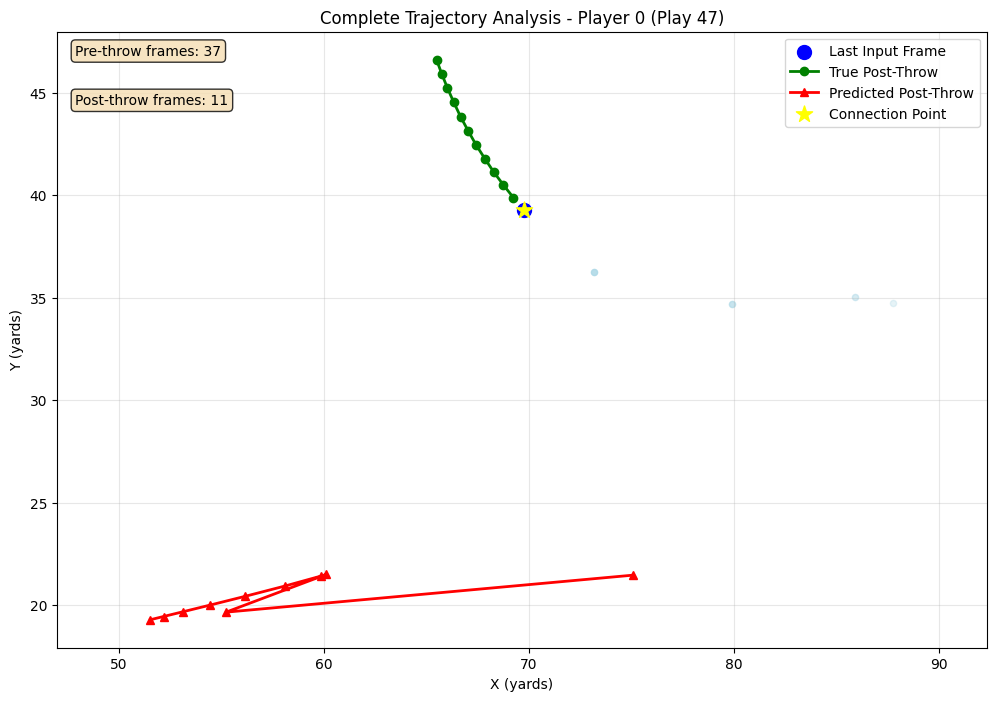


Connection Analysis for Player 0:
Last input position: (69.77, 39.28)
First predicted position: (75.10, 21.46)
First true position: (69.25, 39.87)
Prediction gap: 18.60 yards
True gap: 0.79 yards


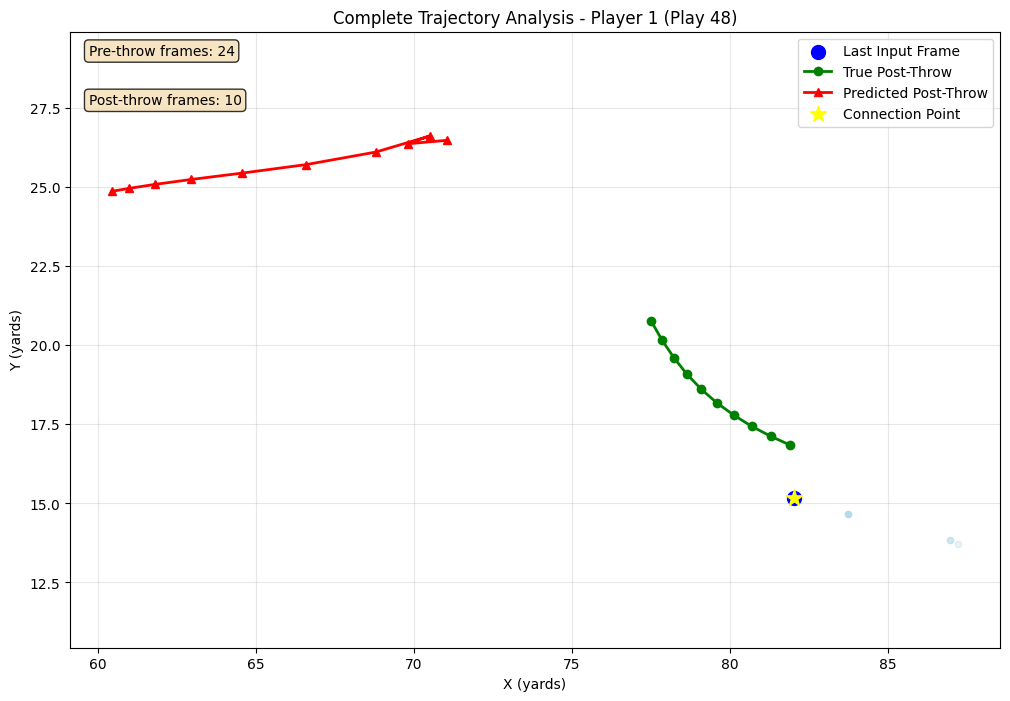


Connection Analysis for Player 1:
Last input position: (82.03, 15.18)
First predicted position: (71.06, 26.48)
First true position: (81.91, 16.84)
Prediction gap: 15.75 yards
True gap: 1.66 yards


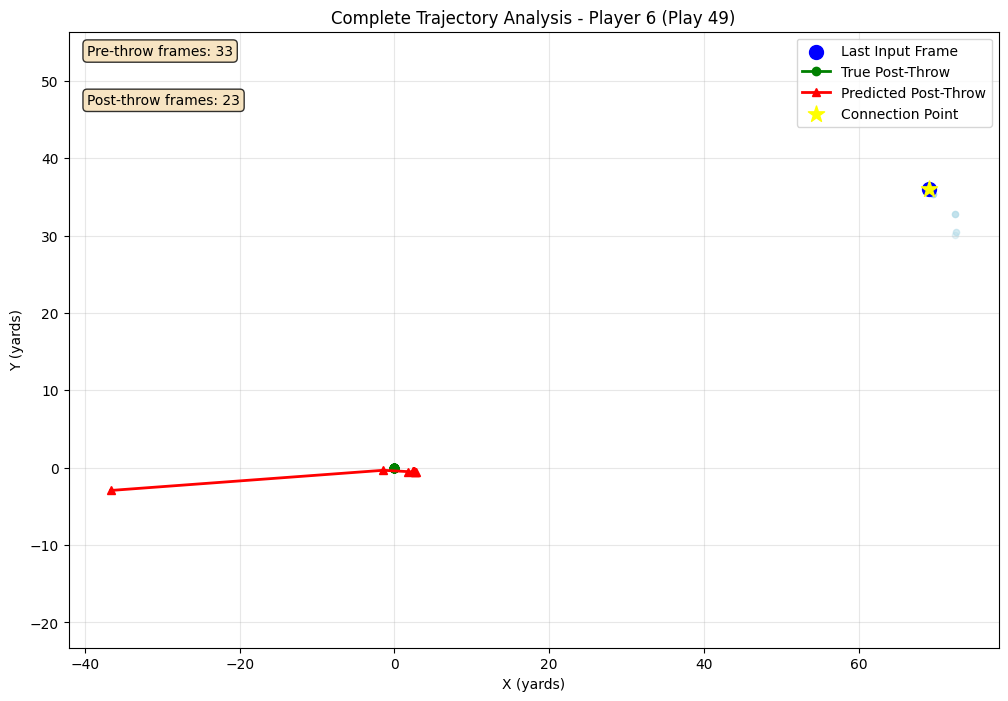


Connection Analysis for Player 6:
Last input position: (69.14, 36.03)
First predicted position: (-36.67, -2.94)
First true position: (0.00, 0.00)
Prediction gap: 112.76 yards
True gap: 77.96 yards


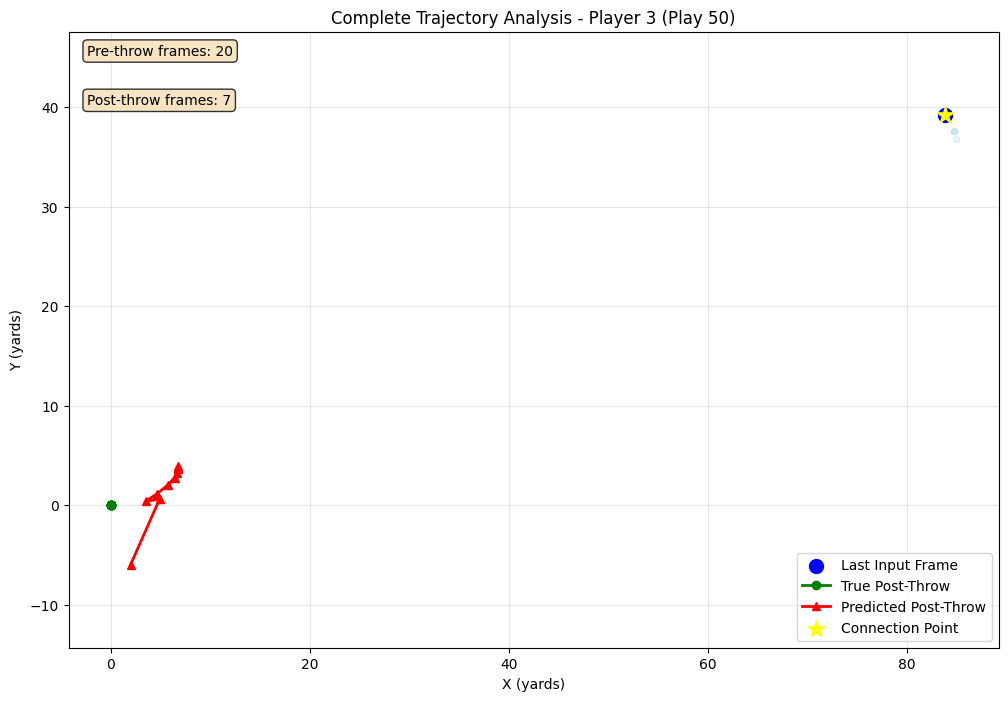


Connection Analysis for Player 3:
Last input position: (83.85, 39.25)
First predicted position: (1.99, -5.96)
First true position: (0.00, 0.00)
Prediction gap: 93.51 yards
True gap: 92.58 yards


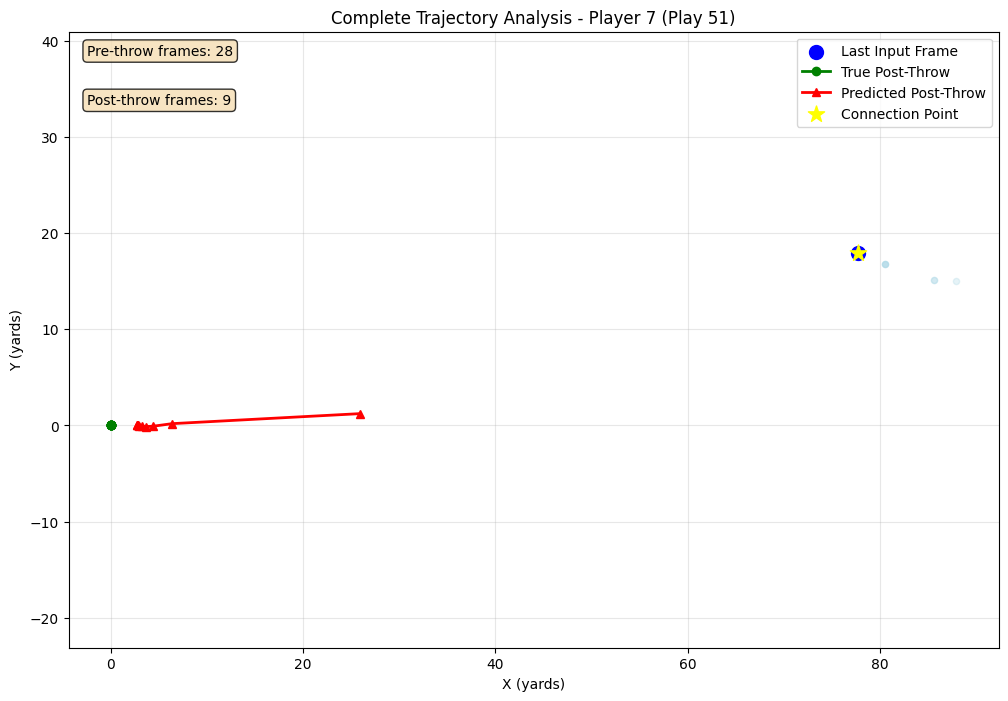


Connection Analysis for Player 7:
Last input position: (77.67, 17.95)
First predicted position: (25.94, 1.23)
First true position: (0.00, 0.00)
Prediction gap: 54.36 yards
True gap: 79.72 yards


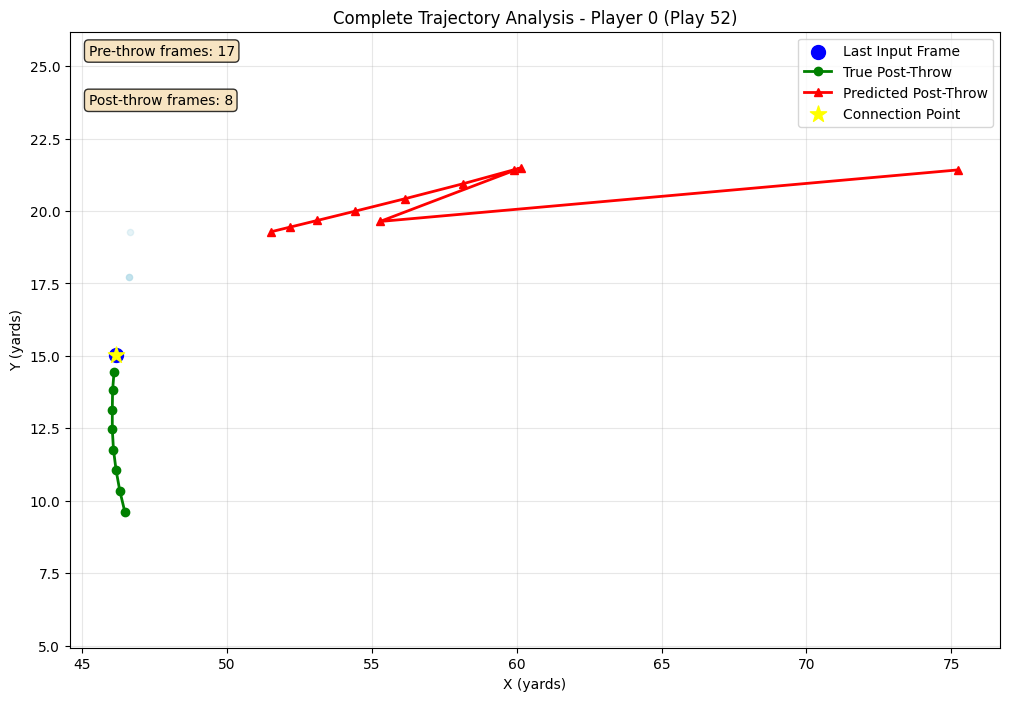


Connection Analysis for Player 0:
Last input position: (46.17, 15.03)
First predicted position: (75.22, 21.42)
First true position: (46.11, 14.44)
Prediction gap: 29.75 yards
True gap: 0.59 yards


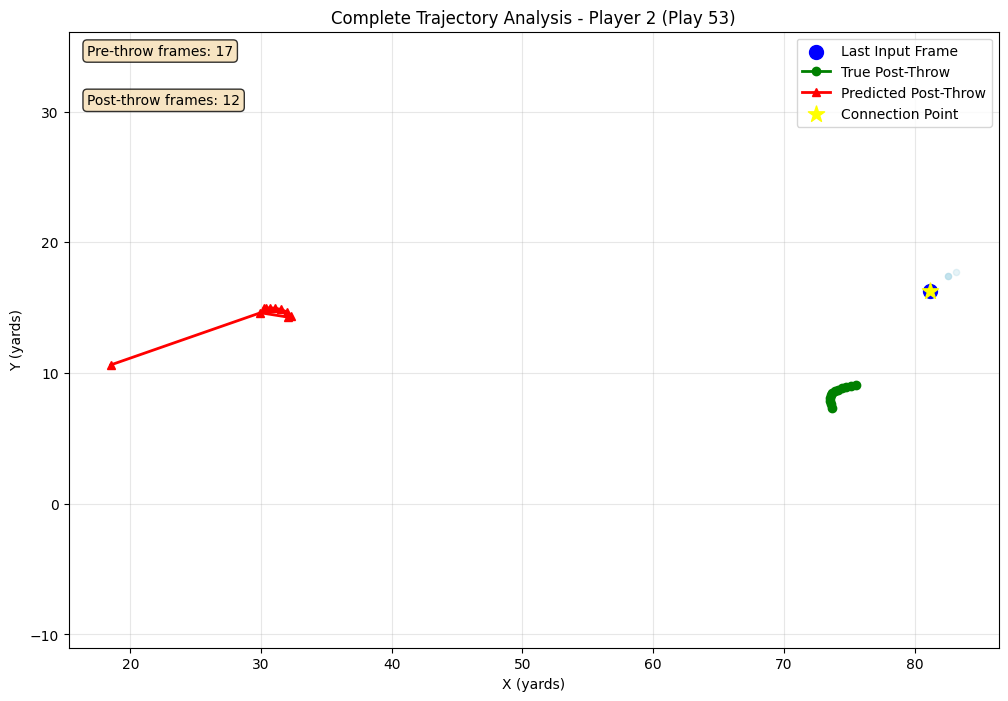


Connection Analysis for Player 2:
Last input position: (81.16, 16.29)
First predicted position: (18.50, 10.62)
First true position: (75.55, 9.08)
Prediction gap: 62.92 yards
True gap: 9.14 yards


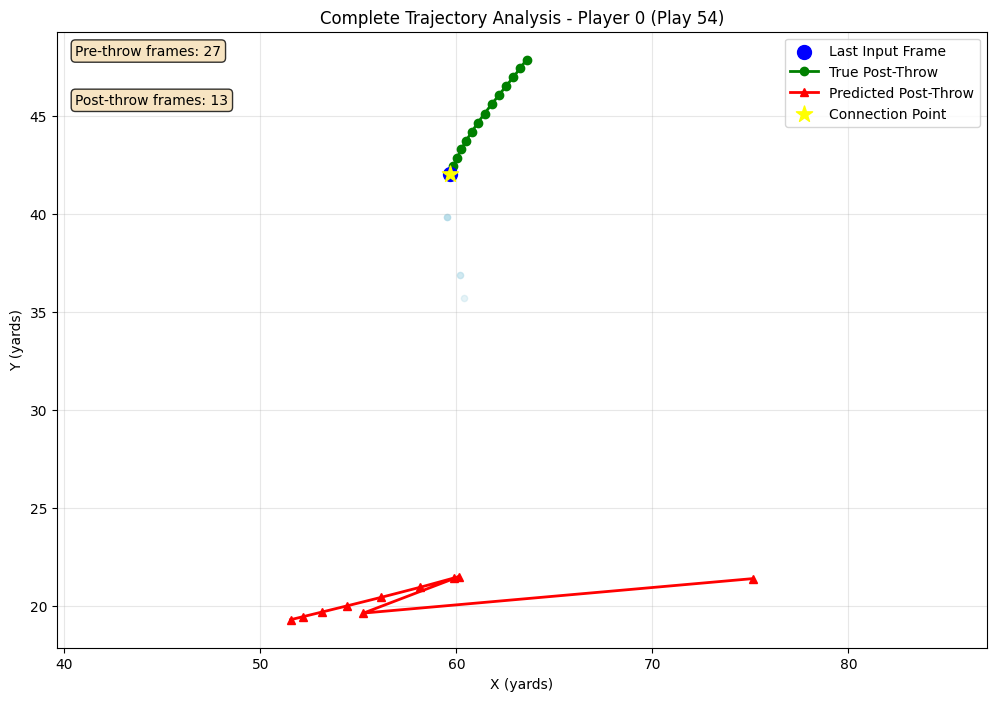


Connection Analysis for Player 0:
Last input position: (59.70, 42.04)
First predicted position: (75.14, 21.39)
First true position: (59.85, 42.44)
Prediction gap: 25.79 yards
True gap: 0.43 yards


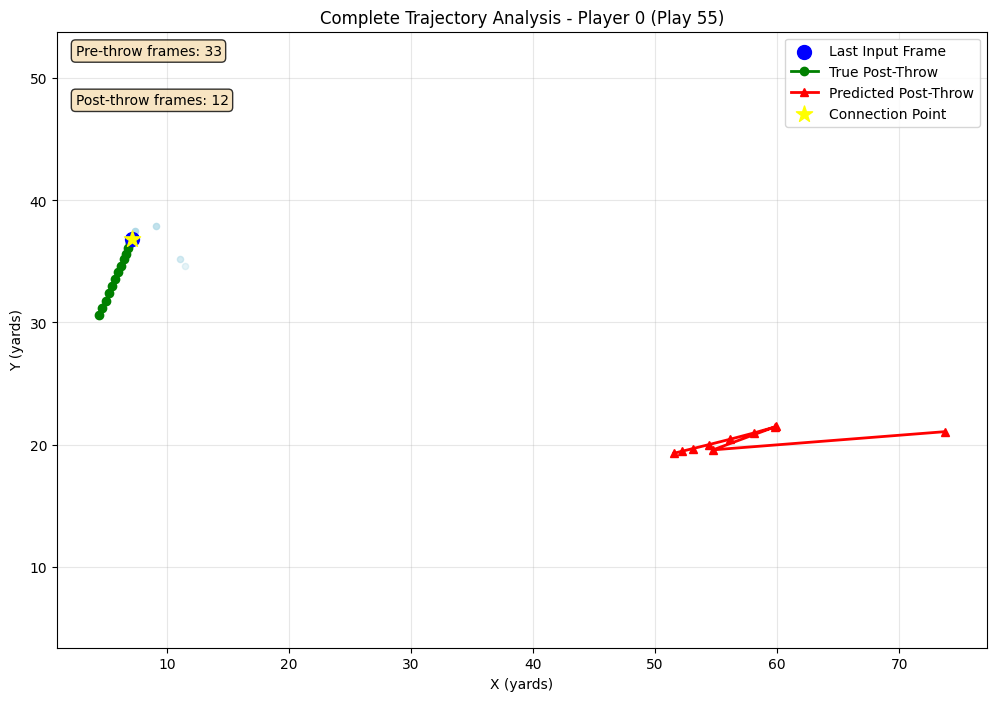


Connection Analysis for Player 0:
Last input position: (7.15, 36.87)
First predicted position: (73.72, 21.05)
First true position: (7.01, 36.50)
Prediction gap: 68.42 yards
True gap: 0.40 yards


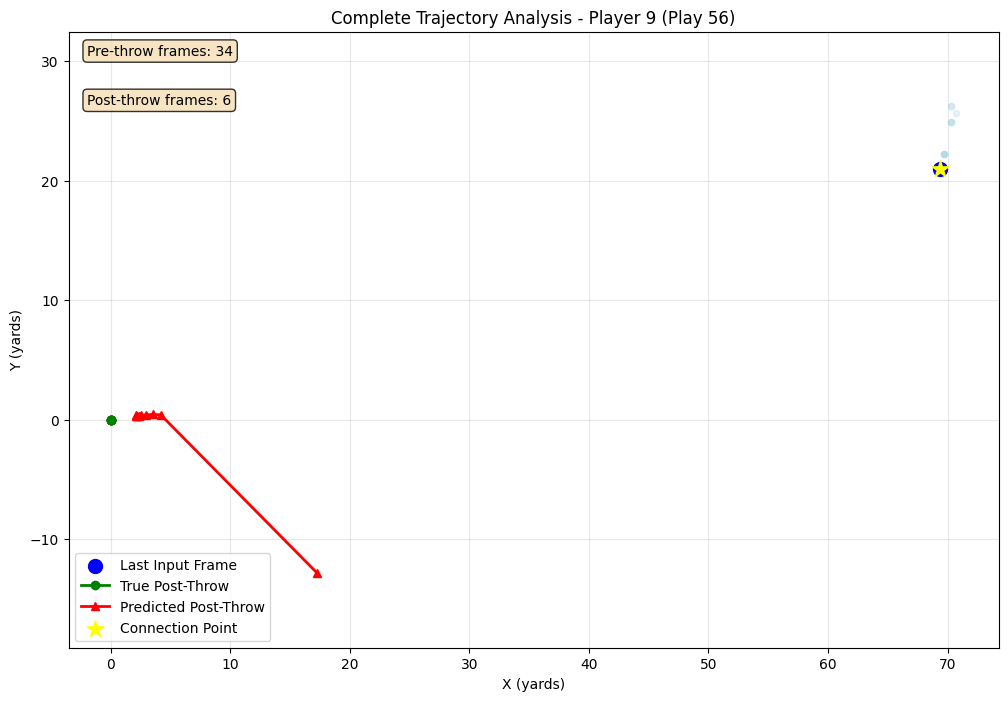


Connection Analysis for Player 9:
Last input position: (69.37, 21.01)
First predicted position: (17.27, -12.82)
First true position: (0.00, 0.00)
Prediction gap: 62.12 yards
True gap: 72.48 yards


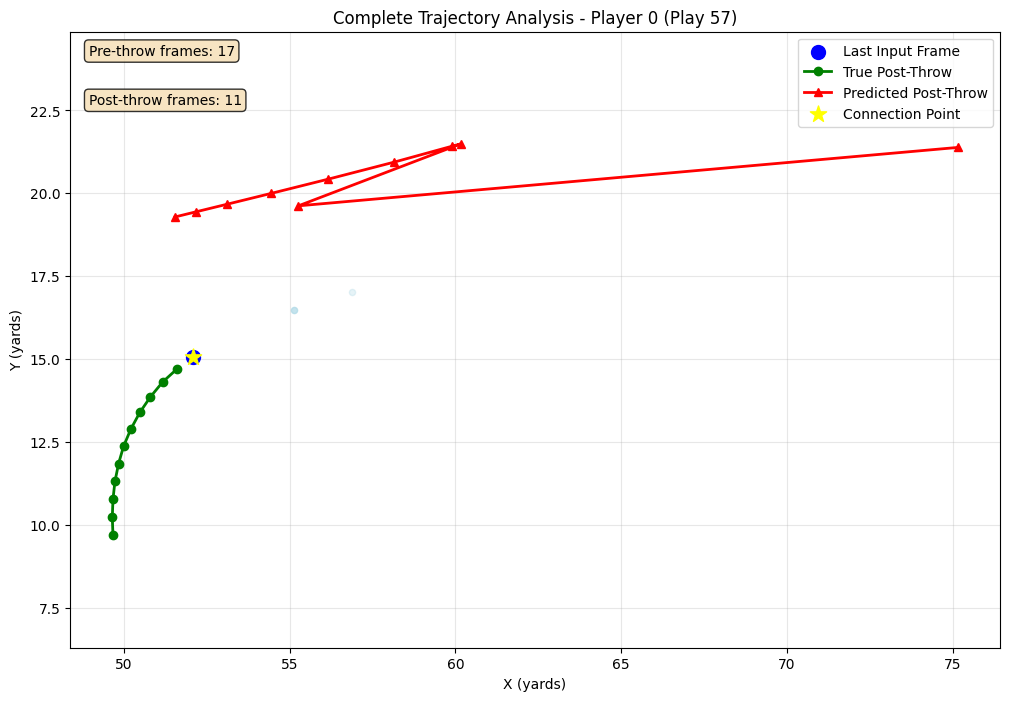


Connection Analysis for Player 0:
Last input position: (52.09, 15.05)
First predicted position: (75.15, 21.38)
First true position: (51.61, 14.71)
Prediction gap: 23.91 yards
True gap: 0.59 yards


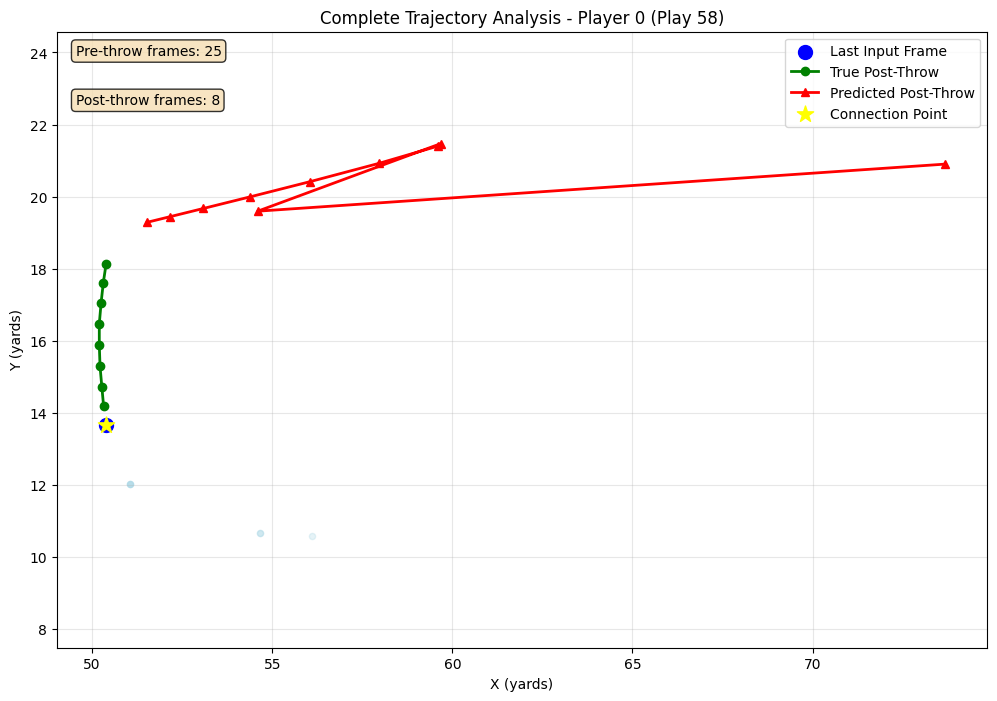


Connection Analysis for Player 0:
Last input position: (50.39, 13.67)
First predicted position: (73.67, 20.90)
First true position: (50.32, 14.18)
Prediction gap: 24.38 yards
True gap: 0.51 yards


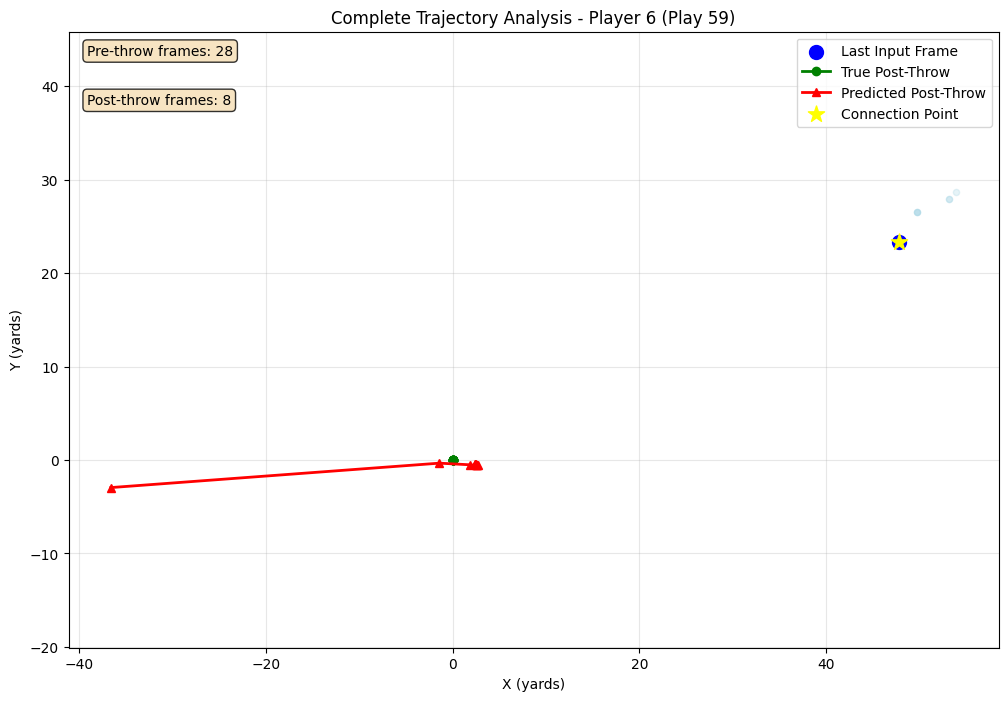


Connection Analysis for Player 6:
Last input position: (47.82, 23.33)
First predicted position: (-36.59, -2.95)
First true position: (0.00, 0.00)
Prediction gap: 88.41 yards
True gap: 53.21 yards


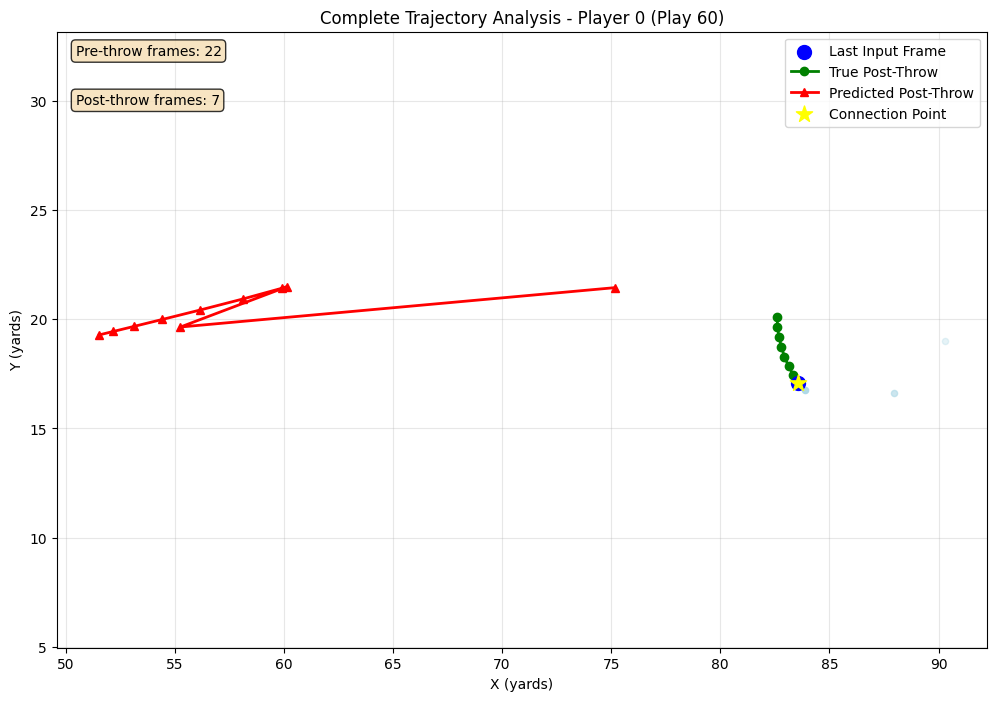


Connection Analysis for Player 0:
Last input position: (83.58, 17.09)
First predicted position: (75.17, 21.45)
First true position: (83.34, 17.46)
Prediction gap: 9.47 yards
True gap: 0.44 yards


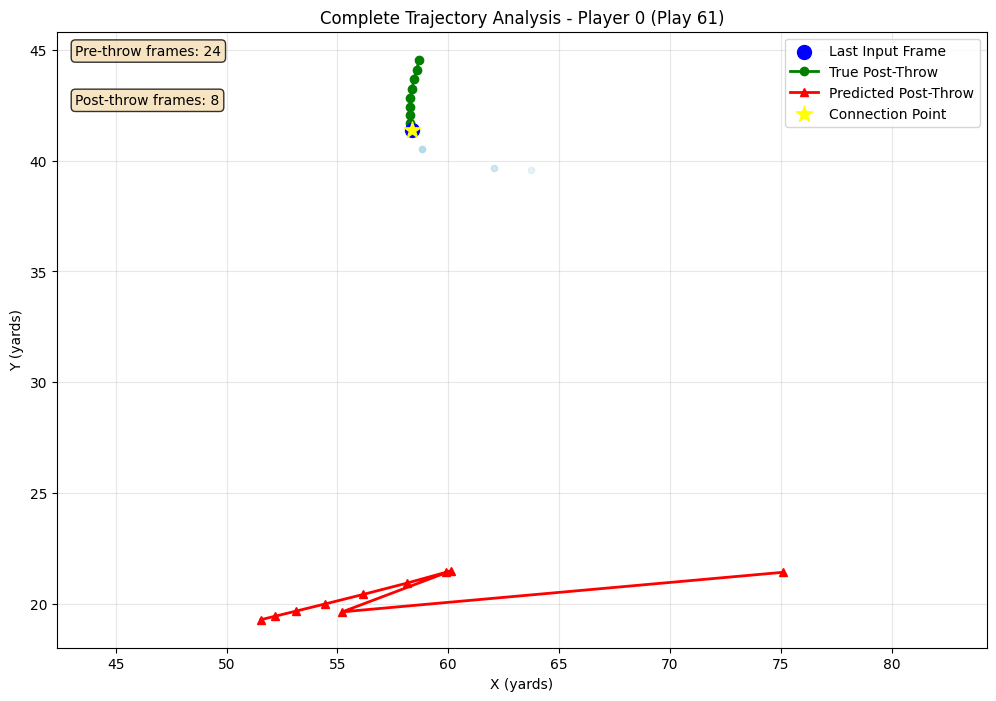


Connection Analysis for Player 0:
Last input position: (58.37, 41.36)
First predicted position: (75.09, 21.43)
First true position: (58.29, 41.69)
Prediction gap: 26.02 yards
True gap: 0.34 yards


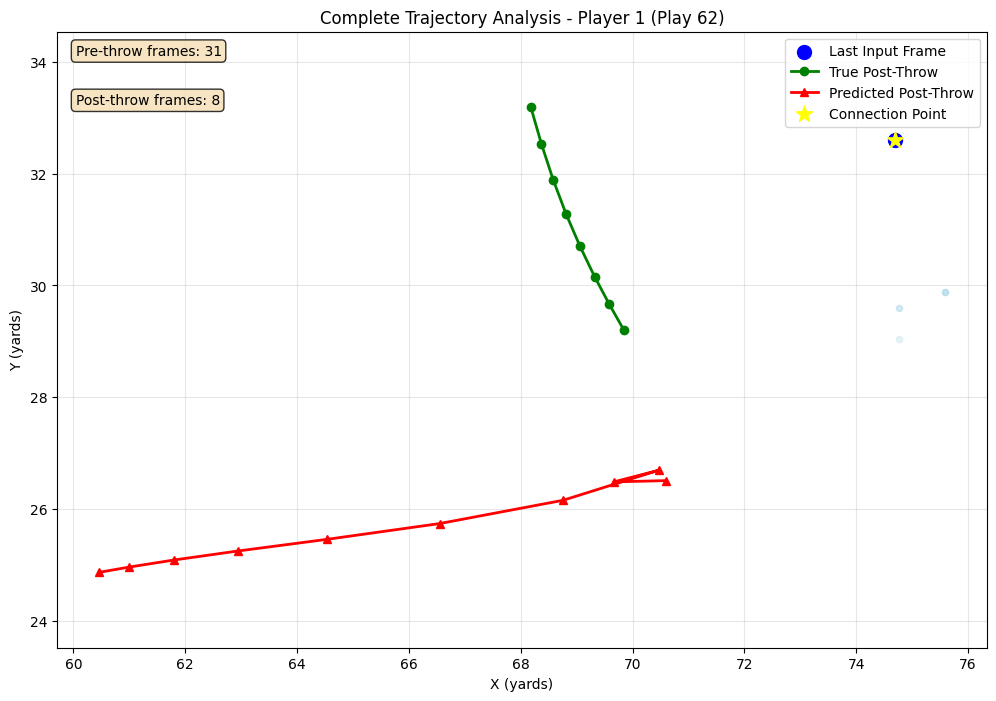


Connection Analysis for Player 1:
Last input position: (74.70, 32.60)
First predicted position: (70.60, 26.51)
First true position: (69.84, 29.21)
Prediction gap: 7.34 yards
True gap: 5.93 yards


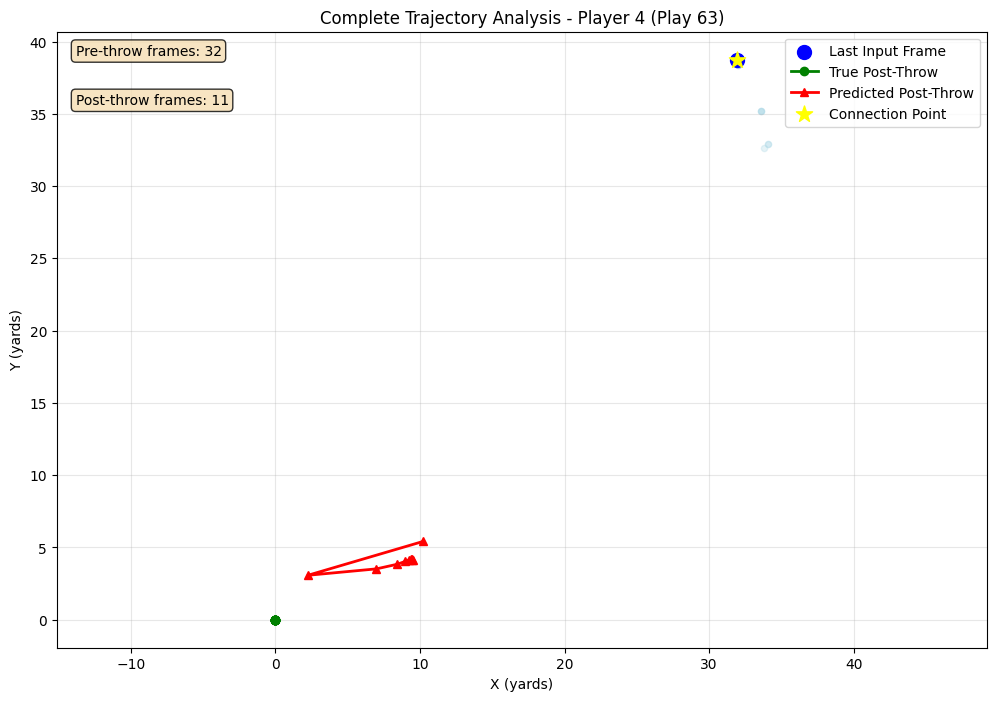


Connection Analysis for Player 4:
Last input position: (31.92, 38.74)
First predicted position: (10.24, 5.42)
First true position: (0.00, 0.00)
Prediction gap: 39.75 yards
True gap: 50.20 yards


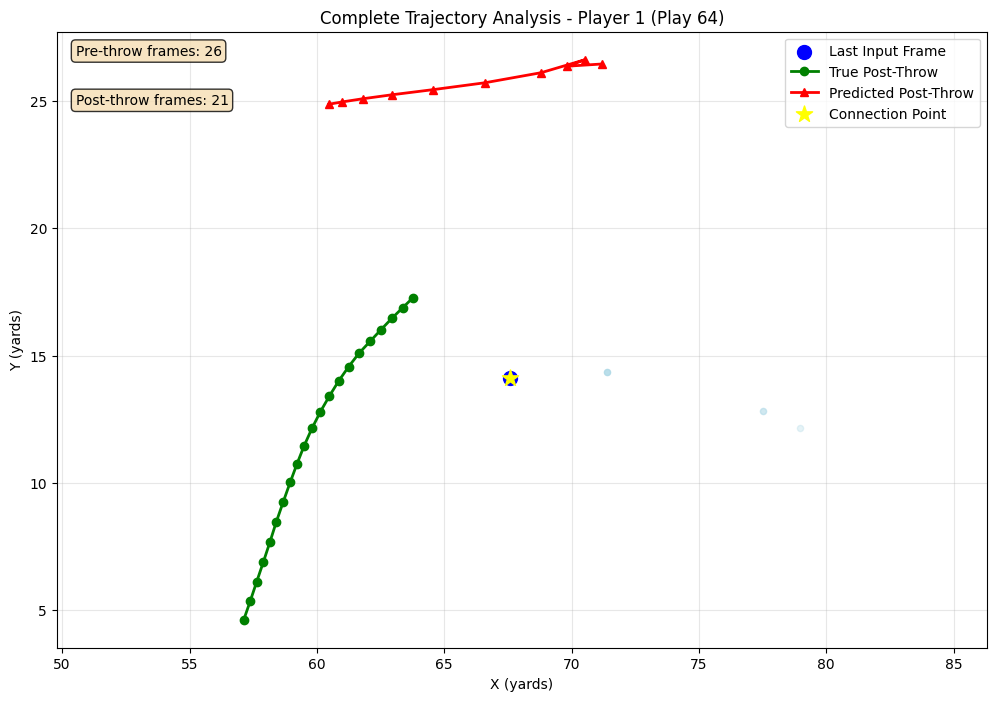


Connection Analysis for Player 1:
Last input position: (67.57, 14.14)
First predicted position: (71.18, 26.45)
First true position: (63.78, 17.28)
Prediction gap: 12.83 yards
True gap: 4.92 yards


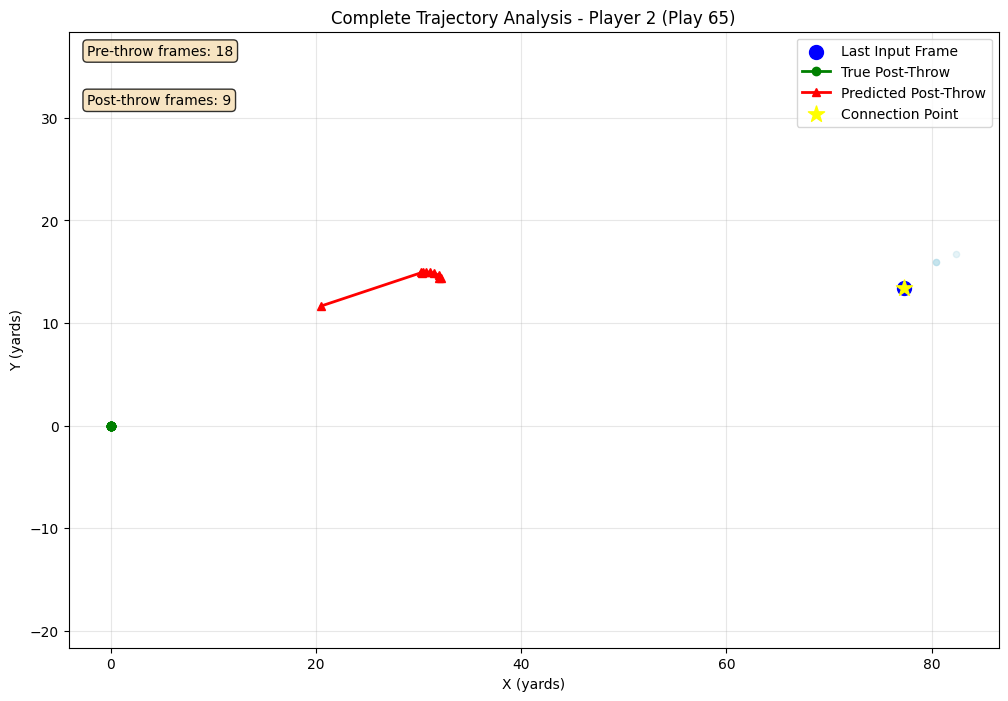


Connection Analysis for Player 2:
Last input position: (77.33, 13.40)
First predicted position: (20.52, 11.67)
First true position: (0.00, 0.00)
Prediction gap: 56.83 yards
True gap: 78.48 yards


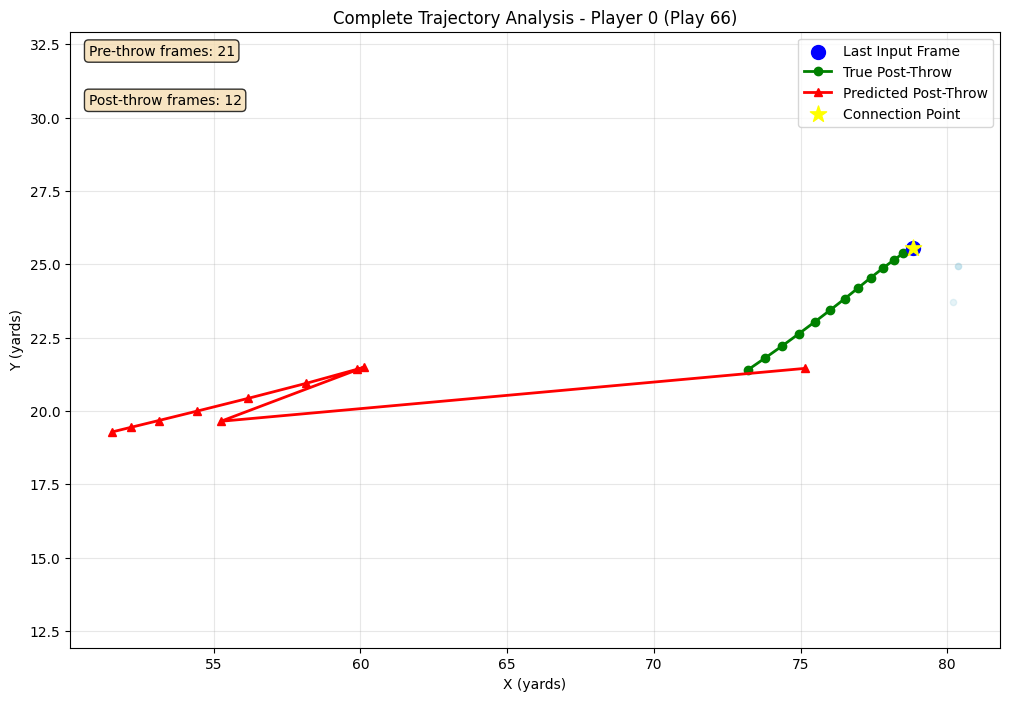


Connection Analysis for Player 0:
Last input position: (78.83, 25.57)
First predicted position: (75.15, 21.45)
First true position: (78.51, 25.38)
Prediction gap: 5.52 yards
True gap: 0.37 yards


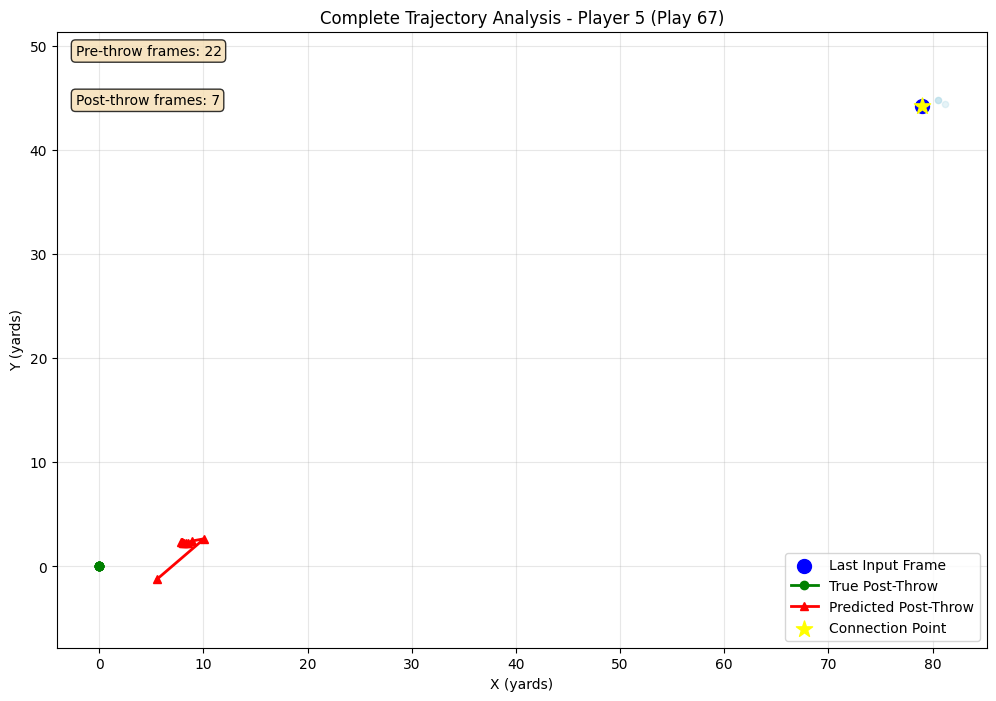


Connection Analysis for Player 5:
Last input position: (78.98, 44.23)
First predicted position: (5.57, -1.21)
First true position: (0.00, 0.00)
Prediction gap: 86.33 yards
True gap: 90.52 yards


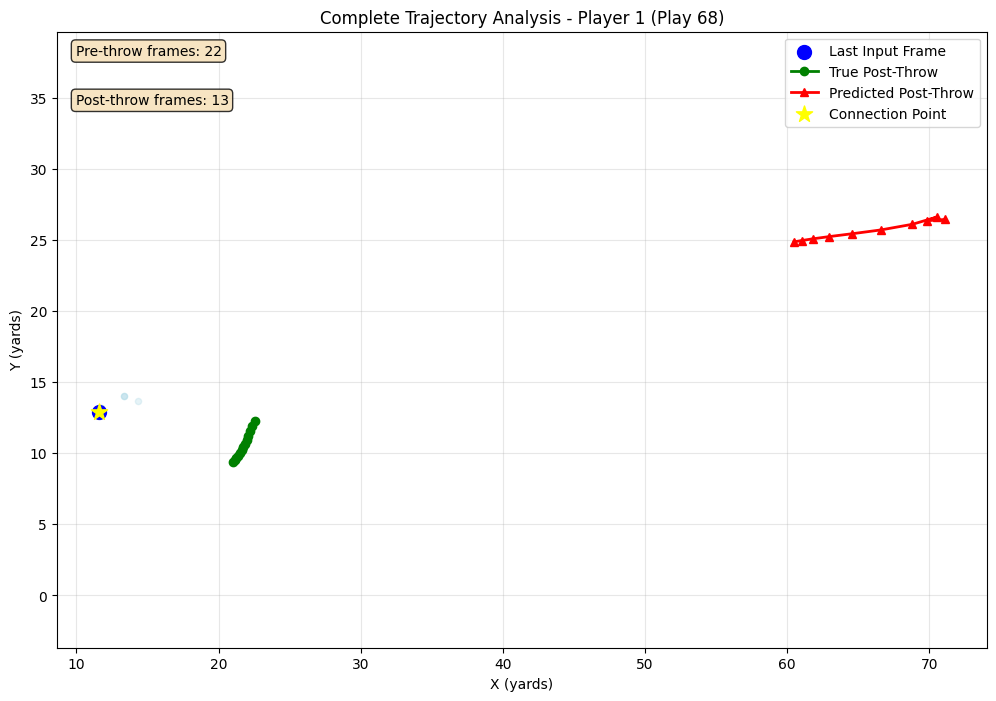


Connection Analysis for Player 1:
Last input position: (11.60, 12.88)
First predicted position: (71.07, 26.44)
First true position: (22.53, 12.24)
Prediction gap: 61.00 yards
True gap: 10.95 yards


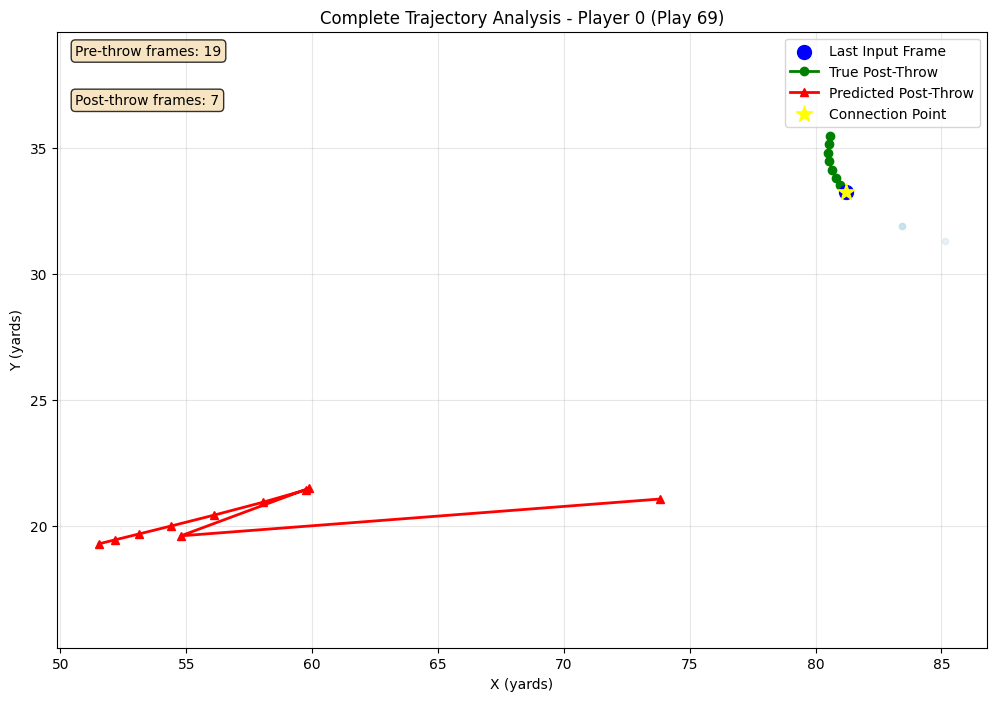


Connection Analysis for Player 0:
Last input position: (81.20, 33.27)
First predicted position: (73.82, 21.06)
First true position: (80.98, 33.53)
Prediction gap: 14.26 yards
True gap: 0.34 yards


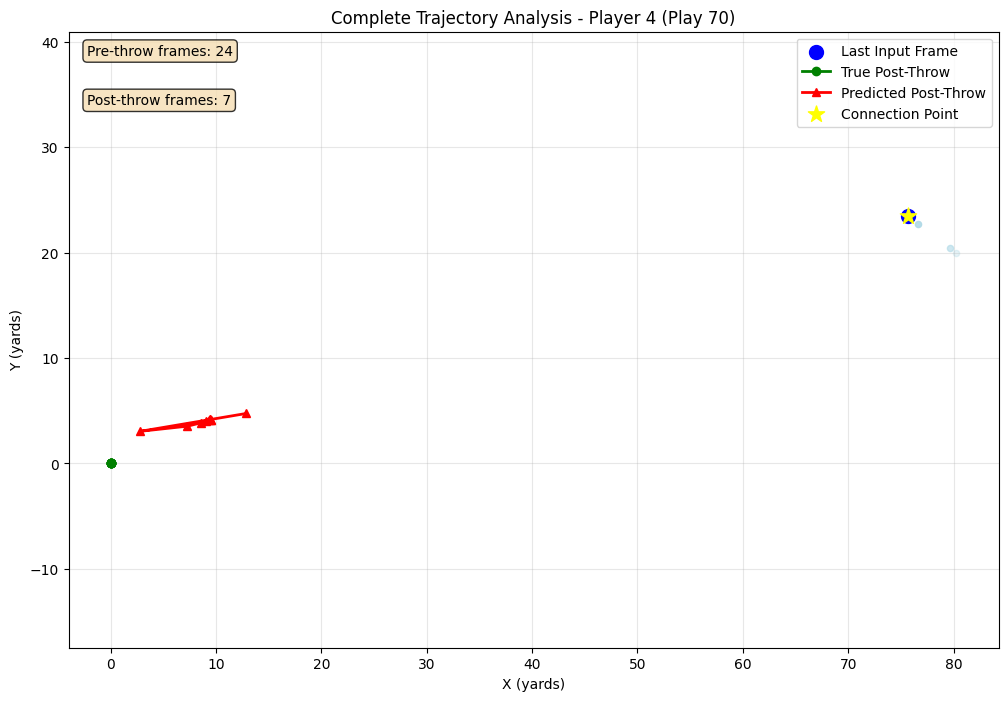


Connection Analysis for Player 4:
Last input position: (75.70, 23.48)
First predicted position: (12.85, 4.74)
First true position: (0.00, 0.00)
Prediction gap: 65.58 yards
True gap: 79.26 yards


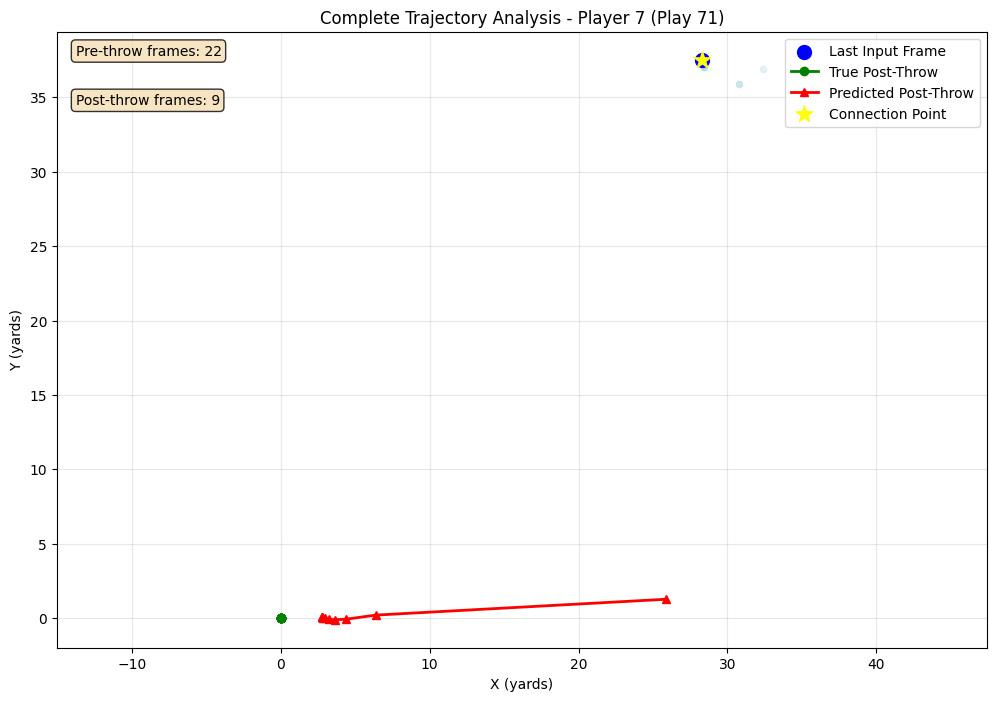


Connection Analysis for Player 7:
Last input position: (28.33, 37.53)
First predicted position: (25.86, 1.26)
First true position: (0.00, 0.00)
Prediction gap: 36.35 yards
True gap: 47.02 yards


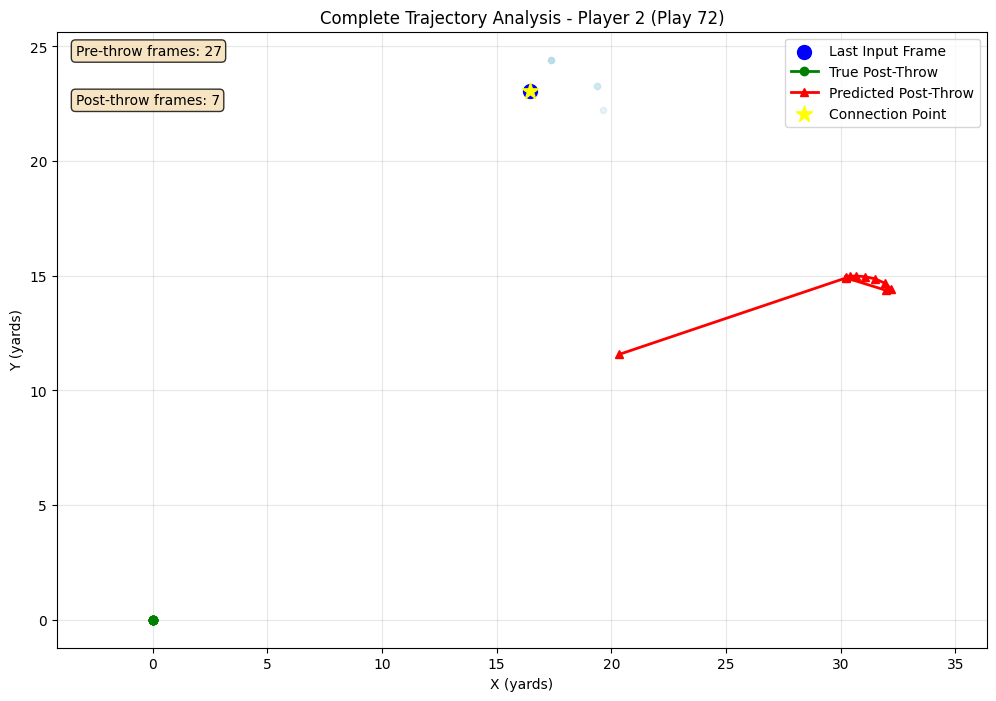


Connection Analysis for Player 2:
Last input position: (16.45, 23.07)
First predicted position: (20.35, 11.57)
First true position: (0.00, 0.00)
Prediction gap: 12.14 yards
True gap: 28.33 yards


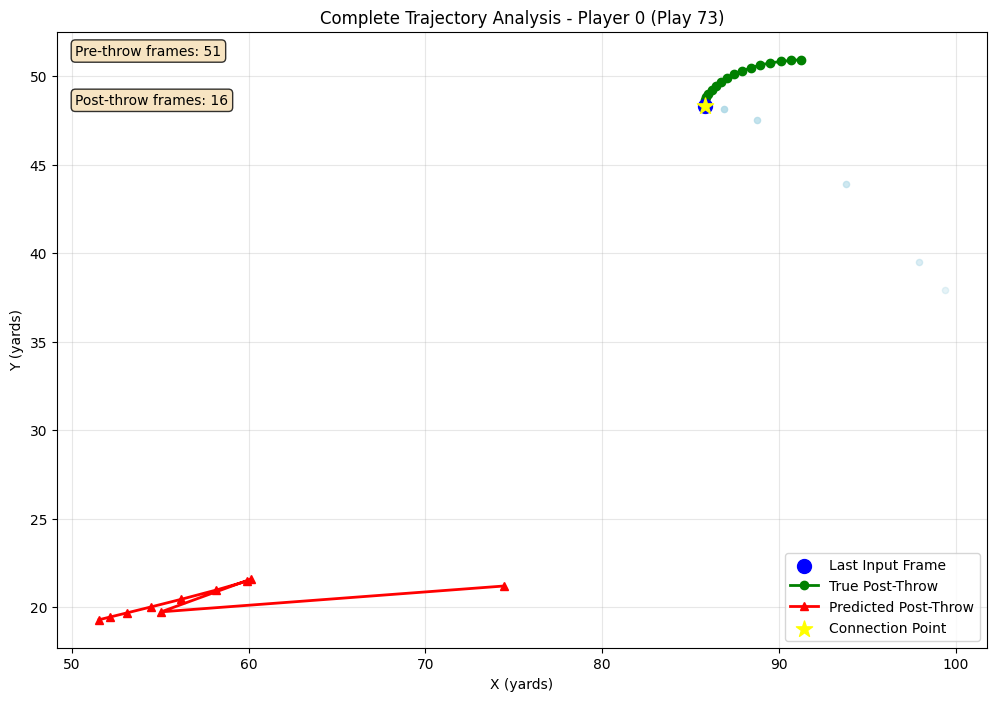


Connection Analysis for Player 0:
Last input position: (85.81, 48.33)
First predicted position: (74.44, 21.20)
First true position: (85.78, 48.48)
Prediction gap: 29.42 yards
True gap: 0.15 yards


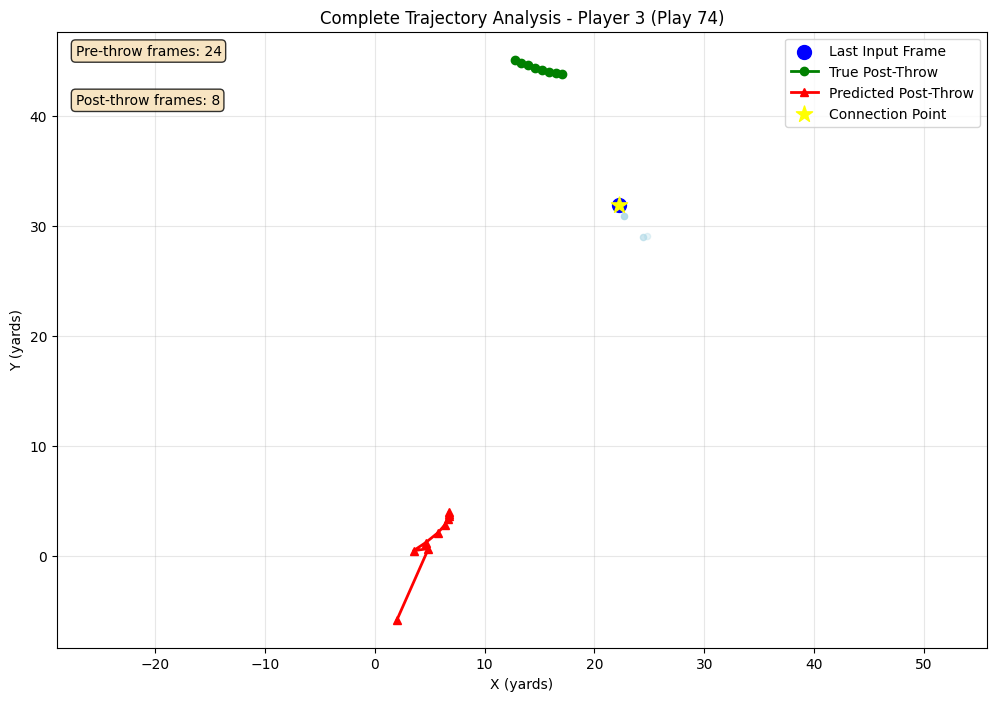


Connection Analysis for Player 3:
Last input position: (22.25, 31.88)
First predicted position: (2.04, -5.84)
First true position: (17.05, 43.79)
Prediction gap: 42.80 yards
True gap: 13.00 yards


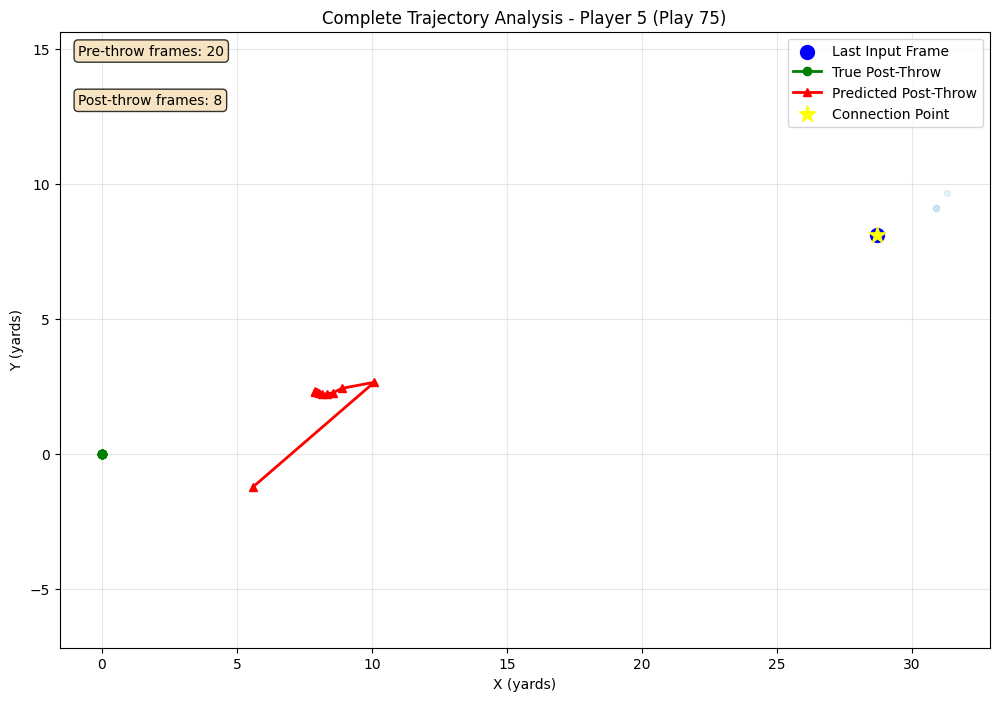


Connection Analysis for Player 5:
Last input position: (28.71, 8.12)
First predicted position: (5.60, -1.21)
First true position: (0.00, 0.00)
Prediction gap: 24.92 yards
True gap: 29.84 yards


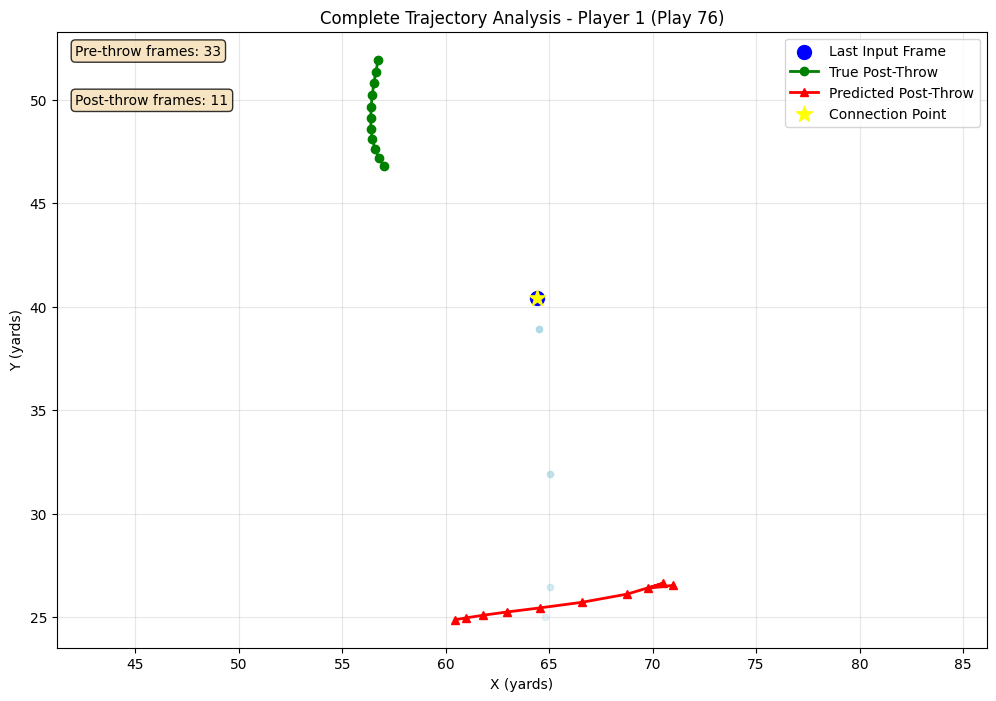


Connection Analysis for Player 1:
Last input position: (64.43, 40.42)
First predicted position: (70.98, 26.53)
First true position: (57.02, 46.79)
Prediction gap: 15.35 yards
True gap: 9.77 yards


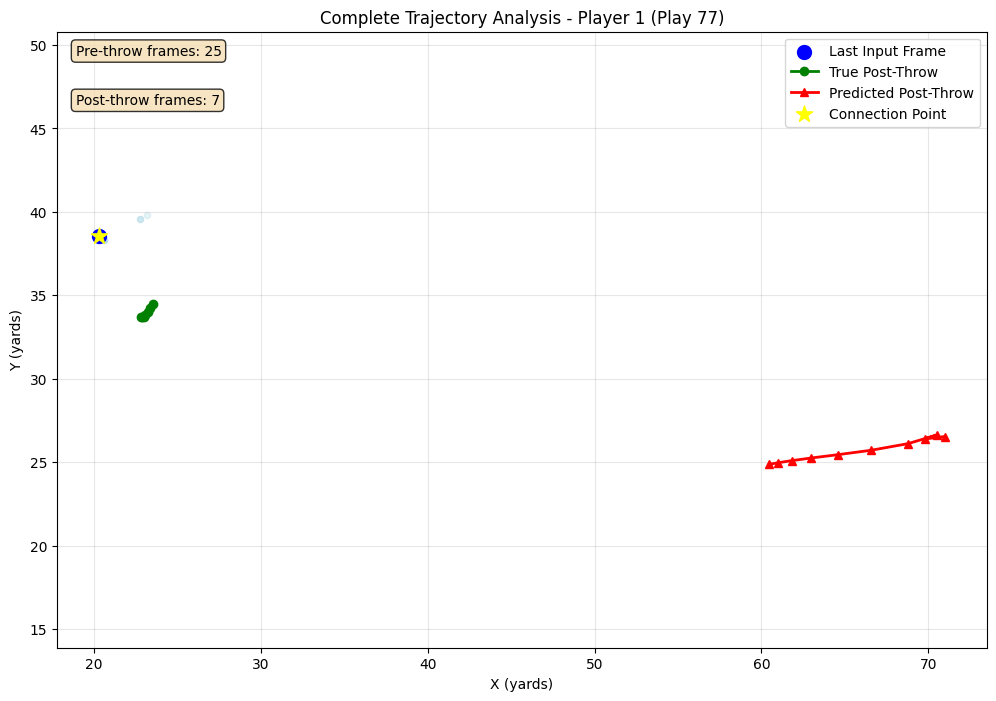


Connection Analysis for Player 1:
Last input position: (20.31, 38.55)
First predicted position: (70.98, 26.53)
First true position: (22.84, 33.69)
Prediction gap: 52.08 yards
True gap: 5.48 yards


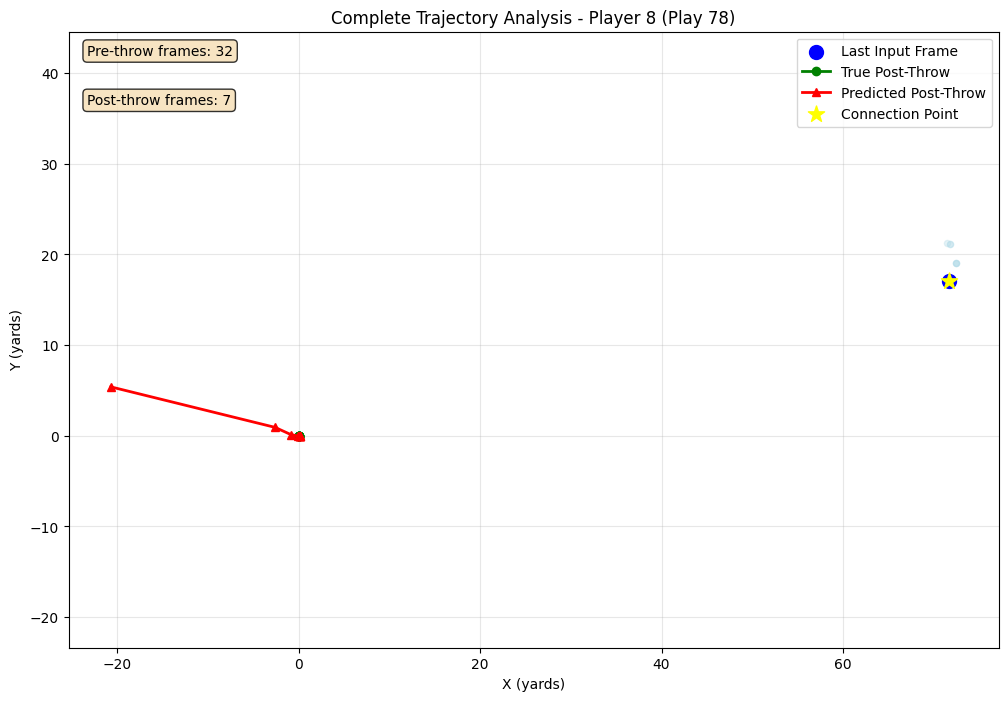


Connection Analysis for Player 8:
Last input position: (71.71, 17.07)
First predicted position: (-20.74, 5.40)
First true position: (0.00, 0.00)
Prediction gap: 93.18 yards
True gap: 73.71 yards


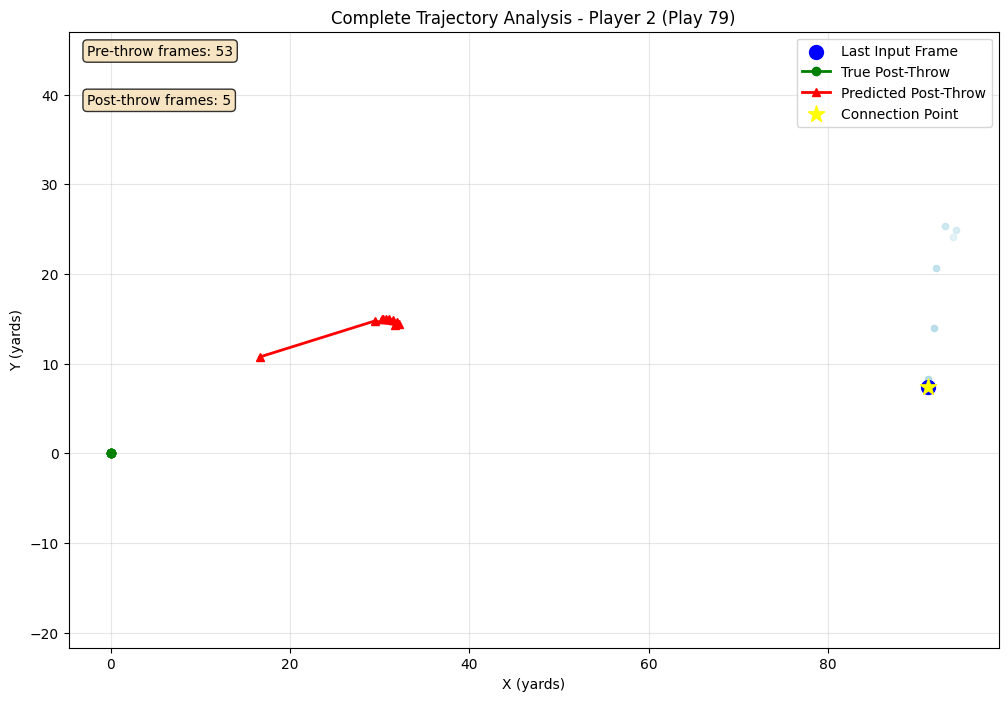


Connection Analysis for Player 2:
Last input position: (91.15, 7.44)
First predicted position: (16.61, 10.74)
First true position: (0.00, 0.00)
Prediction gap: 74.62 yards
True gap: 91.45 yards


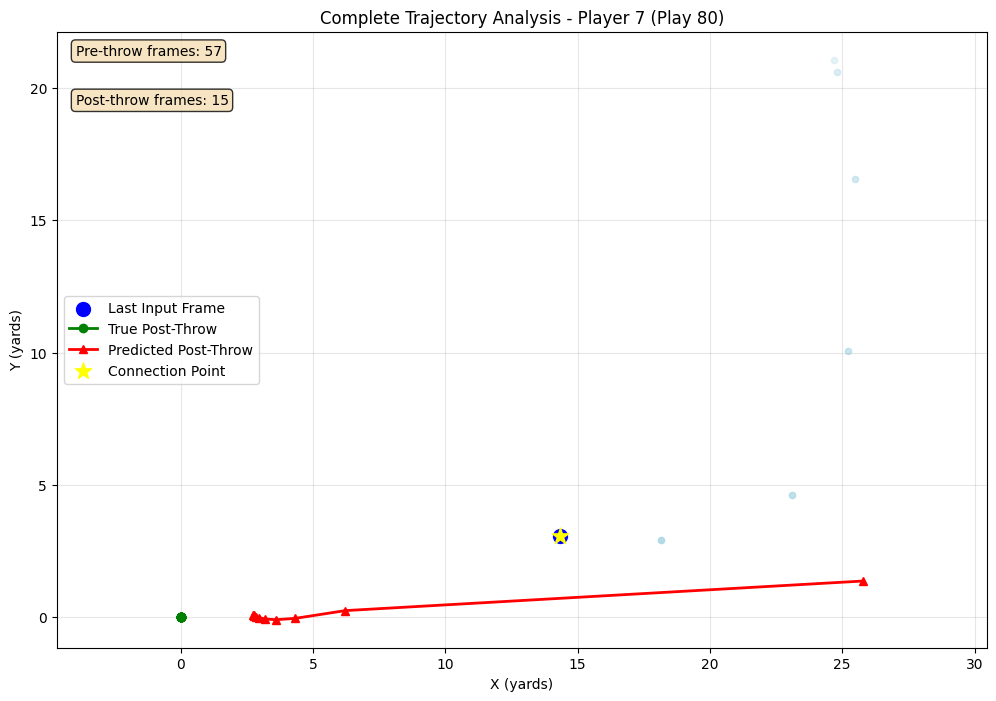


Connection Analysis for Player 7:
Last input position: (14.32, 3.09)
First predicted position: (25.79, 1.37)
First true position: (0.00, 0.00)
Prediction gap: 11.60 yards
True gap: 14.65 yards


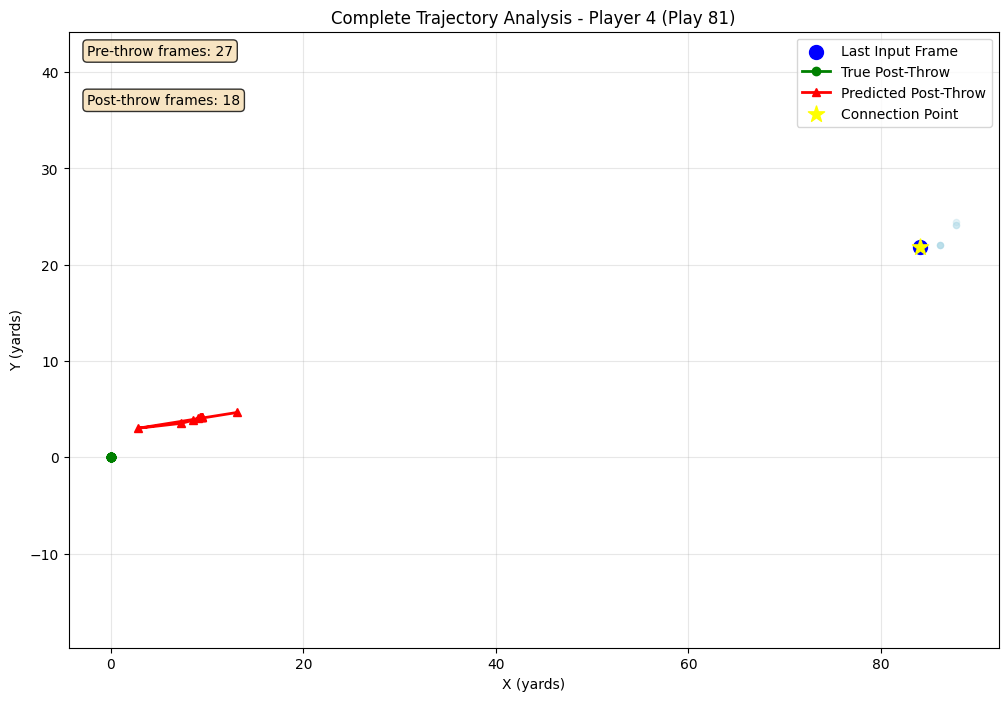


Connection Analysis for Player 4:
Last input position: (84.02, 21.86)
First predicted position: (13.12, 4.65)
First true position: (0.00, 0.00)
Prediction gap: 72.95 yards
True gap: 86.82 yards


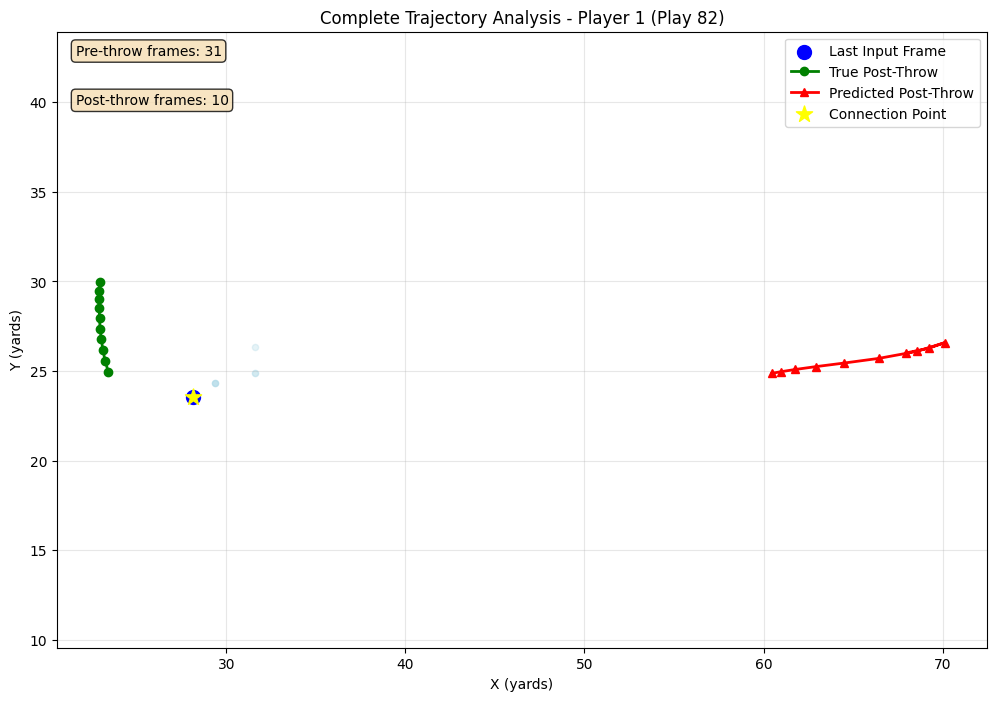


Connection Analysis for Player 1:
Last input position: (28.14, 23.53)
First predicted position: (67.97, 26.01)
First true position: (23.42, 24.95)
Prediction gap: 39.90 yards
True gap: 4.93 yards


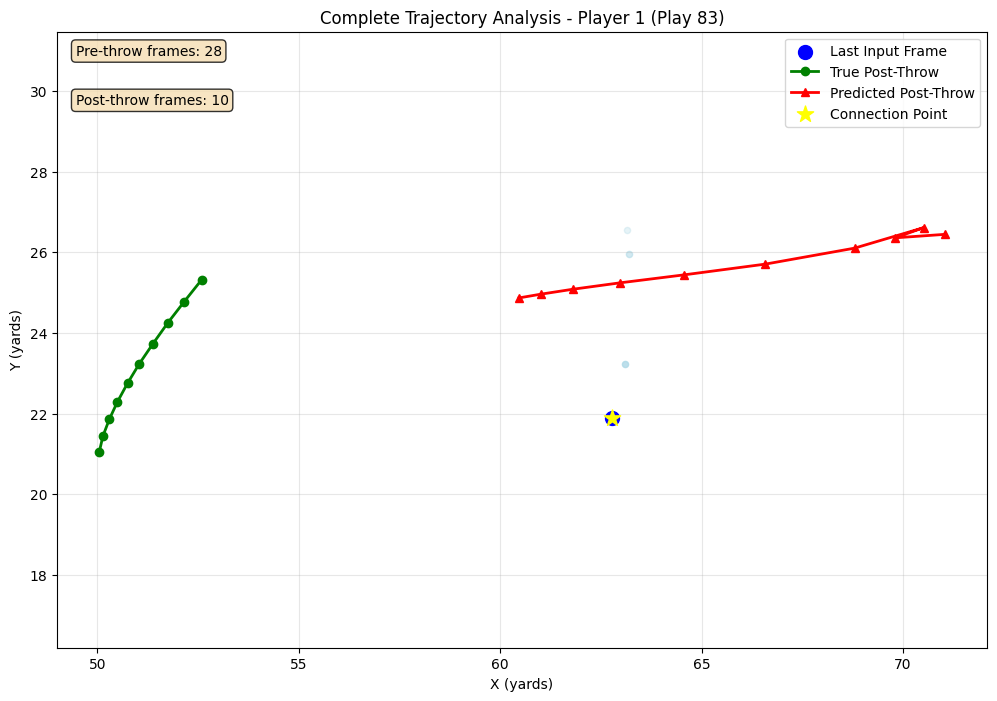


Connection Analysis for Player 1:
Last input position: (62.77, 21.89)
First predicted position: (71.04, 26.45)
First true position: (50.05, 21.05)
Prediction gap: 9.44 yards
True gap: 12.75 yards


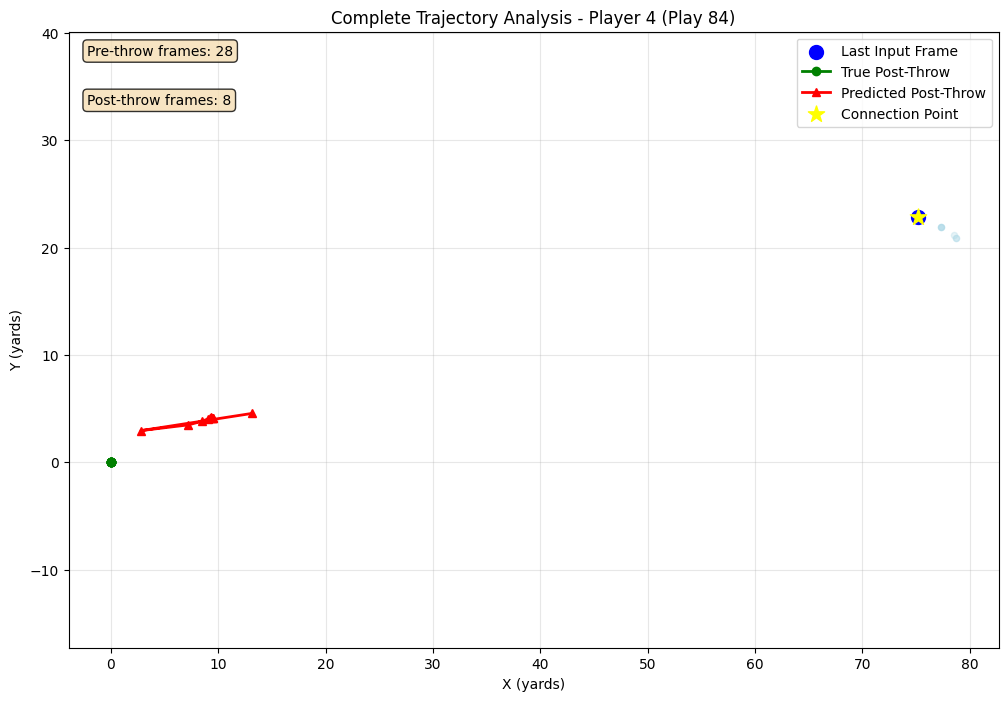


Connection Analysis for Player 4:
Last input position: (75.18, 22.84)
First predicted position: (13.14, 4.55)
First true position: (0.00, 0.00)
Prediction gap: 64.68 yards
True gap: 78.57 yards


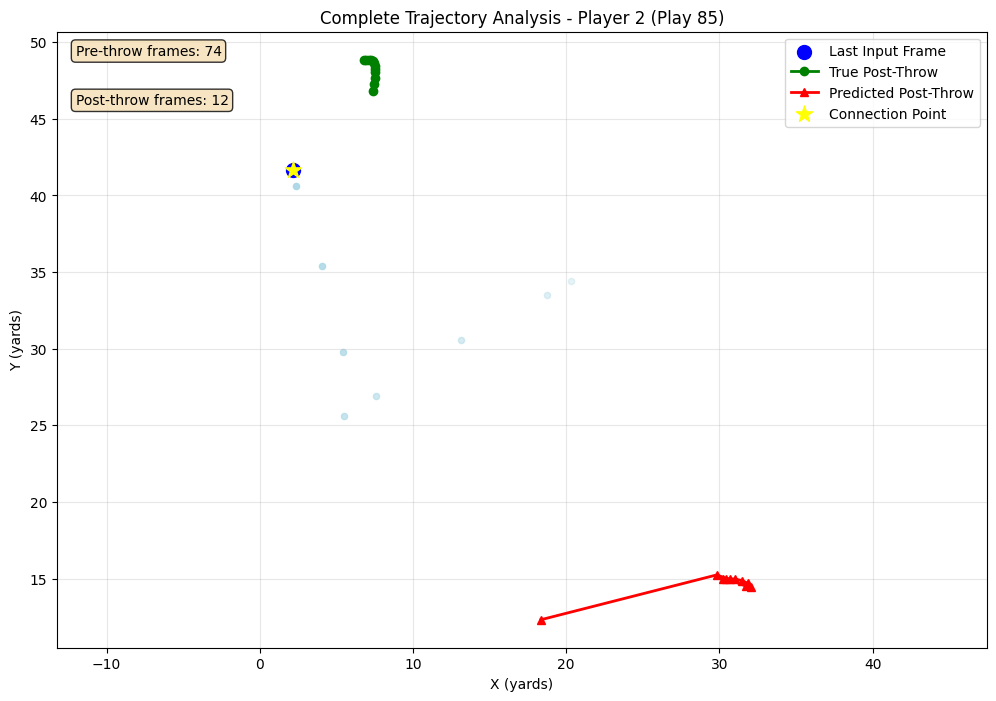


Connection Analysis for Player 2:
Last input position: (2.15, 41.65)
First predicted position: (18.35, 12.32)
First true position: (7.38, 46.82)
Prediction gap: 33.51 yards
True gap: 7.35 yards


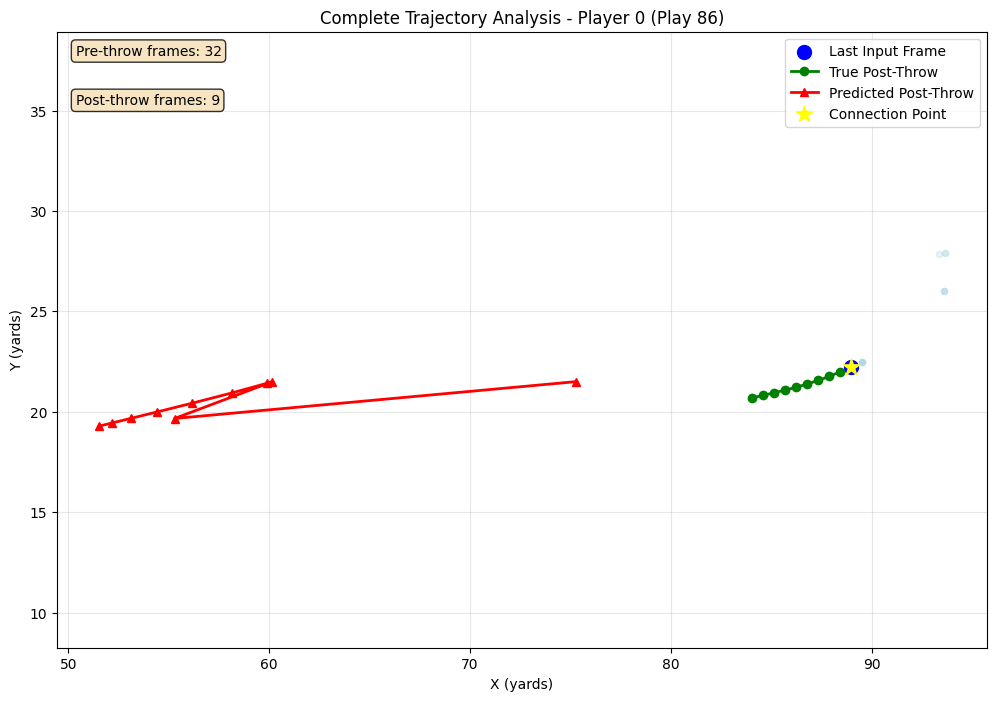


Connection Analysis for Player 0:
Last input position: (88.98, 22.23)
First predicted position: (75.27, 21.50)
First true position: (88.43, 21.99)
Prediction gap: 13.73 yards
True gap: 0.60 yards


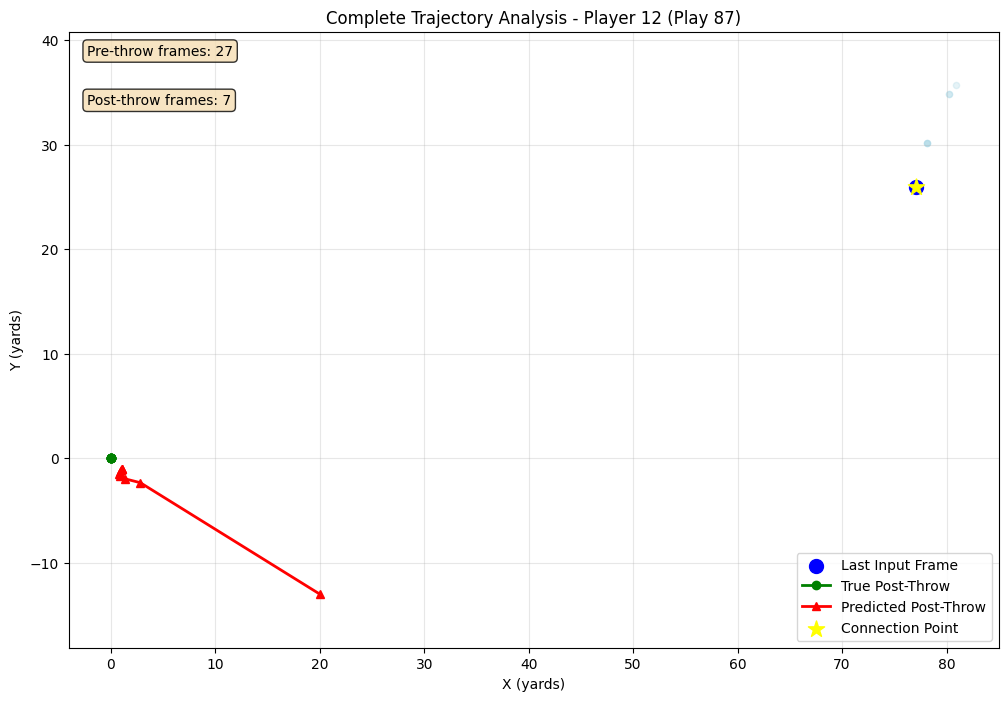


Connection Analysis for Player 12:
Last input position: (77.11, 25.99)
First predicted position: (19.98, -13.00)
First true position: (0.00, 0.00)
Prediction gap: 69.16 yards
True gap: 81.37 yards


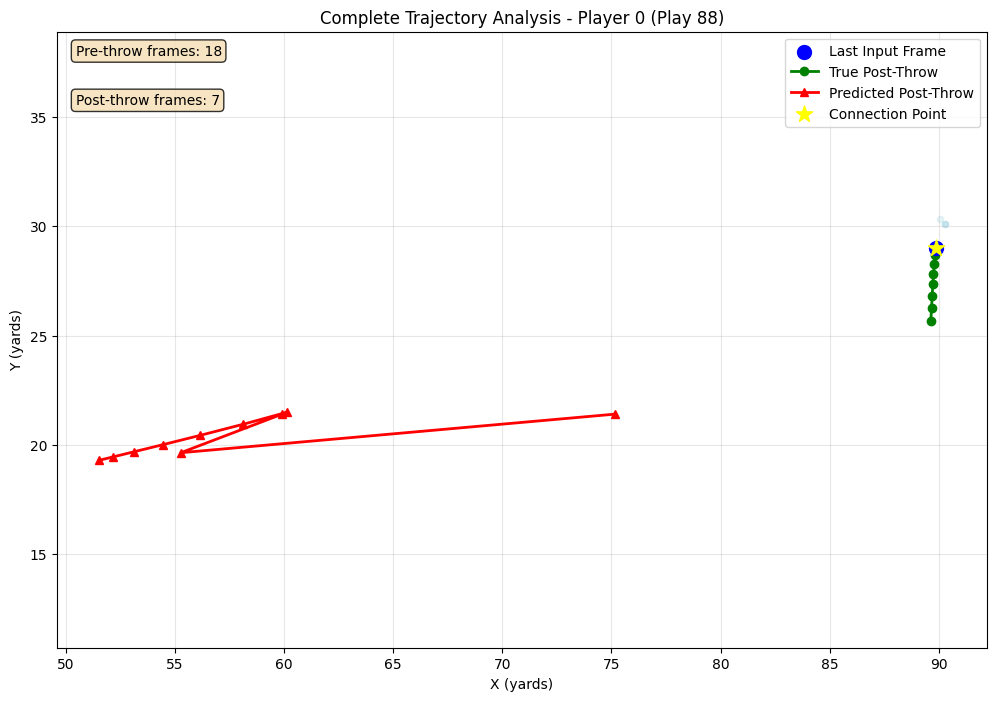


Connection Analysis for Player 0:
Last input position: (89.88, 29.03)
First predicted position: (75.17, 21.40)
First true position: (89.83, 28.68)
Prediction gap: 16.57 yards
True gap: 0.35 yards


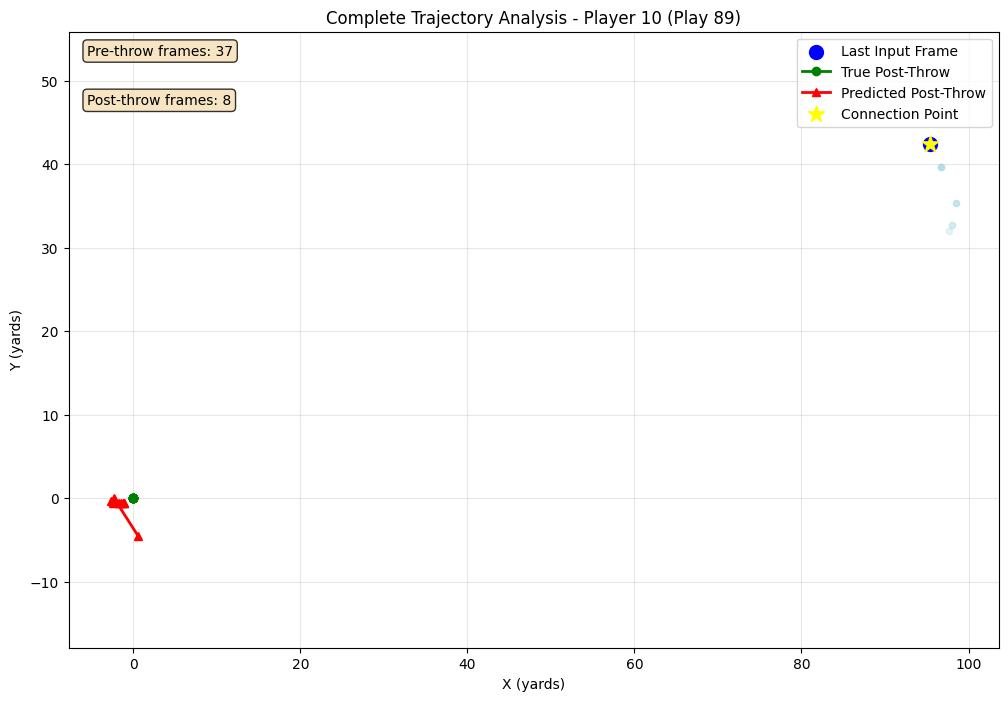


Connection Analysis for Player 10:
Last input position: (95.39, 42.44)
First predicted position: (0.57, -4.49)
First true position: (0.00, 0.00)
Prediction gap: 105.80 yards
True gap: 104.41 yards


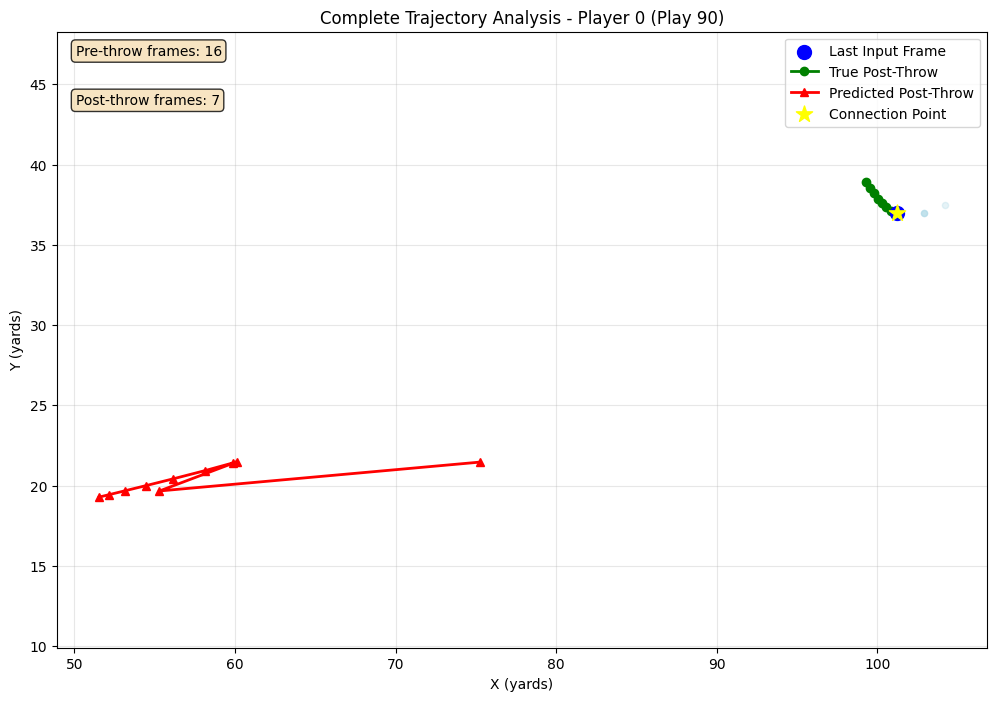


Connection Analysis for Player 0:
Last input position: (101.21, 36.97)
First predicted position: (75.25, 21.47)
First true position: (100.88, 37.12)
Prediction gap: 30.24 yards
True gap: 0.36 yards


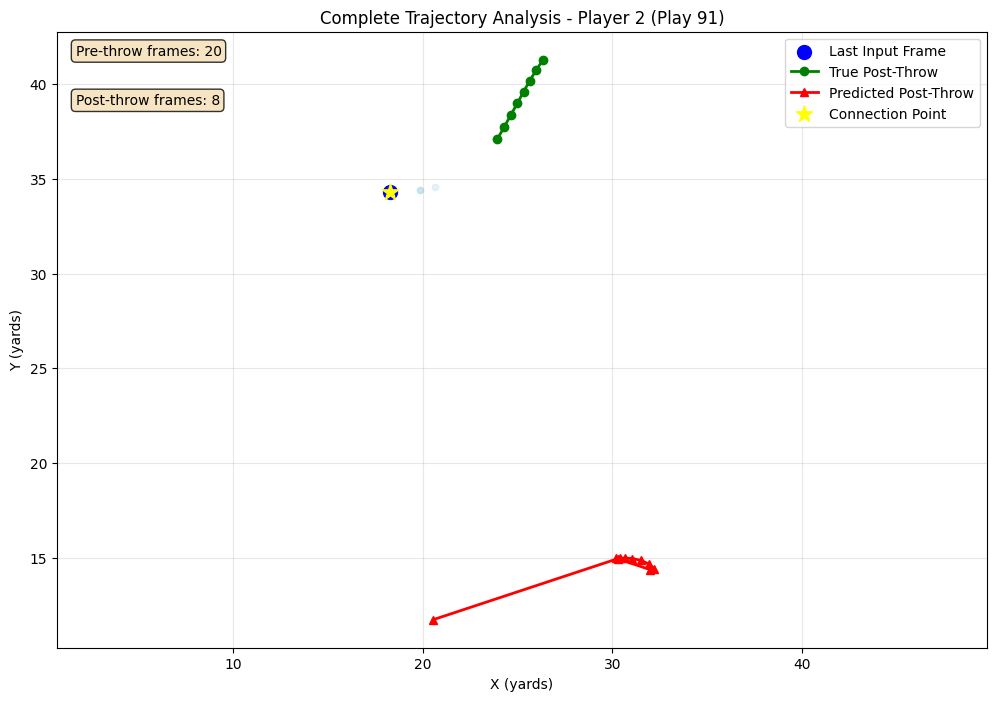


Connection Analysis for Player 2:
Last input position: (18.26, 34.29)
First predicted position: (20.54, 11.73)
First true position: (26.35, 41.29)
Prediction gap: 22.68 yards
True gap: 10.70 yards


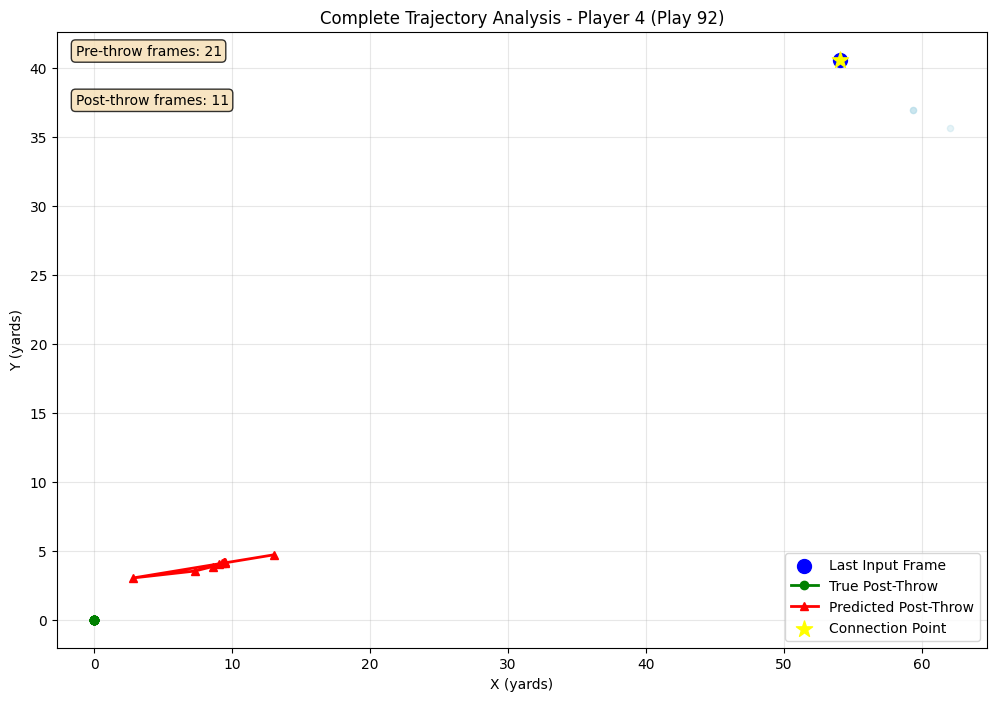


Connection Analysis for Player 4:
Last input position: (54.05, 40.61)
First predicted position: (13.01, 4.70)
First true position: (0.00, 0.00)
Prediction gap: 54.53 yards
True gap: 67.61 yards


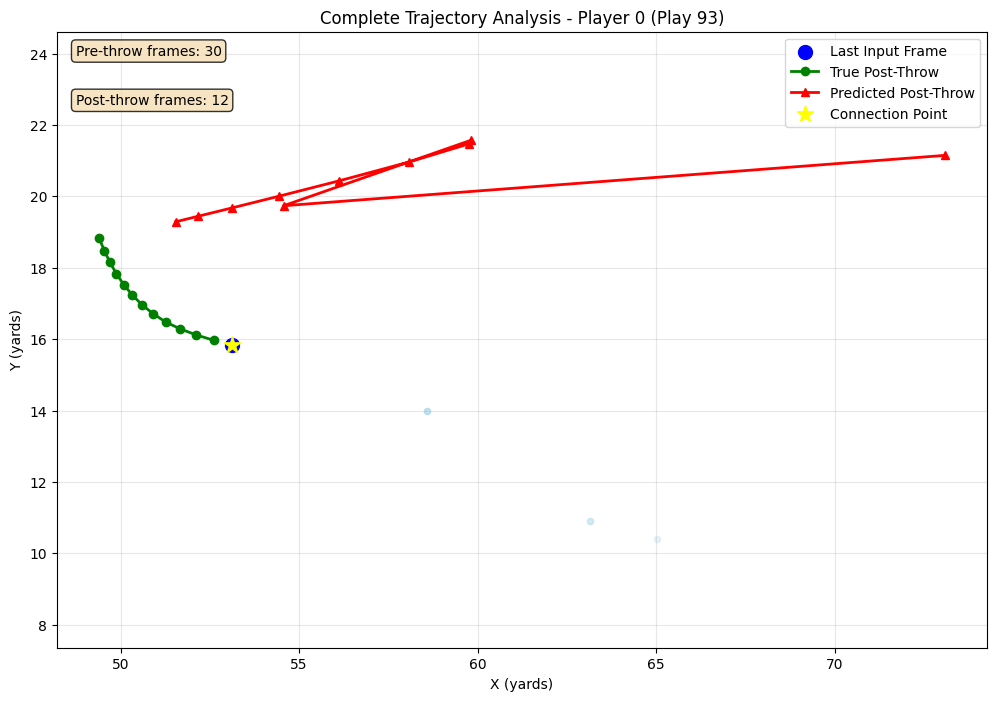


Connection Analysis for Player 0:
Last input position: (53.13, 15.84)
First predicted position: (73.09, 21.15)
First true position: (52.60, 15.97)
Prediction gap: 20.65 yards
True gap: 0.55 yards


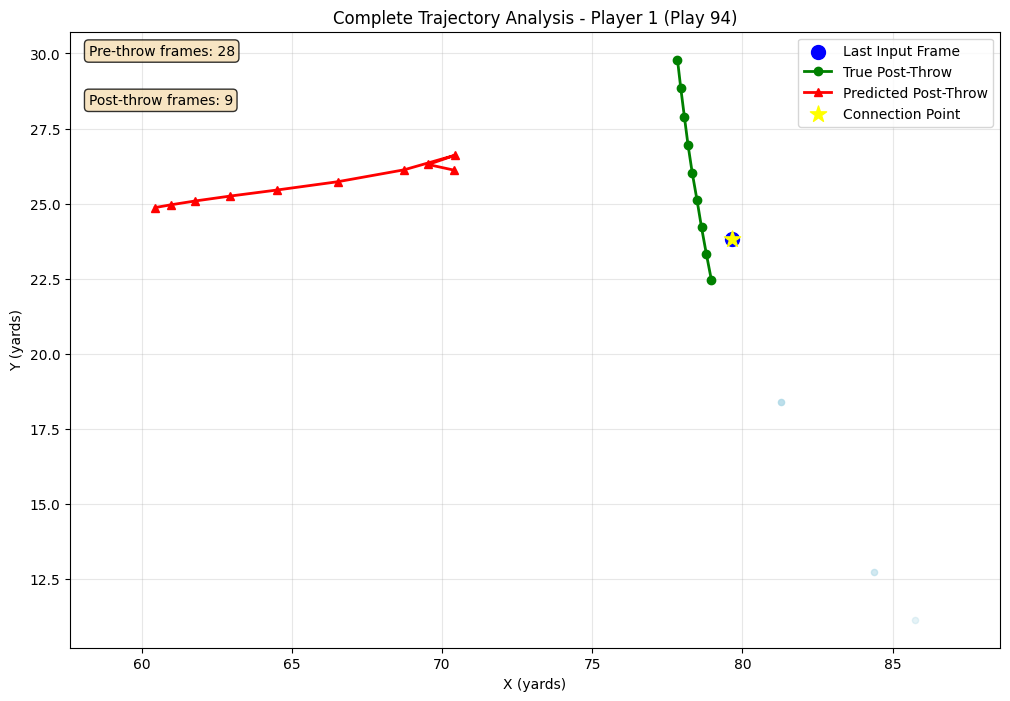


Connection Analysis for Player 1:
Last input position: (79.64, 23.82)
First predicted position: (70.40, 26.11)
First true position: (78.97, 22.45)
Prediction gap: 9.52 yards
True gap: 1.53 yards


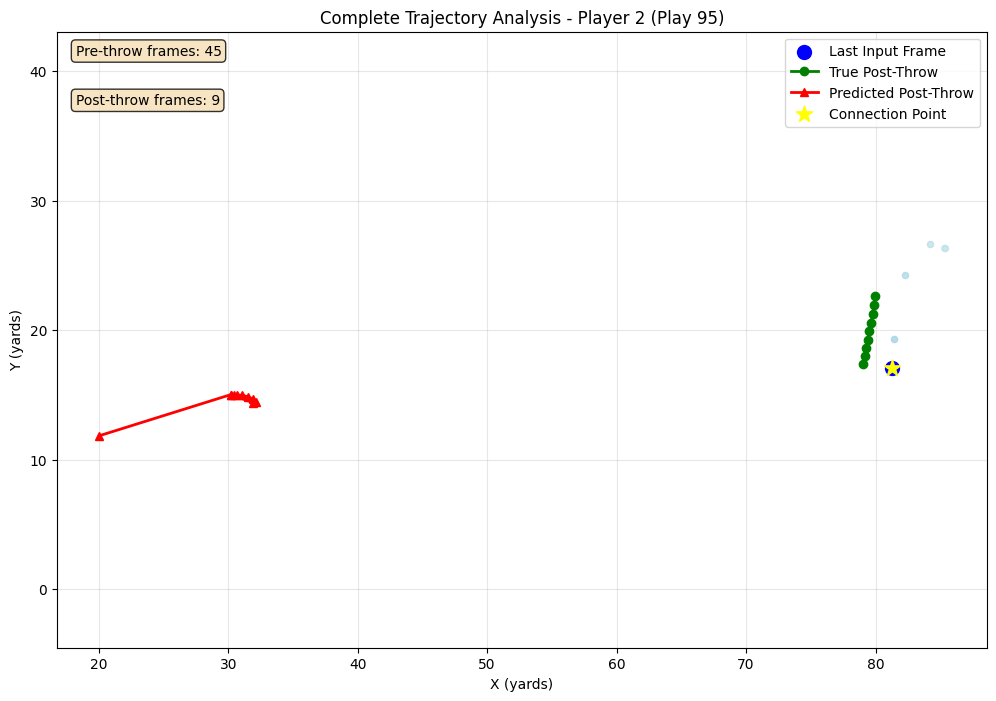


Connection Analysis for Player 2:
Last input position: (81.28, 17.11)
First predicted position: (20.02, 11.84)
First true position: (79.99, 22.61)
Prediction gap: 61.48 yards
True gap: 5.65 yards


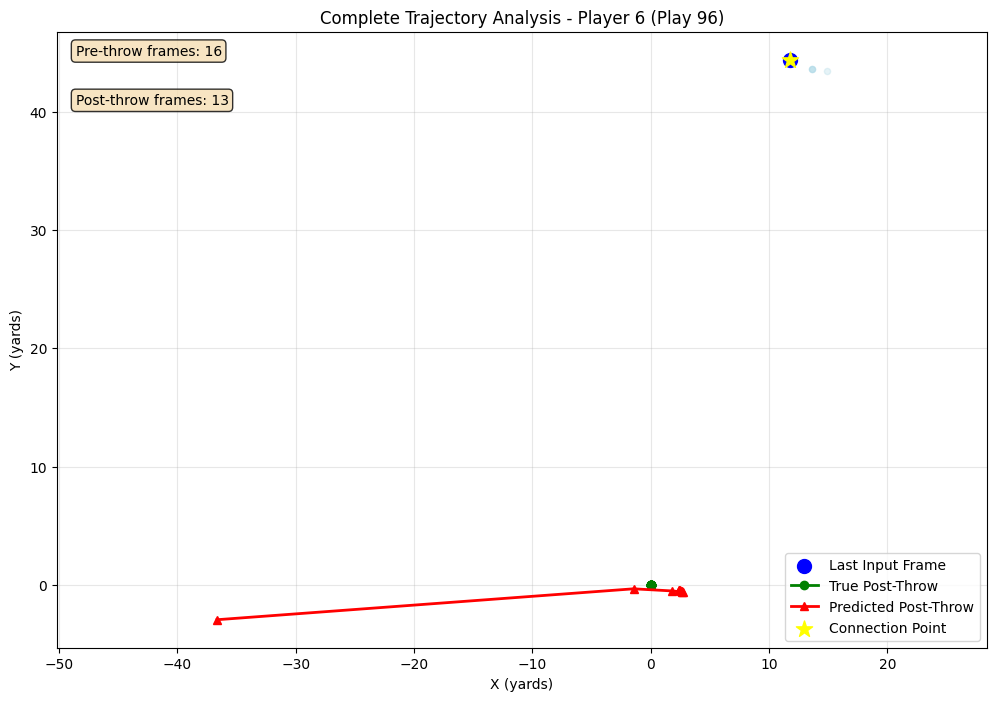


Connection Analysis for Player 6:
Last input position: (11.82, 44.38)
First predicted position: (-36.64, -2.94)
First true position: (0.00, 0.00)
Prediction gap: 67.74 yards
True gap: 45.93 yards


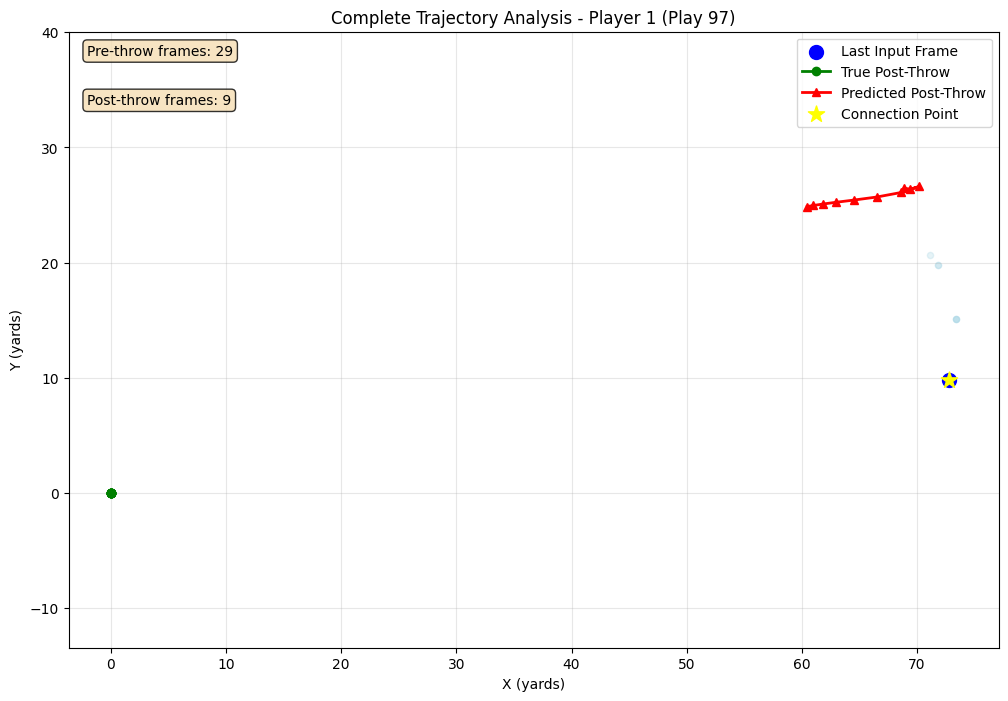


Connection Analysis for Player 1:
Last input position: (72.81, 9.83)
First predicted position: (68.90, 26.46)
First true position: (0.00, 0.00)
Prediction gap: 17.09 yards
True gap: 73.47 yards


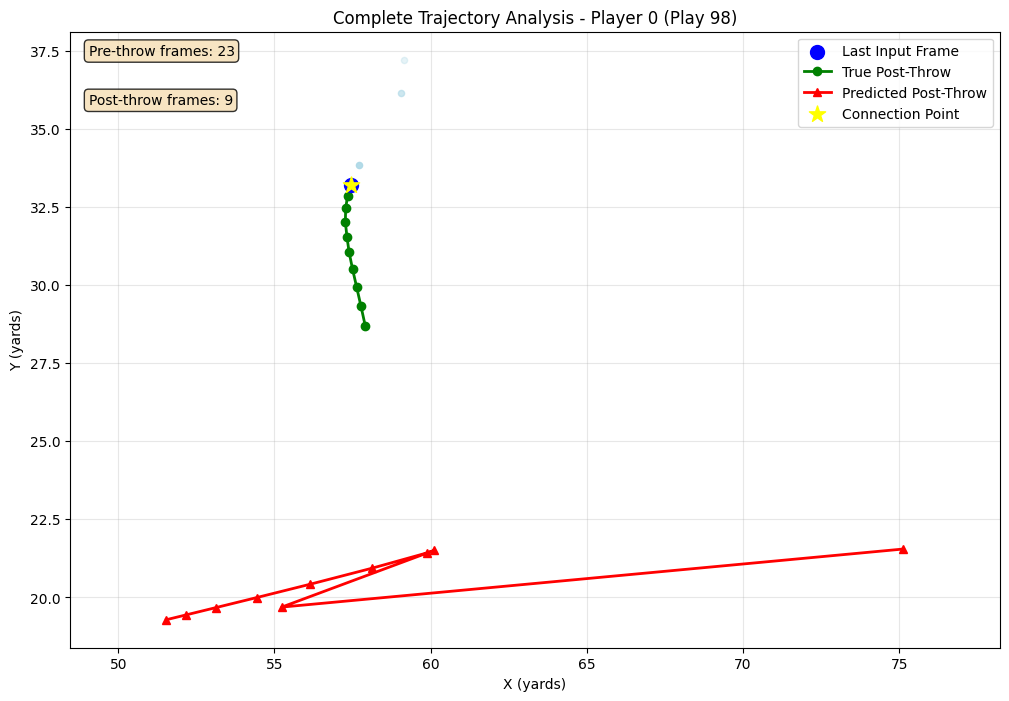


Connection Analysis for Player 0:
Last input position: (57.44, 33.21)
First predicted position: (75.13, 21.55)
First true position: (57.34, 32.85)
Prediction gap: 21.19 yards
True gap: 0.37 yards


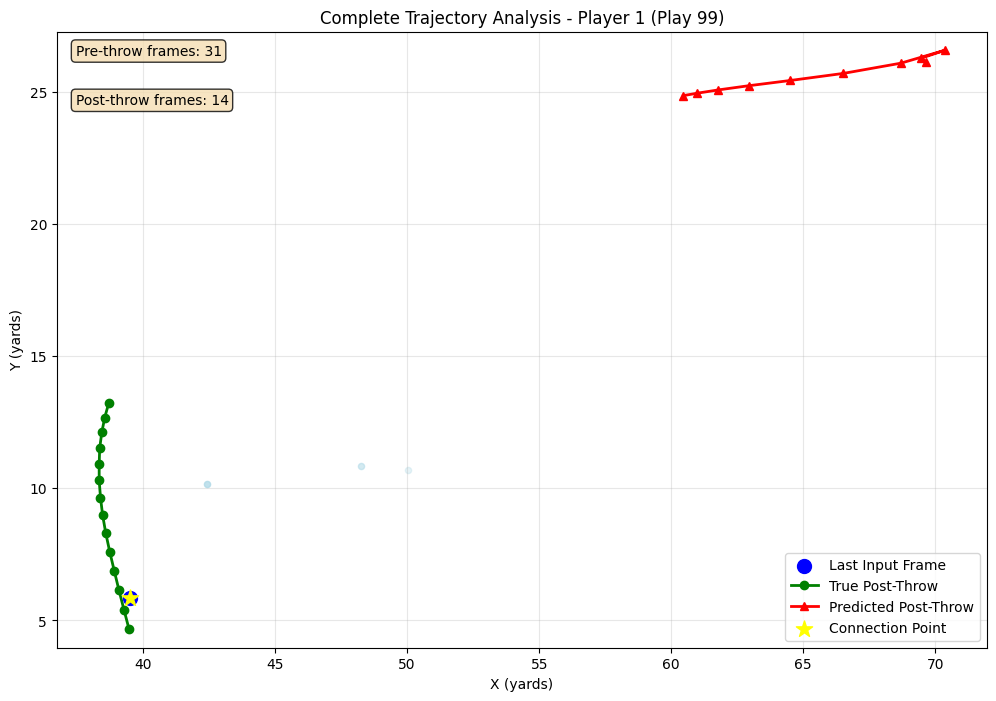


Connection Analysis for Player 1:
Last input position: (39.50, 5.84)
First predicted position: (69.66, 26.13)
First true position: (38.70, 13.22)
Prediction gap: 36.36 yards
True gap: 7.42 yards


In [14]:
# Visualize pre-throw path + predicted + true post-throw paths
import matplotlib.pyplot as plt
import numpy as np

for sample_idx in range(20, 100):
    target_player_idx = 0  # or use mask to find target player

    # Get input data (pre-throw frames)
    X_sample = torch.tensor(X_data[sample_idx:sample_idx+1], dtype=torch.float32, device=device)
    mask = masks[sample_idx]

    # Get the last frame of input data (pre-throw)
    last_input_frame = X_sample[0, -1, :, :2].cpu().numpy()  # Last frame, all players, x,y coords
    last_input_frame_denorm = last_input_frame.copy()
    last_input_frame_denorm[:, 0] *= FIELD_X
    last_input_frame_denorm[:, 1] *= FIELD_Y

    # Get predictions (post-throw)
    graph_model.eval()
    with torch.no_grad():
        adj_intra_seq = adj_intra_all[sample_idx:sample_idx+1]
        adj_bipartite_seq = adj_bipartite_all[sample_idx:sample_idx+1]
        adj_to_landing_seq = adj_to_landing_all[sample_idx:sample_idx+1]
        
        Y_pred_graph = graph_model(
            X_sample, 
            adj_intra_seq, 
            adj_bipartite_seq, 
            adj_to_landing_seq,
            seq_out
        ).cpu().numpy()[0]

    # Get true post-throw data
    Y_true = Y_data[sample_idx]
    Y_true_denorm = Y_true.copy()
    Y_true_denorm[..., 0] *= FIELD_X
    Y_true_denorm[..., 1] *= FIELD_Y

    Y_pred_graph_denorm = Y_pred_graph.copy()
    Y_pred_graph_denorm[..., 0] *= FIELD_X
    Y_pred_graph_denorm[..., 1] *= FIELD_Y

    # Find target player
    if mask.sum() > 0:
        target_player_idx = np.where(mask == 1)[0][0]
    else:
        target_player_idx = 0

    # Plot the complete trajectory
    plt.figure(figsize=(12, 8))

    # Plot pre-throw path (input frames) - show multiple frames
    for frame_idx in range(0, X_sample.shape[1], 10):  # Every 10th frame
        frame_data = X_sample[0, frame_idx, :, :2].cpu().numpy()
        frame_data_denorm = frame_data.copy()
        frame_data_denorm[:, 0] *= FIELD_X
        frame_data_denorm[:, 1] *= FIELD_Y
        
        alpha = 0.3 + 0.7 * (frame_idx / X_sample.shape[1])  # Fade in over time
        plt.scatter(frame_data_denorm[target_player_idx, 0], 
                    frame_data_denorm[target_player_idx, 1], 
                    c='lightblue', alpha=alpha, s=20)

    # Plot last input frame (connection point)
    plt.scatter(last_input_frame_denorm[target_player_idx, 0], 
                last_input_frame_denorm[target_player_idx, 1], 
                c='blue', s=100, marker='o', label='Last Input Frame', zorder=5)

    # Plot true post-throw path
    plt.plot(Y_true_denorm[:, target_player_idx, 0], 
            Y_true_denorm[:, target_player_idx, 1], 
            'g-o', linewidth=2, markersize=6, label='True Post-Throw', zorder=3)

    # Plot predicted post-throw path
    plt.plot(Y_pred_graph_denorm[:, target_player_idx, 0], 
            Y_pred_graph_denorm[:, target_player_idx, 1], 
            'r-^', linewidth=2, markersize=6, label='Predicted Post-Throw', zorder=4)

    # Highlight the connection point
    plt.scatter(last_input_frame_denorm[target_player_idx, 0], 
                last_input_frame_denorm[target_player_idx, 1], 
                c='yellow', s=150, marker='*', label='Connection Point', zorder=6)

    plt.title(f'Complete Trajectory Analysis - Player {target_player_idx} (Play {sample_idx})')
    plt.xlabel('X (yards)')
    plt.ylabel('Y (yards)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.axis('equal')

    # Add text annotations
    plt.text(0.02, 0.98, f'Pre-throw frames: {X_sample.shape[1]}', 
            transform=plt.gca().transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))
    plt.text(0.02, 0.90, f'Post-throw frames: {Y_true.shape[0]}', 
            transform=plt.gca().transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    plt.show()

    # Print connection analysis
    last_input_pos = last_input_frame_denorm[target_player_idx]
    first_pred_pos = Y_pred_graph_denorm[0, target_player_idx]
    first_true_pos = Y_true_denorm[0, target_player_idx]

    print(f"\nConnection Analysis for Player {target_player_idx}:")
    print(f"Last input position: ({last_input_pos[0]:.2f}, {last_input_pos[1]:.2f})")
    print(f"First predicted position: ({first_pred_pos[0]:.2f}, {first_pred_pos[1]:.2f})")
    print(f"First true position: ({first_true_pos[0]:.2f}, {first_true_pos[1]:.2f})")
    print(f"Prediction gap: {np.linalg.norm(last_input_pos - first_pred_pos):.2f} yards")
    print(f"True gap: {np.linalg.norm(last_input_pos - first_true_pos):.2f} yards")


Notes

1.) Claude said padding plays with 0s is smarter but ChatGPT said for play data it may be smarter to freeze plays at the last frame
2.) Next need debug output from the inference stage to see predicted vs actual paths 
3.) Check max input/output frames if that's accurate